<a href="https://colab.research.google.com/github/kbarakati/athena_camm_hackathon/blob/k4my4r/docs/day_16_11092026/Day_16_Sergei_Latent_Field.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ATHENA Hackathon Day 16 — latent fields across the complete SiSb series

This self-contained Colab notebook performs the complete deterministic latent-field analysis, then the probabilistic analysis, on all 12 supplied SiSb images. It shows the image reconstructions, residuals, Fourier peaks, amplitude/phase/displacement/strain fields, human and model segmentations, and propagated uncertainty. Every image gets a **human-boundary distance versus probability-threshold curve for each Bragg-pair count**.

The final decision is one **shared number of Bragg pairs and one shared probability threshold**, chosen by minimizing the **equally weighted mean boundary distance across images**. A leave-one-image-out check selects parameters using the other images and scores the excluded image. The series optimum is a fitted result; the leave-one-image-out scores are the separate annotation-validation check.

Run the cells from top to bottom. All analysis functions are defined here; no previous notebook or external Python helper is required. A CPU runtime is sufficient. The full run is substantial: 48 probabilistic models with 64 posterior samples each. Completed models are checkpointed so rerunning resumes the work. Set `MAX_IMAGES` to a smaller number for a quick demonstration; leave it as `None` for the whole series.

**Conventions.** One Bragg pair is one independent reciprocal vector and its negative: 12 pairs means 24 signed FFT spots. Image axes are preserved, x to the right and y downward. Distances and displacements are in original pixels; strain is dimensionless and rotation is in radians. Human files contain boundary annotations; the shaded human phase region is derived by closing the ordered line to the top image edge. It is used only for explicitly labeled region-overlap diagnostics.

The intensity likelihood uses all 2048 × 2048 pixels. Saved overview images and boundary probabilities are evaluated every 4 pixels; physical fields every 8 pixels. Native 128 × 128 crops retain atomic detail. Overview intensity maps sampled every 4 pixels can show lattice aliasing; use the native crops for atomic fidelity, or set `output_map_step=1` to save full-resolution overview arrays. These spacings are configurable and **do not downsample the image before fitting**. Native deterministic edge masks and all coefficient posterior samples are also saved when running the notebook.

## 1. Install dependencies and obtain the exact challenge images

The download cell retrieves only the 12 SiSb EMD images and their annotations from the original hackathon repository. SHA-256 checks bind this run to the supplied file contents. Existing matching files are reused. To analyze your own data, replace the manifest/loading cell and provide matching image/annotation records; the model and comparison functions remain the same.

In [1]:
%pip install -q numpy scipy pandas matplotlib scikit-image h5py threadpoolctl

In [2]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from urllib.request import Request, urlopen
import hashlib, json, time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

DATA_DIR = Path("data").resolve()
DATA_MANIFEST = [{'folder': 'SiSb', 'name': '01 - 20260825 1.10 Mx STEM 92.8 nm.emd', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb/01%20-%2020260825%201.10%20Mx%20STEM%2092.8%20nm.emd', 'sha256': '37efdae96d7bca71ab659366bd31253ac3f8a9f38b17836277daba965b6cce0a'}, {'folder': 'SiSb', 'name': '02 - 20260825 1.50 Mx STEM 65.6 nm.emd', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb/02%20-%2020260825%201.50%20Mx%20STEM%2065.6%20nm.emd', 'sha256': 'fbf106a9d7b68a5bbcd295c0c6103cc45b7dd591488b6b69a0d55a7066517960'}, {'folder': 'SiSb', 'name': '03 - 20260825 2.15 Mx STEM 46.4 nm.emd', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb/03%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm.emd', 'sha256': '56355cc7c95be5fc35f8859f778e9376467823abc3036404c167d52a03760d79'}, {'folder': 'SiSb', 'name': '04 - 20260825 2.15 Mx STEM 46.4 nm.emd', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb/04%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm.emd', 'sha256': '92857507cf2157edf85de209a62d407736ac8f314dc2f52f2edf3ed9556dd20c'}, {'folder': 'SiSb', 'name': '05 - 20260825 2.15 Mx STEM 46.4 nm.emd', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb/05%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm.emd', 'sha256': '661379a8340da73d652cbfd733b6b298975978bc25d5a652f945f45396f0d818'}, {'folder': 'SiSb', 'name': '06 - 20260825 2.15 Mx STEM 46.4 nm.emd', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb/06%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm.emd', 'sha256': 'ba2970c18eb9cb0c48e8eb11d545c644b35bfe7b399bc665a2477c8c8d77ffc5'}, {'folder': 'SiSb', 'name': '07 - 20260825 2.15 Mx STEM 46.4 nm.emd', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb/07%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm.emd', 'sha256': '3ca9300c96d6b09683adad4b4655433d4d5c10db7f96695250c1799551a565d1'}, {'folder': 'SiSb', 'name': '08 - 20260825 2.15 Mx STEM 46.4 nm.emd', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb/08%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm.emd', 'sha256': 'edfadb538e8c3c72e9082ee74b7750d6658567b4c418fec24ac6bd85f337eec3'}, {'folder': 'SiSb', 'name': '09 - 20260825 2.15 Mx STEM 46.4 nm.emd', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb/09%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm.emd', 'sha256': 'd4f7ef5a452ffe2d207bc20bd57e041c6492161acf311a7193d833fbd7696700'}, {'folder': 'SiSb', 'name': '10 - 20260825 2.15 Mx STEM 46.4 nm.emd', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb/10%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm.emd', 'sha256': 'd3c39da90faf6369c643d32d708652fef1558263bdb82f20e71f35fb8cc7bc17'}, {'folder': 'SiSb', 'name': '11 - 20260825 2.15 Mx STEM 46.4 nm.emd', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb/11%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm.emd', 'sha256': '6a2bc45f1c05d20a1fc12e6ab23239c715a5ecb8d2980e5bb529cb517d586a62'}, {'folder': 'SiSb', 'name': '12 - 20260825 2.15 Mx STEM 46.4 nm.emd', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb/12%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm.emd', 'sha256': '75f6201d70a0a510f29c1579451cabc497b43e2eb65d39049c54a7b8b49bb2c8'}, {'folder': 'SiSb_ground_truth', 'name': '01 - 20260825 1.10 Mx STEM 92.8 nm_ground_truth.npz', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb_ground_truth/01%20-%2020260825%201.10%20Mx%20STEM%2092.8%20nm_ground_truth.npz', 'sha256': 'f2d58f8eb8f1ab7a9b34fc603043bdbaa52d1e98a476e1404d11c953f1204b65'}, {'folder': 'SiSb_ground_truth', 'name': '02 - 20260825 1.50 Mx STEM 65.6 nm_ground_truth.npz', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb_ground_truth/02%20-%2020260825%201.50%20Mx%20STEM%2065.6%20nm_ground_truth.npz', 'sha256': '424b237a1948242b85caa7db69b80072c903a1416b315321d81bb2934b1ecf6e'}, {'folder': 'SiSb_ground_truth', 'name': '03 - 20260825 2.15 Mx STEM 46.4 nm_ground_truth.npz', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb_ground_truth/03%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm_ground_truth.npz', 'sha256': '98f3b9d8fb1a0ad9b00ed3c86bdc6dd181d38637c361f45302277481deead5cf'}, {'folder': 'SiSb_ground_truth', 'name': '04 - 20260825 2.15 Mx STEM 46.4 nm_ground_truth.npz', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb_ground_truth/04%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm_ground_truth.npz', 'sha256': '5415b168f6a6a327fd88143e73b6c45f093dbd25b98e62a6ad5fdb05a01cbf72'}, {'folder': 'SiSb_ground_truth', 'name': '05 - 20260825 2.15 Mx STEM 46.4 nm_ground_truth.npz', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb_ground_truth/05%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm_ground_truth.npz', 'sha256': '634eb3421c3aca3c95ab2790435e6ecfcbe66e223b5d1da41cb7dc6bdd5b5198'}, {'folder': 'SiSb_ground_truth', 'name': '06 - 20260825 2.15 Mx STEM 46.4 nm_ground_truth.npz', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb_ground_truth/06%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm_ground_truth.npz', 'sha256': 'fdf21b9170c3137f43259f5390101a3c5bab04a397987306a8fd5b208f648433'}, {'folder': 'SiSb_ground_truth', 'name': '07 - 20260825 2.15 Mx STEM 46.4 nm_ground_truth.npz', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb_ground_truth/07%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm_ground_truth.npz', 'sha256': '110051fe912aac784e77fc377e62a4a8e35b592cd3e5aff34da661f127fc6a36'}, {'folder': 'SiSb_ground_truth', 'name': '08 - 20260825 2.15 Mx STEM 46.4 nm_ground_truth.npz', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb_ground_truth/08%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm_ground_truth.npz', 'sha256': '7ce1293fac4e187d69b3fe3b4ea0e6e94cf4761a7ba548cc236d8edc3983539e'}, {'folder': 'SiSb_ground_truth', 'name': '09 - 20260825 2.15 Mx STEM 46.4 nm_ground_truth.npz', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb_ground_truth/09%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm_ground_truth.npz', 'sha256': 'a51c6d91849f30a4025250b5ff12144000a0a38837572f6f4a3a8f6fa7a6bbed'}, {'folder': 'SiSb_ground_truth', 'name': '10 - 20260825 2.15 Mx STEM 46.4 nm_ground_truth.npz', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb_ground_truth/10%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm_ground_truth.npz', 'sha256': '6ae2bf4b56eceed2c2c6ffc559cad5b8bd600c94402f4c81f7ab207ab2d640b0'}, {'folder': 'SiSb_ground_truth', 'name': '11 - 20260825 2.15 Mx STEM 46.4 nm_ground_truth.npz', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb_ground_truth/11%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm_ground_truth.npz', 'sha256': 'c7965fe8559051b0513bb8dfaff10ae04ede876782c672743124ee905dde04df'}, {'folder': 'SiSb_ground_truth', 'name': '12 - 20260825 2.15 Mx STEM 46.4 nm_ground_truth.npz', 'url': 'https://raw.githubusercontent.com/kbarakati/athena_camm_hackathon/k4my4r/docs/day_16_11092026/data/SiSb_ground_truth/12%20-%2020260825%202.15%20Mx%20STEM%2046.4%20nm_ground_truth.npz', 'sha256': '8ff623133005f5283405303272a95e6f757430f2c467d8d910aa7b8e0991eb0a'}]

def ensure_data(entry):
    path = DATA_DIR / entry["folder"] / entry["name"]
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists() and hashlib.sha256(path.read_bytes()).hexdigest() == entry["sha256"]:
        return str(path)
    failure = None
    for attempt in range(3):
        try:
            request = Request(entry["url"], headers={"User-Agent": "ATHENA-latent-field-notebook"})
            with urlopen(request, timeout=30) as response:
                payload = response.read()
            if hashlib.sha256(payload).hexdigest() != entry["sha256"]:
                raise ValueError("Downloaded data differ from the supplied challenge version: " + entry["name"])
            temporary = path.with_suffix(path.suffix + ".download")
            temporary.write_bytes(payload)
            temporary.replace(path)
            return str(path)
        except Exception as exc:
            failure = exc
    raise RuntimeError(f"Could not retrieve {entry['name']}: {failure}")

with ThreadPoolExecutor(max_workers=4) as pool:
    downloaded_files = list(pool.map(ensure_data, DATA_MANIFEST))
print(f"Verified {len(downloaded_files)} image and annotation files in {DATA_DIR}")

Verified 24 image and annotation files in /content/data


## 2. Parameters and the selection objective

For peak count (K), the probabilistic intensity model is

\[
I(\mathbf r)=b(\mathbf r)+\sum_{k=1}^{K}\left[a_k(\mathbf r)\cos(\mathbf q_k\cdot\mathbf r)
+c_k(\mathbf r)\sin(\mathbf q_k\cdot\mathbf r)\right]+\epsilon(\mathbf r).
\]

The coefficient fields have bilinear spatial bases and proper Gaussian Markov priors. For each posterior sample we combine normalized Fourier amplitudes using a geometric mean, apply the fixed amplitude cutoff, and extract a phase boundary with Canny. The **boundary-location probability** is

\[
p_K(\mathbf r)=P\!\left[d(\mathbf r,B_K^{(s)})\leq\delta\mid I,\text{model}\right].
\]

Here \(\delta=10\) original pixels. This boundary-location probability is distinct from the separately reported probability that the amplitude exceeds the crystalline-phase cutoff. The tunable threshold below applies to **boundary location**, not to amplitude or phase probability. Thresholding this probability makes a band; skeletonization converts the band to a thin predicted boundary \(B_{i,K,t}\).

For human boundary \(H_i\), define

\[
D_i(K,t)=\frac12\left[
\frac{1}{|B_{i,K,t}|}\sum_{b\in B_{i,K,t}}\min_{h\in H_i}\|b-h\|_2+
\frac{1}{|H_i|}\sum_{h\in H_i}\min_{b\in B_{i,K,t}}\|h-b\|_2\right].
\]

Every predicted segment contributes, including distant false edges. Empty predictions have infinite loss. The series decision is

\[
(K^*,t^*)=\arg\min_{K,t}\frac1N\sum_{i=1}^{N}D_i(K,t).
\]

Each image contributes equally, regardless of its annotated boundary length. No ROC/AUC quantity enters selection. The fixed 10-pixel tolerance defines the probability event, **not** a tolerance band for scoring: the loss uses actual distances to the entire annotated boundary. The outer 32-pixel margin is excluded consistently.

The present comparison uses pixel units. Images have the same dimensions but different nominal fields of view; selecting in physical units would be a different explicitly chosen objective. Only the candidates in `peak_counts` and the discrete posterior thresholds are searched.

In [3]:
CFG = {'model_version': 'series_v1', 'peak_counts': [2, 4, 8, 12], 'coefficient_step': 32, 'boundary_step': 4, 'field_step': 8, 'output_map_step': 4, 'posterior_samples': 64, 'draw_batch_size': 8, 'amplitude_cutoff': 0.38, 'canny_sigma': 2.0, 'boundary_tolerance': 10.0, 'margin': 32, 'phase_doubling': True, 'save_coefficient_samples': True, 'seed': 16, 'max_workers': 2}
MAX_IMAGES = None  # None = all 12. For a quick check, use 1 or 2.
# Important tunables:
# CFG["peak_counts"] = [2, 4, 8, 12]
# CFG["posterior_samples"] = 64  # Thresholds are 1/S, 2/S, ..., 1.
# CFG["coefficient_step"] = 32
# CFG["boundary_step"] = 4
# CFG["field_step"] = 8
# CFG["output_map_step"] = 4
# CFG["max_workers"] = 1  # Lower memory / CPU demand in a small Colab runtime.

if (CFG["posterior_samples"] < 8 or CFG["posterior_samples"] > 65535 or
    min(CFG["peak_counts"]) < 2 or len(set(CFG["peak_counts"])) != len(CFG["peak_counts"])):
    raise ValueError("Use distinct peak counts >=2 and 8..65535 posterior samples.")
if not CFG["save_coefficient_samples"]:
    raise ValueError("Keep coefficient samples enabled to produce all fields for the selected model.")
run_signature = hashlib.sha256(json.dumps(CFG, sort_keys=True).encode()).hexdigest()[:12]
OUTPUT_DIR = Path("series_analysis").resolve() / f"run_{run_signature}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Run outputs:", OUTPUT_DIR)
print("Parameters:", json.dumps(CFG, indent=2))

Run outputs: /content/series_analysis/run_752e56e0117b
Parameters: {
  "model_version": "series_v1",
  "peak_counts": [
    2,
    4,
    8,
    12
  ],
  "coefficient_step": 32,
  "boundary_step": 4,
  "field_step": 8,
  "output_map_step": 4,
  "posterior_samples": 64,
  "draw_batch_size": 8,
  "amplitude_cutoff": 0.38,
  "canny_sigma": 2.0,
  "boundary_tolerance": 10.0,
  "margin": 32,
  "phase_doubling": true,
  "save_coefficient_samples": true,
  "seed": 16,
  "max_workers": 2
}


## 3. Deterministic latent-field model

The first two non-collinear Bragg vectors anchor the reciprocal basis. Additional peaks are measured FFT maxima near integer combinations of that basis, with contrast and separation checks. Nested prefixes define the 2/4/8/12-pair models. The deterministic method demodulates the image at each selected frequency, smooths its complex envelope, and reconstructs the image and a shared displacement field.

The complete physical-field report initially uses the largest requested peak count; all requested counts get amplitude masks and boundary comparisons. Affine phase planes are removed, so displacement, strain, and rotation are relative to an internally fitted reference. Phase doubling is retained from the preceding deterministic model and is configurable. It can affect antiphase interpretation.

In [4]:
def build_latent_field(
    image, q_latent=None, *, n_modes=12, period_range=(2.05, 40.0),
    envelope_sigma=None, phase_sigma=1.2, displacement_sigma=2.5,
    phase_doubling=True, remove_affine=True, amplitude_threshold=0.38,
    comparison_counts=(2, 4, 8, 12), min_peak_snr=4.0,
    min_relative_peak=0.005, store_modes=True, plot=False,
):
    """Reconstruct a latent model from K independent conjugate Bragg pairs.

    All K modes contribute to the geometric-mean amplitude, image reconstruction,
    and amplitude-weighted least-squares displacement. The first two modes anchor
    the reciprocal basis. Additional peaks are searched near its integer linear
    combinations and must pass a local Fourier-background contrast threshold.
    K counts independent pairs: K=12 corresponds to 24 plotted FFT spots.

    Coordinates are x right / y down; displacement is in pixels, strain is
    dimensionless, rotation in radians (square pixels). remove_affine=True removes
    each phase plane, making strain relative to the fitted reference lattice.
    comparison_amplitudes retains nested-prefix amplitude maps at requested K.
    phase_fit_rms is a consistency diagnostic, not calibrated uncertainty.
    """
    import warnings
    import numpy as np
    from scipy import fft, ndimage
    from skimage.feature import peak_local_max
    from skimage.restoration import unwrap_phase

    im = np.asarray(image, dtype=np.float32)
    if np.iscomplexobj(image) or im.ndim != 2 or min(im.shape) < 32:
        raise ValueError('Supply a real grayscale array of at least 32 x 32.')
    if not np.isfinite(im).all() or np.ptp(im) == 0:
        raise ValueError('Image must be finite and have nonzero contrast.')
    if int(n_modes) != n_modes or n_modes < 2:
        raise ValueError('n_modes must be an integer >= 2.')
    pmin, pmax = map(float, period_range)
    if not (2 < pmin < pmax):
        raise ValueError('Require 2 < minimum lattice period < maximum period.')
    if any(not np.isfinite(v) or v < 0 for v in
           [phase_sigma, displacement_sigma, amplitude_threshold, min_relative_peak, min_peak_snr]):
        raise ValueError('Smoothing widths and thresholds must be finite and nonnegative.')
    h, w = im.shape
    cy, cx = h // 2, w // 2
    yy = np.arange(h, dtype=np.float32)[:, None]
    xx = np.arange(w, dtype=np.float32)[None, :]
    G = lambda a, s: ndimage.gaussian_filter(a, sigma=s, mode='reflect')
    background = G(im, max(15., min(h, w) / 18.))
    detrended = im - background
    window = np.hanning(h).astype(np.float32)[:, None] * np.hanning(w).astype(np.float32)[None, :]
    magnitude = np.abs(fft.fftshift(fft.fft2(detrended * window)))
    log_fft = np.log1p(magnitude)
    del window

    def canon(dx, dy):
        return (-dx, -dy) if dx < 0 or (dx == 0 and dy < 0) else (dx, dy)

    def peak_info(q, basis_coefficients=None):
        dx, dy = q
        row, col = int(round(cy + dy)), int(round(cx + dx))
        r = 18
        patch = magnitude[max(0,row-r):min(h,row+r+1), max(0,col-r):min(w,col+r+1)]
        noise = max(float(np.median(patch)), 1e-12)
        height = float(magnitude[row, col])
        return dict(q=tuple(map(float,q)), fft_amplitude=height,
                    peak_to_local_background=height/noise,
                    basis_coefficients=basis_coefficients)

    if q_latent is None:
        # Retain the original fundamental-pair search range. The wider range
        # above is used only for additional harmonics, so K uses nested peaks.
        fx = (np.arange(w) - cx)[None,:] / w
        fy = (np.arange(h) - cy)[:,None] / h
        radius = np.hypot(fx, fy)
        allowed = (radius >= 1/pmax) & (radius <= 1/max(2.7,pmin))
        search = np.where(allowed, log_fft, -np.inf)
        pair = None
        for quantile in (.995, .992, .988, .984):
            coordinates = peak_local_max(search, min_distance=3, num_peaks=160,
                threshold_abs=np.quantile(log_fft[allowed], quantile), exclude_border=False)
            candidates = {}
            for row,col in coordinates:
                q = canon(int(col-cx), int(row-cy))
                candidates[q] = float(log_fft[cy+q[1],cx+q[0]])
            ranked = sorted(candidates, key=candidates.get, reverse=True)
            best = -np.inf
            for i,a in enumerate(ranked[:80]):
                va = np.asarray(a) / [w,h]; na = np.linalg.norm(va)
                for b in ranked[i+1:80]:
                    vb = np.asarray(b) / [w,h]; nb = np.linalg.norm(vb)
                    cosine = np.clip(abs(va@vb)/(na*nb),0,1)
                    if cosine > np.cos(np.deg2rad(35)): continue
                    score = np.sqrt(candidates[a]*candidates[b])*(1-cosine**2)*(.5+.5*min(na,nb)/max(na,nb))
                    if score > best: best,pair = score,[a,b]
            if pair is not None: break
        if pair is None:
            raise ValueError('No independent fundamental Bragg pair found; supply q_latent manually.')
        del radius, allowed, search
        q1,q2 = map(np.asarray,pair)
        selected = [peak_info(pair[0],(1,0)),peak_info(pair[1],(0,1))]
        additional = {}
        # Search actual local maxima around integer combinations of the anchors.
        search_radius = max(3, int(round(.025*np.median([np.linalg.norm(q1),np.linalg.norm(q2)]))))
        B = np.column_stack((q1/[w,h], q2/[w,h]))
        order = min(32, int(np.ceil((1/pmin)/np.linalg.svd(B,compute_uv=False)[-1]))+1)
        anchor_height = max(item['fft_amplitude'] for item in selected)
        for a in range(-order,order+1):
            for b in range(-order,order+1):
                if (a,b) in [(0,0),(1,0),(0,1)]: continue
                pred = a*q1+b*q2
                if pred[0] < 0 or (pred[0] == 0 and pred[1] <= 0): continue
                f = pred/[w,h]
                if np.any(abs(f)>=.5) or not (1/pmax<=np.linalg.norm(f)<=1/pmin):continue
                r,c = np.rint([cy+pred[1],cx+pred[0]]).astype(int)
                r0,r1=max(0,r-search_radius),min(h,r+search_radius+1)
                c0,c1=max(0,c-search_radius),min(w,c+search_radius+1)
                patch=magnitude[r0:r1,c0:c1]
                pr,pc=np.unravel_index(np.argmax(patch),patch.shape)
                q=canon(int(c0+pc-cx),int(r0+pr-cy))
                if any(np.linalg.norm(np.asarray(q)-old)<2*search_radius for old in pair):continue
                fq=np.asarray(q)/[w,h]
                if np.any(abs(fq)>=.5) or not (1/pmax<=np.linalg.norm(fq)<=1/pmin):continue
                info=peak_info(q,(a,b))
                if info['peak_to_local_background']<min_peak_snr:continue
                if info['fft_amplitude']<min_relative_peak*anchor_height:continue
                if q not in additional or info['fft_amplitude']>additional[q]['fft_amplitude']:
                    additional[q]=info
        for info in sorted(additional.values(),key=lambda d:d['fft_amplitude'],reverse=True):
            if len(selected)>=n_modes:break
            if all(np.linalg.norm(np.asarray(info['q'])-old['q'])>=2*search_radius for old in selected):
                selected.append(info)
    else:
        q=np.asarray(q_latent,dtype=float)
        if q.ndim!=2 or q.shape[1]!=2 or len(q)<2 or not np.isfinite(q).all():
            raise ValueError('q_latent must contain at least two finite (dx,dy) vectors.')
        selected=[]
        for dx,dy in q:
            if (dx==dy==0) or abs(dx/w)>=.5 or abs(dy/h)>=.5:
                raise ValueError('Vectors must be nonzero and inside Nyquist limits.')
            v=canon(dx,dy)
            if not any(v==old['q'] for old in selected):selected.append(peak_info(v))
        selected=selected[:n_modes]

    vectors=np.array([d['q'] for d in selected],dtype=float)
    K=len(vectors)
    if K<2:raise ValueError('Need at least two independent vectors.')
    Q=2*np.pi*vectors/[w,h]
    if np.linalg.cond(Q)>20:raise ValueError('The selected reciprocal vectors are poorly conditioned.')
    if K<n_modes:
        warnings.warn(f'Requested {n_modes} Bragg pairs; found {K} above the peak-quality thresholds.')
    periods=2*np.pi/np.linalg.norm(Q,axis=1)
    sigma=float(np.clip(np.median(periods[:2]),3,9) if envelope_sigma is None else envelope_sigma)
    if not np.isfinite(sigma) or sigma<=0:raise ValueError('envelope_sigma must be positive.')
    counts=set(int(k) for k in comparison_counts if 2<=int(k)<=K)|{K,2}

    def remove_plane(phase,weight):
        step=max(1,int(np.ceil(np.sqrt(im.size/200_000))))
        z,wt=phase[::step,::step],weight[::step,::step]
        positive=wt[wt>0]
        if positive.size<20:raise ValueError('Too little contrast for phase fitting.')
        mask=wt>=np.quantile(positive,.35)
        gy,gx=np.mgrid[0:h:step,0:w:step]
        A=np.column_stack((gx[mask],gy[mask],np.ones(mask.sum())))
        root=np.sqrt(wt[mask].astype(float))
        beta=np.linalg.lstsq(A*root[:,None],z[mask]*root,rcond=None)[0]
        return (phase-(beta[0]*xx+beta[1]*yy+beta[2])).astype(np.float32),beta

    signal=np.zeros_like(im)
    log_amplitude_sum=np.zeros_like(im)
    sxx,sxy,syy,bx,by,phase_square=[np.zeros_like(im) for _ in range(6)]
    weight_sum=np.zeros_like(im)
    modes=[]; comparison_amplitudes={}; summaries=[]
    power=2 if phase_doubling else 1
    scale_ref=None
    for j,(q,info) in enumerate(zip(Q,selected),1):
        carrier=q[0]*xx+q[1]*yy
        c,s=np.cos(carrier),np.sin(carrier)
        re,imag=2*G(detrended*c,sigma),-2*G(detrended*s,sigma)
        signal += re*c-imag*s
        amp=np.hypot(re,imag)
        scale=max(float(np.quantile(amp,.75)),1e-12)
        if scale_ref is None:scale_ref=scale
        normalized=amp/scale
        log_amplitude_sum += np.log(np.maximum(normalized,1e-8))
        if j in counts:
            comparison_amplitudes[j]=G(np.exp(log_amplitude_sum/j),1.0).astype(np.float32)
        phase=np.arctan2(imag,re)
        wrapped=np.arctan2(G(np.sin(power*phase),phase_sigma),G(np.cos(power*phase),phase_sigma))
        smooth=(unwrap_phase(wrapped)/power).astype(np.float32)
        deformation,beta=remove_plane(smooth,amp**2) if remove_affine else (smooth,np.zeros(3))
        residual=phase-smooth
        offset=np.arctan2(np.sum(amp**2*np.sin(residual),dtype=float),np.sum(amp**2*np.cos(residual),dtype=float))
        residual=np.arctan2(np.sin(residual-offset),np.cos(residual-offset)).astype(np.float32)
        weight=np.clip(amp/scale_ref,0,2)**2
        sxx += weight*np.float32(q[0]**2)
        sxy += weight*np.float32(q[0]*q[1])
        syy += weight*np.float32(q[1]**2)
        bx -= weight*np.float32(q[0])*deformation
        by -= weight*np.float32(q[1])*deformation
        phase_square += weight*deformation**2
        weight_sum += weight
        summary={**info,'mode':j,'qx':q[0],'qy':q[1],'period_px':periods[j-1],
                 'amplitude_scale':scale,'plane_coefficients':beta.tolist()}
        summaries.append(summary)
        if store_modes:
            modes.append({**summary,'amplitude':amp,'deformation_phase':deformation,'residual_phase':residual})
        del carrier,c,s,re,imag,phase,wrapped,smooth,normalized,weight

    amplitude=comparison_amplitudes[K]
    det=sxx*syy-sxy*sxy
    trace=sxx+syy
    conditioned=det>1e-5*np.maximum(trace**2,1e-20)
    denom=np.where(conditioned,det,1.)
    ux_raw=np.where(conditioned,(syy*bx-sxy*by)/denom,0).astype(np.float32)
    uy_raw=np.where(conditioned,(sxx*by-sxy*bx)/denom,0).astype(np.float32)
    fit_variance=(phase_square-2*(ux_raw*bx+uy_raw*by)+sxx*ux_raw**2+2*sxy*ux_raw*uy_raw+syy*uy_raw**2)
    phase_fit_rms=np.sqrt(np.maximum(fit_variance,0)/np.maximum(weight_sum,1e-12))
    smooth_weight=np.clip(amplitude,0,2)**2*conditioned
    denominator=np.maximum(G(smooth_weight,displacement_sigma),1e-12)
    ux=G(ux_raw*smooth_weight,displacement_sigma)/denominator
    uy=G(uy_raw*smooth_weight,displacement_sigma)/denominator
    ux_y,ux_x=np.gradient(ux);uy_y,uy_x=np.gradient(uy)
    valid=(amplitude>amplitude_threshold)&conditioned
    core=ndimage.binary_erosion(valid,iterations=4)
    border=max(8,int(np.ceil(3*max(sigma,phase_sigma,displacement_sigma))))
    core[:border]=core[-border:]=False;core[:,:border]=core[:,-border:]=False
    fields=dict(ux=ux,uy=uy,displacement_magnitude=np.hypot(ux,uy),epsilon_xx=ux_x,
                epsilon_yy=uy_y,epsilon_xy=.5*(ux_y+uy_x),rotation=.5*(uy_x-ux_y),
                phase_fit_rms=phase_fit_rms)
    fields={k:np.where(core,v,np.nan).astype(np.float32) for k,v in fields.items()}
    indices=np.random.default_rng(0).choice(im.size,min(im.size,200_000),replace=False)
    design=np.column_stack((background.ravel()[indices],signal.ravel()[indices],np.ones(indices.size)))
    coefficients=np.linalg.lstsq(design,im.ravel()[indices],rcond=None)[0]
    reconstruction=(coefficients[0]*background+coefficients[1]*signal+coefficients[2]).astype(np.float32)
    residual=im-reconstruction
    mse=np.mean(residual**2,dtype=float);variance=np.var(im,dtype=float)
    result=dict(image=im,background=background,reconstruction=reconstruction,residual=residual,
        amplitude=amplitude,modes=modes,mode_summary=summaries,comparison_amplitudes=comparison_amplitudes,
        valid=valid,valid_core=core,q_latent=vectors,q_recon=vectors.copy(),periods_px=periods,
        n_modes_requested=int(n_modes),n_modes_used=K,envelope_sigma=sigma,q_condition_number=float(np.linalg.cond(Q)),
        reconstruction_coefficients=coefficients,reconstruction_r2=1-mse/variance,
        normalized_rmse=np.sqrt(mse/variance),log_fft=log_fft,**fields)
    if plot:
        import matplotlib.pyplot as plt
        fig,axes=plt.subplots(1,3,figsize=(14,4))
        for ax,a,title in zip(axes,[im,log_fft,amplitude],['Input',f'{K} Bragg pairs','Combined amplitude']):
            lo,hi=np.percentile(a,[1,99]);ax.imshow(a,cmap='gray',vmin=lo,vmax=hi);ax.set_title(title);ax.axis('off')
        for i,(dx,dy) in enumerate(vectors):
            for sign in [-1,1]:axes[1].plot(cx+sign*dx,cy+sign*dy,'o',mfc='none',mec='cyan' if i<2 else 'orange',ms=5)
        plt.tight_layout();plt.show();plt.close(fig)
    return result


def amplitude_boundary(amplitude, envelope_sigma, *, threshold=.38, mask_sigma=2.,
                       canny_sigma=2., low_threshold=.10, high_threshold=.25):
    """Same amplitude-mask/Canny settings for every peak count; no GT input."""
    import numpy as np
    from scipy import ndimage
    from skimage.feature import canny
    finite=np.isfinite(amplitude)
    smoothed=ndimage.gaussian_filter(np.where(finite,amplitude,0.),mask_sigma,mode='reflect')
    region=(smoothed>threshold)&finite
    region=ndimage.binary_opening(region,iterations=2)
    region=ndimage.binary_closing(region,iterations=1)
    interior=finite.copy()
    border=max(8,int(np.ceil(3*max(envelope_sigma,canny_sigma))))
    interior[:border]=interior[-border:]=False;interior[:,:border]=interior[:,-border:]=False
    edges=canny(region.astype(np.float32),sigma=canny_sigma,low_threshold=low_threshold,
                high_threshold=high_threshold,use_quantiles=False,mask=interior)
    return region,edges

## 4. Probabilistic latent-field model

For fixed empirical hyperparameters the Fourier-coefficient posterior is Gaussian. Sparse precision matrices retain coupling between neighboring spatial nodes. Posterior draws use likelihood and prior perturbations followed by a precision solve; they are not arbitrary noise added to a fitted image.

For each image the largest model estimates a residual variance map. Every candidate count for that image uses that same variance and the same prior scales for shared Fourier modes. This isolates peak-count changes. It does not integrate uncertainty in peak positions, priors, noise estimates, grid spacing, or the amplitude cutoff.

Displacement uncertainty includes posterior phase uncertainty and, with more than two pairs, an empirical cross-mode phase-discrepancy term with a fixed 32-pixel correlation length. With exactly two pairs this discrepancy cannot be estimated; such fields explicitly report coefficient-only uncertainty. Regions without identifiable phases are masked. This is conditional uncertainty, not a calibrated probability of human agreement.

In [5]:
"""Conditional Gaussian posterior for spatial Fourier coefficient fields.

The intensity likelihood is evaluated at original pixels. Background and all
cosine/sine coefficient fields have bilinear spatial bases and proper Gaussian
Markov priors. Posterior draws use perturb-and-solve, including likelihood AND
prior perturbations. Hyperparameters, FFT vectors and residual noise are fixed
empirical estimates, not integrated out.
"""
from pathlib import Path
import time
import numpy as np
from scipy import sparse, ndimage
from scipy.sparse.linalg import cg, LinearOperator
from threadpoolctl import threadpool_limits


class ProbabilisticBraggField:
    def __init__(self, image, q_bins, step=32, prior_scales=None, seed=16):
        self.raw=np.asarray(image,dtype=float)
        if self.raw.ndim!=2 or not np.isfinite(self.raw).all():raise ValueError('Finite 2D image required.')
        self.h,self.w=self.raw.shape
        if self.h%step or self.w%step:raise ValueError('For this prototype, dimensions must divide by step.')
        self.offset=float(self.raw.mean());self.scale=float(self.raw.std())
        self.y=(self.raw-self.offset)/self.scale
        self.step=step;self.q_bins=np.asarray(q_bins,dtype=float)
        self.Q=2*np.pi*self.q_bins/[self.w,self.h]
        self.K=len(self.Q);self.C=1+2*self.K
        self.ny=self.h//step+1;self.nx=self.w//step+1;self.N=self.ny*self.nx
        self.rng=np.random.default_rng(seed)
        self.tau=np.ones(self.C)*.5 if prior_scales is None else np.asarray(prior_scales,dtype=float)
        self.tau[0]=2.
        if self.tau.shape!=(self.C,) or (self.tau<=0).any():raise ValueError('Positive scale for each coefficient required.')
        self.prior_prec=1/self.tau**2
        self.smoothing=np.full(self.C,4.);self.smoothing[0]=16.
        self.Lambda=self.prior_prec*self.smoothing
        fy,fx=np.mgrid[0:step,0:step]/step
        self.weights=np.stack([(1-fx)*(1-fy),fx*(1-fy),(1-fx)*fy,fx*fy],axis=-1).reshape(-1,4)
        iy,ix=np.mgrid[0:self.ny-1,0:self.nx-1]
        n=(iy*self.nx+ix).ravel()
        self.nodes=np.stack([n,n+1,n+self.nx,n+self.nx+1],axis=1)
        self.origins=np.stack([iy.ravel()*step,ix.ravel()*step],axis=1)
        self.T=len(self.nodes)
        # Fixed block-sparse pattern: bilinear bases couple each node to 8 neighbours.
        indptr=[0];indices=[];lookup={};degree=np.zeros(self.N,int);edges=[]
        for n in range(self.N):
            y,x=divmod(n,self.nx)
            for dy in (-1,0,1):
                for dx in (-1,0,1):
                    yy,xx=y+dy,x+dx
                    if 0<=yy<self.ny and 0<=xx<self.nx:
                        m=yy*self.nx+xx;lookup[n,m]=len(indices);indices.append(m)
            indptr.append(len(indices))
            for dy,dx in [(0,1),(1,0)]:
                if y+dy<self.ny and x+dx<self.nx:
                    m=(y+dy)*self.nx+x+dx;edges.append((n,m));degree[n]+=1;degree[m]+=1
        self.indptr=np.array(indptr);self.indices=np.array(indices)
        self.diag_positions=np.array([lookup[n,n] for n in range(self.N)])
        self.edges=np.array(edges);self.degree=degree
        self.edge_positions=np.array([[lookup[a,b],lookup[b,a]] for a,b in edges])
        self.scatter=np.array([[lookup[a,b] for a in nodes for b in nodes] for nodes in self.nodes])

    def local_design(self,t):
        y0,x0=self.origins[t];s=self.step
        yy,xx=np.mgrid[y0:y0+s,x0:x0+s]
        phase=xx.ravel()[:,None]*self.Q[:,0]+yy.ravel()[:,None]*self.Q[:,1]
        phi=np.concatenate([np.ones((s*s,1)),np.cos(phase),np.sin(phase)],axis=1)
        return (self.weights[:,:,None]*phi[:,None,:]).reshape(s*s,4*self.C)

    def prepare(self,train_mask):
        self.train_mask=np.asarray(train_mask,dtype=bool)
        shape=(self.T,4*self.C,4*self.C)
        full_only=bool(self.train_mask.all())
        self.gram_full=np.empty(shape);self.gram_train=self.gram_full if full_only else np.empty(shape)
        self.rhs_full=np.empty((self.T,4*self.C));self.rhs_train=self.rhs_full if full_only else np.empty_like(self.rhs_full)
        s=self.step
        with threadpool_limits(limits=2):
            for t,(y0,x0) in enumerate(self.origins):
                z=self.local_design(t);v=self.y[y0:y0+s,x0:x0+s].ravel()
                m=self.train_mask[y0:y0+s,x0:x0+s].ravel()
                self.gram_full[t]=z.T@z;self.rhs_full[t]=z.T@v
                if not full_only:
                    zt=z[m];self.gram_train[t]=zt.T@zt;self.rhs_train[t]=zt.T@v[m]
                if (t+1)%1024==0:print(f'Likelihood blocks {t+1}/{self.T}',flush=True)

    def assemble(self,sigma_tiles,training=True):
        sigma_tiles=np.asarray(sigma_tiles).reshape(self.T)
        self.sigma_tiles=sigma_tiles
        gram=self.gram_train if training else self.gram_full
        rhs=self.rhs_train if training else self.rhs_full
        prec=1/sigma_tiles**2
        blocks=np.zeros((len(self.indices),self.C,self.C))
        g=gram.reshape(self.T,4,self.C,4,self.C).transpose(0,1,3,2,4)
        np.add.at(blocks,self.scatter.ravel(),(g*prec[:,None,None,None,None]).reshape(-1,self.C,self.C))
        c=np.arange(self.C)
        blocks[self.diag_positions[:,None],c[None,:],c[None,:]] += self.prior_prec+self.degree[:,None]*self.Lambda
        blocks[self.edge_positions.ravel()[:,None],c[None,:],c[None,:]] -= self.Lambda
        self.P=sparse.bsr_matrix((blocks,self.indices,self.indptr),shape=(self.N*self.C,)*2)
        b=np.zeros((self.N,self.C))
        np.add.at(b,self.nodes.ravel(),(rhs*prec[:,None]).reshape(-1,self.C))
        self.b=b.ravel()
        with threadpool_limits(limits=2):
            self.inv_diag=np.linalg.inv(blocks[self.diag_positions])
        def precondition(x):return np.einsum('nij,nj->ni',self.inv_diag,x.reshape(self.N,self.C)).ravel()
        self.M=LinearOperator(self.P.shape,matvec=precondition,dtype=float)
        self.training=training

    def fit(self,x0=None):
        iterations=[0]
        def callback(x):iterations[0]+=1
        with threadpool_limits(limits=1):
            mean,info=cg(self.P,self.b,x0=x0,M=self.M,rtol=2e-8,atol=0,maxiter=500,callback=callback)
        if info:raise RuntimeError(f'Posterior mean CG did not converge: {info}')
        self.mean=mean.reshape(self.N,self.C)
        print(f'Posterior mean solved: {iterations[0]} CG iterations',flush=True)
        return self.mean

    def predict(self,coefficients=None):
        coef=self.mean if coefficients is None else np.asarray(coefficients).reshape(self.N,self.C)
        result=np.empty((self.h,self.w))
        with threadpool_limits(limits=2):
            for t,(y0,x0) in enumerate(self.origins):
                z=self.local_design(t);result[y0:y0+self.step,x0:x0+self.step]=(z@coef[self.nodes[t]].ravel()).reshape(self.step,self.step)
        return result

    def estimate_noise(self,prediction):
        s=self.step;noise=np.empty(self.T)
        residual_image=self.y-prediction
        for t,(y0,x0) in enumerate(self.origins):
            mask=self.train_mask[y0:y0+s,x0:x0+s]
            residual=residual_image[y0:y0+s,x0:x0+s][mask]
            # Approximate shared-parameter degrees-of-freedom correction.
            noise[t]=np.mean(residual**2)/max(.5,1-self.C/max(mask.sum(),1))
        logvar=ndimage.gaussian_filter(np.log(np.maximum(noise,.02**2)).reshape(self.ny-1,self.nx-1),1,mode='reflect')
        return np.sqrt(np.exp(logvar)).ravel()

    def draw(self,n_samples=64,batch_size=8):
        print('Factoring local likelihood blocks for posterior sampling',flush=True)
        with threadpool_limits(limits=2):
            # The exact local Gram matrices are positive definite for this basis.
            factors=np.linalg.cholesky(self.gram_train if self.training else self.gram_full)
        samples=np.empty((n_samples,self.N,self.C));counts=[]
        for start in range(0,n_samples,batch_size):
            B=min(batch_size,n_samples-start)
            normal=self.rng.normal(size=(self.T,4*self.C,B))
            perturb=np.einsum('tij,tjb->tib',factors,normal,optimize=True)/self.sigma_tiles[:,None,None]
            b=np.zeros((self.N,self.C,B))
            np.add.at(b,self.nodes.ravel(),perturb.reshape(self.T*4,self.C,B))
            b+=self.rng.normal(size=b.shape)*np.sqrt(self.prior_prec)[None,:,None]
            e=self.rng.normal(size=(len(self.edges),self.C,B))*np.sqrt(self.Lambda)[None,:,None]
            np.add.at(b,self.edges[:,0],e);np.add.at(b,self.edges[:,1],-e)
            rhs=b.reshape(-1,B)
            x,iterations=self._batched_cg(rhs)
            samples[start:start+B]=self.mean[None,:,:]+x.T.reshape(B,self.N,self.C)
            counts.append(iterations)
            print(f'Posterior draws {start+B}/{n_samples}; CG iterations {iterations}',flush=True)
        self.samples=samples
        self.sample_iterations=counts
        return samples

    def _batched_cg(self,b):
        B=b.shape[1]
        def pre(r):return np.einsum('nij,njb->nib',self.inv_diag,r.reshape(self.N,self.C,B),optimize=True).reshape(-1,B)
        x=np.zeros_like(b);r=b.copy();z=pre(r);p=z.copy();rz=np.sum(r*z,axis=0)
        norm=np.linalg.norm(b,axis=0)
        with threadpool_limits(limits=2):
            for iteration in range(1,501):
                ap=self.P@p;alpha=rz/np.sum(p*ap,axis=0)
                x+=p*alpha;r-=ap*alpha
                if np.max(np.linalg.norm(r,axis=0)/norm)<1e-6:return x,iteration
                z=pre(r);new=np.sum(r*z,axis=0);p=z+p*(new/rz);rz=new
        raise RuntimeError('Posterior sample CG failed to converge.')

    def prediction_statistics(self):
        mean=self.predict();variance=np.empty_like(mean)
        delta=(self.samples-self.mean[None,:,:]).transpose(1,2,0)
        with threadpool_limits(limits=2):
            for t,(y0,x0) in enumerate(self.origins):
                z=self.local_design(t)
                draws=z@delta[self.nodes[t]].reshape(4*self.C,-1)
                # Known posterior mean: unbiased E[(f-mu)^2], denominator S.
                variance[y0:y0+self.step,x0:x0+self.step]=np.mean(draws**2,axis=1).reshape(self.step,self.step)
        sigma=np.repeat(np.repeat(self.sigma_tiles.reshape(self.ny-1,self.nx-1),self.step,0),self.step,1)
        return dict(prediction=mean,latent_std=np.sqrt(variance),predictive_std=np.sqrt(variance+sigma**2),residual_sigma=sigma)

    def interpolate_coefficients(self,coef,field_step=8):
        yy,xx=np.meshgrid(np.arange(0,self.h+1,field_step)/self.step,
                          np.arange(0,self.w+1,field_step)/self.step,indexing='ij')
        grid=np.asarray(coef).reshape(self.ny,self.nx,self.C)
        return np.stack([ndimage.map_coordinates(grid[:,:,j],[yy,xx],order=1,mode='nearest',prefilter=False)
                         for j in range(self.C)],axis=-1)


def posterior_fields(model,field_step=8,threshold=.38):
    from skimage.restoration import unwrap_phase
    from scipy.ndimage import binary_erosion,label
    cmean=model.interpolate_coefficients(model.mean,field_step)
    K=model.K
    if K<2:raise ValueError('At least two independent Bragg pairs are required.')
    zmean=cmean[...,1:K+1]-1j*cmean[...,K+1:]
    amp=np.abs(zmean)
    scales=np.maximum(np.percentile(amp,75,axis=(0,1)),1e-8)
    draws=[]
    for coef in model.samples:
        a=model.interpolate_coefficients(coef,field_step)
        draws.append((a[...,1:K+1]-1j*a[...,K+1:]).astype(np.complex64))
    z=np.stack(draws)
    combined=np.exp(np.mean(np.log(np.maximum(np.abs(z)/scales,1e-8)),axis=-1))
    Amean=combined.mean(axis=0);Astd=combined.std(axis=0,ddof=1)
    probability=(combined>threshold).mean(axis=0)
    phase_delta=np.angle(z*np.conj(zmean)[None,...])
    phase_std=np.sqrt(np.mean(phase_delta**2,axis=0))
    valid=(probability>.95)&(phase_std[...,:2].max(axis=-1)<.3)
    labels,num=label(valid)
    if not num:raise ValueError('No region supports an identifiable displacement field.')
    sizes=np.bincount(labels.ravel());sizes[0]=0;valid=labels==sizes.argmax()
    core=binary_erosion(valid,iterations=2);core[[0,-1]]=False;core[:,[0,-1]]=False
    if core.sum()<20:raise ValueError('Too few identifiable pixels for the displacement reference.')
    yy,xx=np.mgrid[:valid.shape[0],:valid.shape[1]]*field_step
    # Fixed reference/gauge: fit each mean phase plane on the same confident region.
    Q=model.Q
    weight=1/np.maximum(phase_std**2,.01**2)
    phases=np.zeros_like(amp);planes=[]
    for k in range(K):
        unwrapped=unwrap_phase(np.ma.array(np.angle(zmean[...,k]),mask=~valid)).filled(0.)
        design=np.column_stack((xx[core],yy[core],np.ones(core.sum())))
        root=np.sqrt(weight[...,k][core]);beta=np.linalg.lstsq(design*root[:,None],unwrapped[core]*root,rcond=None)[0]
        phases[...,k]=unwrapped-(beta[0]*xx+beta[1]*yy+beta[2]);planes.append(beta)
        # Remove the corresponding affine uncertainty: every posterior draw uses
        # the same gauge constraint and the same weights/reference support.
        for s in range(len(z)):
            d=phase_delta[s,...,k]
            db=np.linalg.lstsq(design*root[:,None],d[core]*root,rcond=None)[0]
            phase_delta[s,...,k]-=db[0]*xx+db[1]*yy+db[2]
    sxx=np.sum(weight*Q[:,0]**2,axis=-1);sxy=np.sum(weight*Q[:,0]*Q[:,1],axis=-1);syy=np.sum(weight*Q[:,1]**2,axis=-1)
    det=np.maximum(sxx*syy-sxy**2,1e-20)
    def displacement(ph):
        bx=-np.sum(weight*Q[:,0]*ph,axis=-1);by=-np.sum(weight*Q[:,1]*ph,axis=-1)
        return (syy*bx-sxy*by)/det,(sxx*by-sxy*bx)/det
    ux,uy=displacement(phases)
    uxdraw,uydraw=displacement(phase_delta)
    coefficient_only_ux_std=np.sqrt(np.mean(uxdraw**2,axis=0))
    coefficient_only_uy_std=np.sqrt(np.mean(uydraw**2,axis=0))
    # Second-stage displacement model: incompatible mode phases add a separate
    # spatially correlated discrepancy, rather than treating coefficient
    # precision as evidence of an equally precise physical displacement.
    preliminary_residual=phases+ux[...,None]*Q[:,0]+uy[...,None]*Q[:,1]
    excess=(np.maximum((np.sum(preliminary_residual**2,axis=-1)-np.sum(phase_std**2,axis=-1))/(K-2),0.)
            if K>2 else np.zeros(valid.shape))
    tau2=ndimage.gaussian_filter(excess*valid,2)/np.maximum(ndimage.gaussian_filter(valid.astype(float),2),1e-8)
    covariance=np.einsum('syxk,syxl->yxkl',phase_delta,phase_delta,optimize=True)/len(z)
    ii=np.arange(K);covariance[...,ii,ii]+=tau2[...,None]+1e-4
    with threadpool_limits(limits=2):
        inverse_q=np.linalg.solve(covariance,np.broadcast_to(Q,covariance.shape[:-2]+Q.shape))
        precision_u=np.einsum('ka,...kb->...ab',Q,inverse_q)
        H=np.linalg.solve(precision_u,np.swapaxes(inverse_q,-1,-2))
    u=-np.einsum('...ak,...k->...a',H,phases)
    ux,uy=u[...,0],u[...,1]
    uxdraw=np.empty(phase_delta.shape[:-1]);uydraw=np.empty_like(uxdraw)
    correlation_px=32.;filter_sigma=correlation_px/(np.sqrt(2)*field_step)
    pad=int(np.ceil(4*filter_sigma));axis=np.arange(-pad,pad+1)
    kernel=np.exp(-.5*(axis/filter_sigma)**2);kernel/=kernel.sum()
    normalization=np.sum(kernel**2)
    rng=np.random.default_rng(116)
    design=np.column_stack((xx[core],yy[core],np.ones(core.sum())))
    # A common affine gauge is enforced for phase/model-discrepancy draws.
    inverse_design=np.linalg.pinv(design)
    for sample in range(len(z)):
        eta=rng.normal(size=(valid.shape[0]+2*pad,valid.shape[1]+2*pad,K))
        eta=ndimage.gaussian_filter(eta,(filter_sigma,filter_sigma,0),mode='constant',truncate=4)
        eta=eta[pad:-pad,pad:-pad]/normalization*np.sqrt(tau2)[...,None]
        beta=inverse_design@eta[core]
        eta-=xx[...,None]*beta[0]+yy[...,None]*beta[1]+beta[2]
        du=-np.einsum('...ak,...k->...a',H,phase_delta[sample]+eta)
        uxdraw[sample],uydraw[sample]=du[...,0],du[...,1]
    exx=np.gradient(ux,field_step,axis=1);eyy=np.gradient(uy,field_step,axis=0)
    exy=.5*(np.gradient(ux,field_step,axis=0)+np.gradient(uy,field_step,axis=1))
    rotation=.5*(np.gradient(uy,field_step,axis=1)-np.gradient(ux,field_step,axis=0))
    exxdraw=np.gradient(uxdraw,field_step,axis=2);eyydraw=np.gradient(uydraw,field_step,axis=1)
    exydraw=.5*(np.gradient(uxdraw,field_step,axis=1)+np.gradient(uydraw,field_step,axis=2))
    rotdraw=.5*(np.gradient(uydraw,field_step,axis=2)-np.gradient(uxdraw,field_step,axis=1))
    out=dict(amplitude_mean=Amean,amplitude_std=Astd,crystalline_probability=probability,
        amplitude_samples=combined,phase_std=phase_std,mode_amplitude_mean=np.abs(z).mean(axis=0),
        mode_amplitude_std=np.abs(z).std(axis=0,ddof=1),core=core,reference_support=valid,
        mode_scales=scales,phase_planes=np.array(planes),field_step=field_step)
    out['discrepancy_identifiable']=bool(K>2)
    out['coefficient_only_ux_std']=np.where(core,coefficient_only_ux_std,np.nan)
    out['coefficient_only_uy_std']=np.where(core,coefficient_only_uy_std,np.nan)
    out['phase_model_discrepancy_sd']=np.where(core,np.sqrt(tau2),np.nan)
    out['phase_discrepancy_correlation_px']=correlation_px
    for name,mean,samples in [('ux',ux,uxdraw),('uy',uy,uydraw),('epsilon_xx',exx,exxdraw),
            ('epsilon_yy',eyy,eyydraw),('epsilon_xy',exy,exydraw),('rotation',rotation,rotdraw)]:
        out[name]=np.where(core,mean,np.nan)
        out[name+'_std']=np.where(core,np.sqrt(np.mean(samples**2,axis=0)),np.nan)
    # A residual diagnostic for the shared-displacement assumption.
    fit_residual=phases+ux[...,None]*Q[:,0]+uy[...,None]*Q[:,1]
    out['phase_compatibility_rms']=np.where(core,np.sqrt(np.mean(fit_residual**2,axis=-1)),np.nan)
    return out

## 5. Analysis, distance, storage, and visualization helpers

All image/model results are saved individually. The final `all_results` dictionary exposes arrays through `ArrayArchive`, a dictionary-style reader that loads an array only when accessed. This allows all images to be analyzed without retaining several gigabytes in RAM.

Saved arrays include the image prediction, amplitude moments, phase and boundary probabilities, local-threshold edges, shared-threshold edges, coefficient means and samples, and physical fields and uncertainty for the largest and globally selected models. Per-mode deterministic amplitude and phase arrays are saved at the physical-field spacing. Physical fields for any other candidate can be generated from its saved coefficient posterior.

The notebook stops if an image or model fails. Missing images are never silently excluded from the parameter objective, and an unavailable 12-pair model is never mislabeled as 12 pairs. Change `model_version` when changing inference code to avoid reusing earlier checkpoints.

In [6]:
"""Disk-backed analysis for the complete SiSb series; no ROC/AUC selection."""
from pathlib import Path
from collections.abc import Mapping
from concurrent.futures import ThreadPoolExecutor, as_completed
import gc, hashlib, json, time, warnings
import numpy as np
import pandas as pd
from scipy import ndimage
from scipy.spatial import cKDTree
from skimage.feature import canny
from skimage.morphology import skeletonize


class ArrayArchive(Mapping):
    """Dictionary-style array access without keeping a whole series in RAM."""
    def __init__(self, path):
        self.path = Path(path)
        with np.load(self.path, allow_pickle=False) as f: self.keys_ = tuple(f.files)
    def __getitem__(self, key):
        with np.load(self.path, allow_pickle=False) as f: return f[key]
    def __iter__(self): return iter(self.keys_)
    def __len__(self): return len(self.keys_)
    def __repr__(self): return f'ArrayArchive({self.path.name}, {len(self)} arrays)'


def json_write(path, value):
    def cast(x):
        if isinstance(x, np.ndarray): return x.tolist()
        if isinstance(x, np.generic): return x.item()
        if isinstance(x, Path): return str(x)
        raise TypeError(type(x).__name__)
    path = Path(path); temp = path.with_suffix(path.suffix+'.tmp')
    temp.write_text(json.dumps(value, indent=2, default=cast))
    temp.replace(path)


def arrays_write(path, **arrays):
    path = Path(path); temp = path.with_suffix('.tmp.npz')
    compact = {k: (np.asarray(v).astype(np.float32) if np.asarray(v).dtype.kind=='f'
                   else np.asarray(v)) for k,v in arrays.items()}
    np.savez_compressed(temp, **compact)
    temp.replace(path)


def coefficient_checkpoint_write(path, **arrays):
    """Keep float64 posterior samples and publish a complete archive atomically."""
    import os
    path=Path(path);temp=path.with_suffix('.tmp.npz')
    with temp.open('wb') as handle:
        np.savez_compressed(handle,**arrays)
        handle.flush();os.fsync(handle.fileno())
    temp.replace(path)


def read_image(path):
    import h5py
    with h5py.File(path,'r') as f:
        group=f['Data/Image']
        if len(group)!=1: raise ValueError('Expected one image channel.')
        image=np.asarray(group[next(iter(group))]['Data'])
    if image.ndim==3 and image.shape[-1]==1: image=image[...,0]
    if image.ndim!=2 or not np.isfinite(image).all() or np.ptp(image)==0:
        raise ValueError('A finite, nonconstant, 2-D image is required.')
    return image


def read_human(path, shape):
    from skimage.draw import polygon
    with np.load(path,allow_pickle=False) as f:
        line=skeletonize(f['boundary_mask'].astype(bool))
        points=f['points_xy'].astype(float)
    if line.shape!=shape or not line.any(): raise ValueError('Invalid human mask.')
    if points[0,0]>points[-1,0]: points=points[::-1]
    # Preserve the supplied polyline's point order, including overhangs.
    vertices=np.vstack((points,[points[-1,0],-1],[points[0,0],-1]))
    rr,cc=polygon(vertices[:,1],vertices[:,0],shape=shape)
    region=np.zeros(shape,bool);region[rr,cc]=True
    x=np.arange(shape[1])
    support=np.broadcast_to((x>=max(points[0,0],points[:,0].min())) &
                            (x<=min(points[-1,0],points[:,0].max())),shape)
    return dict(boundary=line,points_xy=points,region=region,region_support=support)


def interior_mask(shape, step, margin):
    yy,xx=np.mgrid[:shape[0]:step,:shape[1]:step]
    return (yy>=margin)&(yy<shape[0]-margin)&(xx>=margin)&(xx<shape[1]-margin)


def human_coordinates(human, margin):
    points=np.argwhere(human['boundary']);h,w=human['boundary'].shape
    return points[(points[:,0]>=margin)&(points[:,0]<h-margin)&
                  (points[:,1]>=margin)&(points[:,1]<w-margin)]


def boundary_metrics(predicted, target, tolerance=10.):
    predicted=np.asarray(predicted,float).reshape(-1,2)
    target=np.asarray(target,float).reshape(-1,2)
    if len(target)==0: raise ValueError('Human annotation is empty in the evaluation region.')
    if len(predicted)==0:
        return dict(distance_px=float('inf'),prediction_to_human_px=float('inf'),
                    human_to_prediction_px=float('inf'),hausdorff95_px=float('inf'),
                    precision=0.,recall=0.,f1=0.,predicted_points=0)
    pdist=cKDTree(target).query(predicted)[0]
    hdist=cKDTree(predicted).query(target)[0]
    precision=float(np.mean(pdist<=tolerance));recall=float(np.mean(hdist<=tolerance))
    return dict(distance_px=float(.5*(pdist.mean()+hdist.mean())),
                prediction_to_human_px=float(pdist.mean()),human_to_prediction_px=float(hdist.mean()),
                hausdorff95_px=float(max(np.percentile(pdist,95),np.percentile(hdist,95))),
                precision=precision,recall=recall,f1=2*precision*recall/(precision+recall) if precision+recall else 0.,
                predicted_points=len(predicted))


def region_metrics(region, human):
    support=human['region_support'];gt=human['region']
    intersection=np.count_nonzero(region&gt&support)
    union=np.count_nonzero((region|gt)&support)
    sizes=np.count_nonzero(region&support)+np.count_nonzero(gt&support)
    return dict(region_iou=intersection/union if union else 1.,region_dice=2*intersection/sizes if sizes else 1.)


def coarse_boundary(edge, step):
    shape=tuple((np.asarray(edge.shape)+step-1)//step)
    points=np.rint(np.argwhere(edge)/step).astype(int)
    points=np.minimum(points,np.asarray(shape)-1)
    out=np.zeros(shape,bool);out[points[:,0],points[:,1]]=True
    return skeletonize(out)


def deterministic_analysis(record, cfg, output_dir):
    folder=Path(output_dir)/f"image_{record['id']}";folder.mkdir(exist_ok=True)
    meta=folder/'deterministic.json'
    if meta.exists():
        cached=json.loads(meta.read_text());cached['array_path']=str(folder/'deterministic_arrays.npz')
        cached['source']=record
        return cached
    started=time.perf_counter();image=read_image(record['image_path'])
    human=read_human(record['human_path'],image.shape)
    counts=tuple(cfg['peak_counts']);step=cfg['boundary_step'];fs=cfg['field_step']
    print(f"Image {record['id']}: deterministic latent field",flush=True)
    analysis=build_latent_field(image,n_modes=max(counts),comparison_counts=counts,store_modes=True,
        phase_doubling=cfg['phase_doubling'],amplitude_threshold=cfg['amplitude_cutoff'],plot=False)
    if analysis['n_modes_used']<max(counts):
        raise ValueError(f"Image {record['id']}: only {analysis['n_modes_used']} valid pairs; requested {max(counts)}. "
                         'Reduce peak_counts or revise peak selection; counts are never silently relabeled.')
    target=human_coordinates(human,cfg['margin'])
    interior=interior_mask(image.shape,step,cfg['margin']);variants={};arrays={}
    for k in counts:
        region,edge=amplitude_boundary(analysis['comparison_amplitudes'][k],analysis['envelope_sigma'],
                                      threshold=cfg['amplitude_cutoff'],canny_sigma=cfg['canny_sigma'])
        coarse=coarse_boundary(edge,step)&interior
        metrics=boundary_metrics(np.argwhere(coarse)*step,target,cfg['boundary_tolerance'])
        metrics.update(region_metrics(region,human))
        native=boundary_metrics(np.argwhere(edge&interior_mask(image.shape,1,cfg['margin'])),target,
                                cfg['boundary_tolerance'])
        metrics['native_distance_px']=native['distance_px']
        variants[str(k)]=metrics
        arrays[f'amplitude_{k}']=analysis['comparison_amplitudes'][k][::step,::step]
        arrays[f'phase_mask_{k}']=region[::step,::step]
        arrays[f'edges_{k}']=coarse
        arrays[f'edges_native_{k}']=edge
    for key in ['background','reconstruction','residual','log_fft']:
        arrays[key]=analysis[key][::cfg['output_map_step'],::cfg['output_map_step']]
    for key in ['ux','uy','displacement_magnitude','epsilon_xx','epsilon_yy','epsilon_xy',
                'rotation','phase_fit_rms','valid_core']:
        arrays[key]=analysis[key][::fs,::fs]
    for key in ['amplitude','deformation_phase','residual_phase']:
        arrays['mode_'+key]=np.stack([m[key][::fs,::fs] for m in analysis['modes']])
    arrays['q_bins']=analysis['q_latent'];arrays['human_boundary']=human['boundary']
    arrays['human_points_xy']=human['points_xy'];arrays['human_region']=human['region'][::step,::step]
    arrays['image_shape']=np.array(image.shape);arrays['field_step']=fs;arrays['boundary_step']=step
    arrays['output_map_step']=cfg['output_map_step']
    # A native-resolution crop keeps atomic reconstruction visible in a compact report.
    cy,cx=image.shape[0]//4,image.shape[1]//2;half=64
    ys,xs=slice(cy-half,cy+half),slice(cx-half,cx+half)
    arrays['crop_observed']=image[ys,xs];arrays['crop_prediction']=analysis['reconstruction'][ys,xs]
    arrays['crop_xyxy']=[cx-half,cy-half,cx+half,cy+half]
    path=folder/'deterministic_arrays.npz';arrays_write(path,**arrays)
    result=dict(id=record['id'],status='ok',array_path=str(path),source=record,
                reconstruction_r2=float(analysis['reconstruction_r2']),
                normalized_rmse=float(analysis['normalized_rmse']),field_model_pairs=max(counts),
                valid_field_fraction=float(analysis['valid_core'].mean()),
                envelope_sigma=float(analysis['envelope_sigma']),mode_summary=analysis['mode_summary'],
                peak_count_metrics=variants,runtime_seconds=time.perf_counter()-started)
    json_write(meta,result);print(f"Image {record['id']}: deterministic complete",flush=True)
    return result


def posterior_boundaries(model, cfg):
    k=model.K;step=cfg['boundary_step'];S=len(model.samples)
    c=model.interpolate_coefficients(model.mean,step)[:-1,:-1]
    amp=np.hypot(c[...,1:k+1],c[...,k+1:])
    scales=np.maximum(np.percentile(amp,75,axis=(0,1)),1e-8)
    shape=amp.shape[:2];hits=np.zeros(shape,np.uint16);phase_hits=np.zeros_like(hits)
    mean=np.zeros(shape,float);second=np.zeros(shape,float)
    interior=interior_mask((model.h,model.w),step,cfg['margin'])
    for coef in model.samples:
        c=model.interpolate_coefficients(coef,step)[:-1,:-1]
        amplitude=np.hypot(c[...,1:k+1],c[...,k+1:])
        combined=np.exp(np.mean(np.log(np.maximum(amplitude/scales,1e-8)),axis=-1))
        phase=combined>cfg['amplitude_cutoff']
        edge=canny(phase.astype(float),sigma=cfg['canny_sigma']/step,
                   low_threshold=.1,high_threshold=.25,mask=interior)
        if edge.any(): hits+=ndimage.distance_transform_edt(~edge,sampling=step)<=cfg['boundary_tolerance']
        phase_hits+=phase;mean+=combined/S;second+=combined**2/S
    return dict(boundary_hits=hits,boundary_probability=hits/S,phase_probability=phase_hits/S,
                amplitude_mean=mean,amplitude_std=np.sqrt(np.maximum(second-mean**2,0)),
                mode_amplitude_scales=scales,interior=interior)


def probability_edge(hits, threshold, n_samples, interior):
    required=int(np.ceil(float(threshold)*n_samples-1e-9))
    if required<1 or required>n_samples: raise ValueError('Threshold must be in (0,1].')
    return skeletonize((hits>=required)&interior)


def distance_sweep(fields, human, cfg, image_id, k):
    target=human_coordinates(human,cfg['margin']);rows=[]
    for j in range(1,cfg['posterior_samples']+1):
        t=j/cfg['posterior_samples']
        edges=probability_edge(fields['boundary_hits'],t,cfg['posterior_samples'],fields['interior'])
        metrics=boundary_metrics(np.argwhere(edges)*cfg['boundary_step'],target,cfg['boundary_tolerance'])
        rows.append(dict(image=image_id,bragg_pairs=k,threshold=t,**metrics))
    return rows


def compact_physical_fields(model, cfg):
    try:
        result=posterior_fields(model,field_step=cfg['field_step'],threshold=cfg['amplitude_cutoff'])
        result.pop('amplitude_samples',None)
        return result,'ok'
    except ValueError as exc:
        # A boundary may still be meaningful when displacement is not identifiable.
        warnings.warn(f'Physical fields unavailable: {exc}')
        return dict(field_step=cfg['field_step']),str(exc)


def probabilistic_analysis(record, deterministic, cfg, output_dir):
    folder=Path(output_dir)/f"image_{record['id']}";meta=folder/'probabilistic.json'
    def rebase(cached):
        for count,item in cached['models'].items():
            item['array_path']=str(folder/f'probabilistic_arrays_{int(count):02d}.npz')
            if item.get('coefficient_path'):
                item['coefficient_path']=str(folder/f'coefficients_{int(count):02d}.npz')
        return cached
    if meta.exists(): return rebase(json.loads(meta.read_text()))
    started=time.perf_counter();image=read_image(record['image_path'])
    human=read_human(record['human_path'],image.shape)
    det=ArrayArchive(deterministic['array_path']);q=det['q_bins'];counts=tuple(cfg['peak_counts'])
    heights=np.array([m['fft_amplitude'] for m in deterministic['mode_summary']])
    scales=.75*np.maximum(heights/heights[:2].max(),.08)
    sigma_path=folder/'noise_tiles.npy';models={};all_rows=[]
    # Largest model estimates one shared residual variance; then every K uses it.
    for k in sorted(counts,reverse=True):
        pair_meta=folder/f'probabilistic_{k:02d}.json'
        if pair_meta.exists():
            models[str(k)]=rebase({'models':{str(k):json.loads(pair_meta.read_text())}})['models'][str(k)]
            all_rows+=pd.read_csv(folder/f'distances_{k:02d}.csv',dtype={'image':str}).to_dict('records')
            continue
        print(f"Image {record['id']}: probabilistic model with {k} pairs",flush=True)
        prior=np.r_[2.,scales[:k],scales[:k]]
        model=ProbabilisticBraggField(image,q[:k],step=cfg['coefficient_step'],prior_scales=prior,
                                      seed=cfg['seed']+100*int(record['id'])+k)
        model.prepare(np.ones(image.shape,bool))
        if sigma_path.exists(): sigma=np.load(sigma_path)
        else:
            if k!=max(counts): raise RuntimeError('Largest model must estimate noise first.')
            model.assemble(np.full(model.T,.8),training=False);model.fit()
            sigma=model.estimate_noise(model.predict());np.save(sigma_path,sigma)
        model.assemble(sigma,training=False);model.fit()
        model.draw(n_samples=cfg['posterior_samples'],batch_size=cfg['draw_batch_size'])
        fields=posterior_boundaries(model,cfg)
        rows=distance_sweep(fields,human,cfg,record['id'],k);all_rows+=rows
        pd.DataFrame(rows).to_csv(folder/f'distances_{k:02d}.csv',index=False)
        local=min(rows,key=lambda r:(r['distance_px'],abs(r['threshold']-.5),r['threshold']))
        fields['edges']=probability_edge(fields['boundary_hits'],local['threshold'],
                                         cfg['posterior_samples'],fields['interior'])
        fields['phase_mask']=fields['phase_probability']>=.5
        fields['q_bins']=q[:k];fields['image_shape']=image.shape;fields['boundary_step']=cfg['boundary_step']
        fields['posterior_samples']=cfg['posterior_samples']
        fields['posterior_mean_coefficients']=model.mean
        fields['prior_scales']=prior;fields['sigma_tiles']=sigma
        fields['intensity_offset']=model.offset;fields['intensity_scale']=model.scale
        mean=model.predict()
        fields['prediction']=mean[::cfg['output_map_step'],::cfg['output_map_step']]*model.scale+model.offset
        r2=float(1-np.mean((model.y-mean)**2)/np.var(model.y))
        physical_status='available in coefficient checkpoint; computed after series selection if needed'
        if k==max(counts):
            stats=model.prediction_statistics()
            for name,value in stats.items():
                if name=='prediction':continue
                fields[name]=value[::cfg['output_map_step'],::cfg['output_map_step']]*model.scale
            fields['residual']=(model.y-mean)[::cfg['output_map_step'],::cfg['output_map_step']]*model.scale
            cy,cx=image.shape[0]//4,image.shape[1]//2;half=64
            ys,xs=slice(cy-half,cy+half),slice(cx-half,cx+half)
            fields['crop_observed']=image[ys,xs]
            fields['crop_prediction']=mean[ys,xs]*model.scale+model.offset
            fields['crop_latent_std']=stats['latent_std'][ys,xs]*model.scale
            fields['crop_predictive_std']=stats['predictive_std'][ys,xs]*model.scale
            physical,physical_status=compact_physical_fields(model,cfg)
            for name,value in physical.items(): fields['physical_'+name]=value
            del stats,physical
        # Checkpoints support later fields for whichever K wins and exact resumption.
        checkpoint=folder/f'coefficients_{k:02d}.npz'
        if cfg['save_coefficient_samples']:
            coefficient_checkpoint_write(checkpoint,mean=model.mean,samples=model.samples,q_bins=q[:k],
                                sigma_tiles=sigma,prior_scales=prior,shape=image.shape,
                                grid_step=cfg['coefficient_step'])
        array_path=folder/f'probabilistic_arrays_{k:02d}.npz';arrays_write(array_path,**fields)
        result=dict(image=record['id'],bragg_pairs=k,status='ok',array_path=str(array_path),
                    coefficient_path=str(checkpoint) if cfg['save_coefficient_samples'] else None,
                    reconstruction_r2=r2,local_optimum=local,physical_status=physical_status,
                    phase_region_metrics=region_metrics(np.repeat(np.repeat(fields['phase_mask'],cfg['boundary_step'],0),
                        cfg['boundary_step'],1)[:image.shape[0],:image.shape[1]],human),
                    uncertainty_scope='conditional on fixed peaks, priors, noise, basis and amplitude cutoff')
        json_write(pair_meta,result);models[str(k)]=result
        del model,fields,mean;gc.collect()
        print(f"Image {record['id']}: {k} pairs done; local distance {local['distance_px']:.2f} px",flush=True)
    result=dict(id=record['id'],status='ok',models=models,runtime_seconds=time.perf_counter()-started)
    pd.DataFrame(all_rows).to_csv(folder/'distance_sweeps.csv',index=False)
    json_write(meta,result);return result


def run_stage(records, function, workers=1):
    completed={};errors={}
    with ThreadPoolExecutor(max_workers=workers) as pool:
        pending={pool.submit(function,record):record['id'] for record in records}
        for future in as_completed(pending):
            image_id=pending[future]
            try: completed[image_id]=future.result()
            except Exception as exc:
                errors[image_id]=f'{type(exc).__name__}: {exc}'
                print(f'Image {image_id} FAILED: {errors[image_id]}',flush=True)
    if errors: raise RuntimeError(f'Incomplete stage; no series selection is allowed: {errors}')
    return dict(sorted(completed.items()))


def choose_parameters(table, image_ids):
    sub=table[table.image.isin(image_ids)]
    aggregate=sub.groupby(['bragg_pairs','threshold'],as_index=False).agg(
        mean_distance_px=('distance_px','mean'),median_distance_px=('distance_px','median'),
        max_distance_px=('distance_px','max'),images=('image','nunique'))
    if not (aggregate.images==len(image_ids)).all(): raise ValueError('Incomplete candidate coverage.')
    aggregate['tie_distance_to_half']=abs(aggregate.threshold-.5)
    ranked=aggregate.sort_values(['mean_distance_px','bragg_pairs','tie_distance_to_half','threshold'])
    winner=ranked.iloc[0]
    if not np.isfinite(winner.mean_distance_px): raise ValueError('Every series candidate has infinite error.')
    return winner,aggregate.drop(columns='tie_distance_to_half')


def select_series_parameters(records, deterministic, probabilistic, cfg, output_dir):
    output_dir=Path(output_dir);ids=[r['id'] for r in records]
    table=pd.concat([pd.read_csv(output_dir/f'image_{i}'/'distance_sweeps.csv',dtype={'image':str})
                     for i in ids],ignore_index=True)
    # CSV parsers otherwise drop leading zeros; normalize to the manifest IDs.
    table['image']=table.image.str.zfill(2)
    expected=len(ids)*len(cfg['peak_counts'])*cfg['posterior_samples']
    if len(table)!=expected or table.duplicated(['image','bragg_pairs','threshold']).any():
        raise ValueError('The complete image × peak-count × threshold grid is required.')
    winner,aggregate=choose_parameters(table,ids)
    k=int(winner.bragg_pairs);t=float(winner.threshold)
    per_image=[];loo=[]
    for record in records:
        i=record['id'];sub=table[table.image==i]
        local=sub.sort_values(['distance_px','bragg_pairs','threshold']).iloc[0]
        selected=sub[(sub.bragg_pairs==k)&np.isclose(sub.threshold,t)].iloc[0]
        baseline=deterministic[i]['peak_count_metrics'][str(k)]
        per_image.append(dict(image=i,shared_bragg_pairs=k,shared_threshold=t,
            shared_distance_px=float(selected.distance_px),local_bragg_pairs=int(local.bragg_pairs),
            local_threshold=float(local.threshold),local_distance_px=float(local.distance_px),
            deterministic_distance_px=baseline['distance_px'],deterministic_max_pairs_distance_px=
                deterministic[i]['peak_count_metrics'][str(max(cfg['peak_counts']))]['distance_px'],
            shared_precision=float(selected.precision),shared_recall=float(selected.recall),shared_f1=float(selected.f1),
            shared_hausdorff95_px=float(selected.hausdorff95_px)))
        if len(ids)>1:
            cv,_=choose_parameters(table,[j for j in ids if j!=i])
            test=sub[(sub.bragg_pairs==int(cv.bragg_pairs))&np.isclose(sub.threshold,float(cv.threshold))].iloc[0]
            loo.append(dict(held_out_image=i,selected_bragg_pairs=int(cv.bragg_pairs),selected_threshold=float(cv.threshold),
                            training_mean_distance_px=float(cv.mean_distance_px),held_out_distance_px=float(test.distance_px)))
        arrays=ArrayArchive(probabilistic[i]['models'][str(k)]['array_path'])
        edge=probability_edge(arrays['boundary_hits'],t,cfg['posterior_samples'],arrays['interior'])
        arrays_write(output_dir/f'image_{i}'/'series_selected_boundary.npz',edges=edge,
                     boundary_probability=arrays['boundary_probability'],threshold=t,bragg_pairs=k,
                     boundary_step=cfg['boundary_step'])
    per_image=pd.DataFrame(per_image);loo=pd.DataFrame(loo)
    summary=dict(selected_bragg_pairs=k,selected_probability_threshold=t,
                 objective='unweighted mean symmetric boundary distance across complete images',
                 mean_distance_px=float(winner.mean_distance_px),median_distance_px=float(winner.median_distance_px),
                 max_distance_px=float(winner.max_distance_px),images=len(ids),
                 mean_deterministic_distance_px=float(per_image.deterministic_distance_px.mean()),
                 mean_loo_distance_px=float(loo.held_out_distance_px.mean()) if len(loo) else None,
                 selection_scope='all annotated images; optimum within the tested K and threshold grid',
                 validation_scope='leave-one-image-out annotation selection; related frames can remain correlated')
    table.to_csv(output_dir/'all_threshold_distances.csv',index=False)
    aggregate.to_csv(output_dir/'series_parameter_grid.csv',index=False)
    per_image.to_csv(output_dir/'per_image_selected_comparison.csv',index=False)
    loo.to_csv(output_dir/'leave_one_image_out.csv',index=False)
    json_write(output_dir/'series_selection.json',summary)
    return summary,table,aggregate,per_image,loo


def selected_physical_fields(record, probabilistic, selection, cfg, output_dir):
    """Ensure the final chosen model has all displacement/strain uncertainty maps."""
    k=selection['selected_bragg_pairs'];meta=probabilistic[record['id']]['models'][str(k)]
    arrays=ArrayArchive(meta['array_path'])
    if 'physical_ux' in arrays: return meta['array_path']
    output=Path(output_dir)/f"image_{record['id']}"/'selected_physical_fields.npz'
    if output.exists(): return str(output)
    checkpoint=meta.get('coefficient_path')
    if not checkpoint or not Path(checkpoint).exists():
        raise RuntimeError('Selected-model physical fields require saved coefficient samples; enable that setting.')
    with np.load(checkpoint) as c:
        model=ProbabilisticBraggField(read_image(record['image_path']),c['q_bins'],
                step=int(c['grid_step']),prior_scales=c['prior_scales'])
        model.mean=c['mean'];model.samples=c['samples']
        fields,status=compact_physical_fields(model,cfg)
    arrays_write(output,**{'physical_'+name:value for name,value in fields.items()},physical_status=status)
    return str(output)


def analysis_dictionary(records, deterministic, probabilistic, selection, output_dir):
    result={}
    for record in records:
        i=record['id']
        result[i]=dict(source=record,deterministic=dict(**deterministic[i],
            arrays=ArrayArchive(deterministic[i]['array_path'])),probabilistic={})
        for k,meta in probabilistic[i]['models'].items():
            result[i]['probabilistic'][int(k)]=dict(**meta,arrays=ArrayArchive(meta['array_path']))
        result[i]['selected']=dict(parameters=selection,
            arrays=ArrayArchive(Path(output_dir)/f'image_{i}'/'series_selected_boundary.npz'))
    return result

In [7]:
"""Scientific figures for the deterministic and probabilistic series analyses."""
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from scipy import ndimage

COLORS={2:'#3567b1',4:'#bf7215',8:'#9850ac',12:'#138779'}
HUMAN_COLOR='#00e9ef'
MODEL_COLOR='#ffab32'


def save_figure(fig, output_dir, name):
    import io,os
    from PIL import Image as PILImage
    folder=Path(output_dir)/'figures';folder.mkdir(exist_ok=True)
    path=folder/name
    buffer=io.BytesIO()
    fig.savefig(buffer,format='png',dpi=110,facecolor='white')
    payload=buffer.getvalue()
    with PILImage.open(io.BytesIO(payload)) as check:check.verify()
    temporary=path.with_suffix('.tmp.png')
    with temporary.open('wb') as handle:
        handle.write(payload);handle.flush();os.fsync(handle.fileno())
    temporary.replace(path)
    plt.close(fig)
    return str(path)


def map_panel(fig,ax,array,title,shape,cmap='viridis',limits=None,unit=None,colorbar=True):
    a=np.asarray(array);good=a[np.isfinite(a)]
    if limits is None:
        limits=np.percentile(good,[1,99]) if len(good) else [0,1]
        if cmap=='RdBu_r': limits=[-max(abs(limits)),max(abs(limits))]
        if limits[0]==limits[1]: limits=[limits[0],limits[0]+1e-6]
    cm=plt.get_cmap(cmap).copy();cm.set_bad('#eeeeee')
    im=ax.imshow(a,cmap=cm,vmin=limits[0],vmax=limits[1],
                 extent=(0,shape[1],shape[0],0),interpolation='nearest')
    ax.set_title(title,fontsize=10);ax.axis('off')
    if colorbar:
        bar=fig.colorbar(im,ax=ax,shrink=.74,pad=.015)
        bar.ax.tick_params(labelsize=7)
        if unit:bar.set_label(unit,fontsize=8)
    return im


def overlay(ax,image,human,edges=None,region=None,edge_step=4,title=''):
    h,w=image.shape;lo,hi=np.percentile(image,[1,99.5])
    ax.imshow(image,cmap='gray',vmin=lo,vmax=hi)
    if region is not None:
        ax.imshow(np.ma.masked_where(~region,region),extent=(0,w,h,0),
                  cmap=ListedColormap(['#32b7c4']),vmin=0,vmax=1,alpha=.28,interpolation='nearest')
    if edges is not None:
        visible=ndimage.binary_dilation(edges,iterations=1)
        extent=(-edge_step/2,w-edge_step/2,h-edge_step/2,-edge_step/2)
        ax.imshow(np.ma.masked_where(~visible,visible),extent=extent,
                  cmap=ListedColormap([MODEL_COLOR]),vmin=0,vmax=1,interpolation='nearest')
    p=human['points_xy'];ax.plot(p[:,0],p[:,1],color=HUMAN_COLOR,lw=1.05)
    ax.set_xlim(0,w);ax.set_ylim(h,0);ax.set_title(title,fontsize=10);ax.axis('off')


def input_montage(records,output_dir):
    cols=4;rows=int(np.ceil(len(records)/cols))
    fig,axes=plt.subplots(rows,cols,figsize=(15,3.9*rows),squeeze=False,layout='constrained')
    for ax,record in zip(axes.flat,records):
        image=read_image(record['image_path']);human=read_human(record['human_path'],image.shape)
        overlay(ax,image,human,title=f"SiSb {record['id']} | original + human annotation")
    for ax in axes.flat[len(records):]:ax.axis('off')
    fig.suptitle('Input series | supplied human boundaries in cyan',fontsize=15)
    return save_figure(fig,output_dir,'00_input_series.png')


def deterministic_figures(record,meta,cfg,output_dir):
    image=read_image(record['image_path']);shape=image.shape
    d=ArrayArchive(meta['array_path']);human=read_human(record['human_path'],shape)
    lo,hi=np.percentile(image,[1,99.5]);paths=[]
    fig,axes=plt.subplots(2,3,figsize=(14,9),layout='constrained')
    map_panel(fig,axes[0,0],image,'Observed image',shape,'gray',(lo,hi),colorbar=False)
    map_panel(fig,axes[0,1],d['reconstruction'],f"Reconstruction | R² = {meta['reconstruction_r2']:.3f}",
              shape,'gray',(lo,hi),colorbar=False)
    map_panel(fig,axes[0,2],d['residual'],'Residual',shape,'RdBu_r',unit='intensity')
    clo,chi=np.percentile(d['crop_observed'],[1,99])
    map_panel(fig,axes[1,0],d['crop_observed'],'Observed 128 × 128 pixel crop',(128,128),'gray',(clo,chi),colorbar=False)
    map_panel(fig,axes[1,1],d['crop_prediction'],'Reconstructed crop | same contrast',(128,128),'gray',(clo,chi),colorbar=False)
    ax=axes[1,2];a=d['log_fft'];alo,ahi=np.percentile(a,[20,99.9])
    ax.imshow(a,cmap='gray',vmin=alo,vmax=ahi,extent=(-shape[1]/2,shape[1]/2,shape[0]/2,-shape[0]/2))
    for j,(qx,qy) in enumerate(d['q_bins']):
        for sign in [-1,1]:ax.plot(sign*qx,sign*qy,'o',ms=5,mfc='none',mec=HUMAN_COLOR if j<2 else MODEL_COLOR)
    limit=min(shape)/2;ax.set_xlim(-limit,limit);ax.set_ylim(limit,-limit)
    ax.set_title(f"FFT | {meta['field_model_pairs']} conjugate pairs",fontsize=10);ax.axis('off')
    fig.suptitle(f"SiSb {record['id']} | deterministic image reconstruction",fontsize=15)
    paths.append(save_figure(fig,output_dir,f"det_{record['id']}_reconstruction.png"))
    fig,axes=plt.subplots(3,4,figsize=(16,11.5),layout='constrained');K=meta['field_model_pairs']
    panels=[(d[f'amplitude_{K}'],'Combined amplitude','viridis','relative'),
            (d['ux'],'Relative displacement ux','RdBu_r','pixels'),
            (d['uy'],'Relative displacement uy','RdBu_r','pixels'),
            (d['phase_fit_rms'],'Phase consistency residual','magma','radians'),
            (100*d['epsilon_xx'],'Relative strain εxx','RdBu_r','%'),
            (100*d['epsilon_yy'],'Relative strain εyy','RdBu_r','%'),
            (100*d['epsilon_xy'],'Relative strain εxy','RdBu_r','%'),
            (np.rad2deg(d['rotation']),'Relative rotation','RdBu_r','degrees')]
    for ax,(a,title,cmap,unit) in zip(axes.flat,panels):map_panel(fig,ax,a,title,shape,cmap,unit=unit)
    overlay(axes[2,0],image,human,region=d['human_region'],title='Human-derived upper region')
    overlay(axes[2,1],image,human,edges=d[f'edges_{K}'],region=d[f'phase_mask_{K}'],
            edge_step=cfg['boundary_step'],title=f'{K}-pair segmentation and boundary')
    for j in range(2):
        phase=d['mode_deformation_phase'][j]
        phase=np.where(d['valid_core'],phase,np.nan)
        map_panel(fig,axes[2,j+2],phase,f'Anchor {j+1}: relative phase',shape,'RdBu_r',unit='radians')
    fig.suptitle(f"SiSb {record['id']} | deterministic latent fields | {K} pairs\n"
                 'Gray pixels excluded from physical-field interpretation; residual is a diagnostic, not uncertainty',fontsize=13)
    paths.append(save_figure(fig,output_dir,f"det_{record['id']}_fields.png"))
    return paths


def segmentation_pages(records,deterministic,probabilistic,selection,cfg,output_dir,method):
    paths=[];counts=cfg['peak_counts']
    for start in range(0,len(records),3):
        subset=records[start:start+3]
        fig,axes=plt.subplots(len(subset),len(counts)+1,figsize=(18,3.7*len(subset)),squeeze=False,layout='constrained')
        for row,record in enumerate(subset):
            i=record['id'];image=read_image(record['image_path']);human=read_human(record['human_path'],image.shape)
            overlay(axes[row,0],image,human,region=human['region'],title=f'Image {i} | human-derived region')
            for col,k in enumerate(counts,1):
                if method=='deterministic':
                    a=ArrayArchive(deterministic[i]['array_path']);edges=a[f'edges_{k}'];region=a[f'phase_mask_{k}']
                    distance=deterministic[i]['peak_count_metrics'][str(k)]['distance_px']
                else:
                    a=ArrayArchive(probabilistic[i]['models'][str(k)]['array_path'])
                    edges=probability_edge(a['boundary_hits'],selection['selected_probability_threshold'],
                                           cfg['posterior_samples'],a['interior'])
                    region=a['phase_mask']
                    distance=boundary_metrics(np.argwhere(edges)*cfg['boundary_step'],
                                human_coordinates(human,cfg['margin']),cfg['boundary_tolerance'])['distance_px']
                overlay(axes[row,col],image,human,edges=edges,region=region,edge_step=cfg['boundary_step'],
                        title=f'{k} pairs | distance {distance:.1f} px')
        subtitle=('fixed amplitude cutoff '+str(cfg['amplitude_cutoff']) if method=='deterministic' else
                  f"shared boundary-probability threshold {selection['selected_probability_threshold']:.3f}; tint = phase probability ≥ 0.5")
        fig.suptitle(f'{method.capitalize()} segmentation across all peak counts | {subtitle}\n'
                     'Cyan: human boundary. Orange: model boundary. Tint: phase region.',fontsize=12)
        paths.append(save_figure(fig,output_dir,f'{method}_segmentations_{start//3+1:02d}.png'))
    return paths


def probabilistic_figures(record,meta,cfg,output_dir):
    image=read_image(record['image_path']);shape=image.shape;K=max(cfg['peak_counts'])
    a=ArrayArchive(meta['models'][str(K)]['array_path']);lo,hi=np.percentile(image,[1,99.5]);paths=[]
    fig,axes=plt.subplots(2,4,figsize=(17,8.7),layout='constrained')
    map_panel(fig,axes[0,0],image,'Observed image',shape,'gray',(lo,hi),colorbar=False)
    map_panel(fig,axes[0,1],a['prediction'],f"Posterior mean | R² = {meta['models'][str(K)]['reconstruction_r2']:.3f}",shape,
              'gray',(lo,hi),colorbar=False)
    map_panel(fig,axes[0,2],a['latent_std'],'Latent-mean posterior SD',shape,'magma',unit='intensity')
    map_panel(fig,axes[0,3],a['predictive_std'],'New-observation predictive SD',shape,'magma',unit='intensity')
    clo,chi=np.percentile(a['crop_observed'],[1,99])
    map_panel(fig,axes[1,0],a['crop_observed'],'Observed atomic-resolution crop',(128,128),'gray',(clo,chi),colorbar=False)
    map_panel(fig,axes[1,1],a['crop_prediction'],'Posterior mean crop | same contrast',(128,128),'gray',(clo,chi),colorbar=False)
    map_panel(fig,axes[1,2],a['residual'],'Image residual',shape,'RdBu_r',unit='intensity')
    ax=axes[1,3];x=np.arange(128);mu=a['crop_prediction'][64];fs=a['crop_latent_std'][64];ps=a['crop_predictive_std'][64]
    ax.fill_between(x,mu-1.96*ps,mu+1.96*ps,color='#9bd0da',alpha=.6,label='95% observation interval')
    ax.fill_between(x,mu-1.96*fs,mu+1.96*fs,color=MODEL_COLOR,alpha=.8,label='95% latent-mean interval')
    ax.plot(x,mu,color='#913715',lw=1.2);ax.plot(x,a['crop_observed'][64],'k.',ms=2)
    ax.set(title='Central crop line profile',xlabel='x within crop (pixels)',ylabel='intensity')
    ax.legend(fontsize=7,loc='upper left');ax.grid(alpha=.15)
    fig.suptitle(f"SiSb {record['id']} | probabilistic prediction and conditional uncertainty | {K} pairs",fontsize=14)
    paths.append(save_figure(fig,output_dir,f"prob_{record['id']}_prediction.png"))
    paths.append(physical_field_figure(record,a,K,cfg,output_dir,'reference'))
    return paths


def physical_field_figure(record,a,k,cfg,output_dir,label):
    shape=tuple(read_image(record['image_path']).shape)
    if 'physical_ux' not in a:
        fig,ax=plt.subplots(figsize=(10,2));ax.axis('off')
        ax.text(.03,.5,f"Image {record['id']}: displacement fields are not identifiable under this model.")
        return save_figure(fig,output_dir,f"prob_{record['id']}_{label}_fields.png")
    rows=4 if 'boundary_probability' in a else 3
    fig,axes=plt.subplots(rows,4,figsize=(16,3.7*rows),layout='constrained')
    start=0
    if rows==4:
        for ax,name,title,cmap in zip(axes[0],['amplitude_mean','amplitude_std','phase_probability','boundary_probability'],
            ['Combined amplitude mean','Combined amplitude SD','P(amplitude > cutoff)','P(boundary within tolerance)'],
            ['viridis','magma','viridis','magma']):
            map_panel(fig,ax,a[name],title,shape,cmap,limits=(0,1) if 'probability' in name else None)
        start=1
    names=['ux','uy','epsilon_xx','epsilon_yy','epsilon_xy','rotation']
    for j,name in enumerate(names):
        row=start+j//2;col=(j%2)*2
        factor=100 if name.startswith('epsilon') else 180/np.pi if name=='rotation' else 1
        unit='%' if name.startswith('epsilon') else 'degrees' if name=='rotation' else 'pixels'
        display_name={'epsilon_xx':'εxx','epsilon_yy':'εyy','epsilon_xy':'εxy'}.get(name,name)
        map_panel(fig,axes[row,col],factor*a['physical_'+name],f'Relative {display_name}',shape,'RdBu_r',unit=unit)
        map_panel(fig,axes[row,col+1],factor*a['physical_'+name+'_std'],f'{display_name}: posterior SD',shape,'magma',
                  unit='percentage points' if unit=='%' else unit)
    subtitle=('SD includes estimated phase discrepancy with a fixed 32-pixel correlation length' if k>2 else
              'Two pairs: coefficient-only uncertainty; phase discrepancy cannot be estimated from two modes')
    fig.suptitle(f"SiSb {record['id']} | {k}-pair physical fields and uncertainty | {label} model\n{subtitle}",fontsize=13)
    return save_figure(fig,output_dir,f"prob_{record['id']}_{label}_fields.png")


def per_image_distance_figures(records,probabilistic,selection,table,cfg,output_dir):
    paths=[];k=selection['selected_bragg_pairs'];t=selection['selected_probability_threshold']
    for record in records:
        i=record['id'];image=read_image(record['image_path']);shape=image.shape
        human=read_human(record['human_path'],shape)
        a=ArrayArchive(probabilistic[i]['models'][str(k)]['array_path'])
        edges=probability_edge(a['boundary_hits'],t,cfg['posterior_samples'],a['interior'])
        distance=boundary_metrics(np.argwhere(edges)*cfg['boundary_step'],human_coordinates(human,cfg['margin']))['distance_px']
        fig,axes=plt.subplots(1,3,figsize=(16,5.5),layout='constrained')
        map_panel(fig,axes[0],a['boundary_probability'],f'{k}-pair boundary probability',shape,'magma',(0,1))
        p=human['points_xy'];axes[0].plot(p[:,0],p[:,1],color=HUMAN_COLOR,lw=.8)
        overlay(axes[1],image,human,edges=edges,edge_step=cfg['boundary_step'],
                title=f'Shared threshold {t:.3f} | distance {distance:.1f} px')
        axes[1].legend(handles=[Line2D([],[],color=HUMAN_COLOR,label='Human'),
                                 Line2D([],[],color=MODEL_COLOR,label='Model')],fontsize=8,loc='lower right')
        sub=table[table.image==i];ax=axes[2]
        for n,curve in sub.groupby('bragg_pairs'):
            curve=curve.sort_values('threshold');color=COLORS.get(n,None)
            ax.plot(curve.threshold,curve.distance_px,color=color,lw=2.5 if n==k else 1.6,label=f'{n} pairs')
            minimum=curve.loc[curve.distance_px.idxmin()]
            ax.scatter([minimum.threshold],[minimum.distance_px],color=color,s=25)
        ax.axvline(t,color=COLORS.get(k,'black'),ls=':',lw=1.6)
        ax.scatter([t],[distance],color=COLORS.get(k,'black'),s=65,edgecolors='white',zorder=5)
        ax.set(xlim=(0,1),xlabel='Boundary-probability threshold',ylabel='Symmetric mean distance (pixels)',
               title='Human disagreement versus threshold')
        ax.legend(fontsize=8);ax.grid(alpha=.18)
        fig.suptitle(f'SiSb {i} | per-image curves and the parameters selected across the series',fontsize=14)
        paths.append(save_figure(fig,output_dir,f'distance_curve_image_{i}.png'))
    return paths


def series_summary_figure(selection,table,aggregate,per_image,loo,cfg,output_dir):
    fig,axes=plt.subplots(2,2,figsize=(15,10.5),layout='constrained')
    k=selection['selected_bragg_pairs'];t=selection['selected_probability_threshold'];ax=axes[0,0]
    for n,curve in aggregate.groupby('bragg_pairs'):
        curve=curve.sort_values('threshold')
        ax.plot(curve.threshold,curve.mean_distance_px,color=COLORS.get(n),lw=2.8 if n==k else 1.8,label=f'{n} pairs')
    ax.scatter([t],[selection['mean_distance_px']],color=COLORS.get(k),s=65,zorder=5)
    ax.axvline(t,color=COLORS.get(k),ls=':')
    ax.set(title='Series objective | equal weight per image',xlabel='Boundary-probability threshold',
           ylabel='Mean boundary distance (pixels)',xlim=(0,1));ax.legend();ax.grid(alpha=.2)
    grid=aggregate.pivot(index='bragg_pairs',columns='threshold',values='mean_distance_px')
    ax=axes[0,1];matrix=grid.to_numpy();finite=matrix[np.isfinite(matrix)]
    im=ax.imshow(matrix,aspect='auto',origin='lower',extent=(0,1,-.5,len(grid)-.5),cmap='viridis_r',
                 vmin=finite.min(),vmax=np.percentile(finite,95))
    ax.set_yticks(np.arange(len(grid)),[str(v) for v in grid.index]);ax.set(title='Joint peak-count / threshold search',
                 xlabel='Boundary-probability threshold',ylabel='Bragg pairs')
    ax.plot(t,list(grid.index).index(k),'*',color='red',ms=15,mec='white')
    fig.colorbar(im,ax=ax,label='Mean distance (px; color capped at 95th percentile)')
    ax=axes[1,0];x=np.arange(len(per_image));width=.37
    ax.bar(x-width/2,per_image.deterministic_distance_px,width,color='.55',label=f'Deterministic, {k} pairs')
    ax.bar(x+width/2,per_image.shared_distance_px,width,color=COLORS.get(k),label='Probabilistic, shared parameters')
    ax.set_xticks(x,per_image.image);ax.set(title='Same peak count | deterministic and probabilistic boundaries',
        xlabel='Image',ylabel='Boundary distance (pixels)');ax.legend(fontsize=9);ax.grid(axis='y',alpha=.18)
    ax=axes[1,1]
    if len(loo):
        ax.bar(x,loo.held_out_distance_px,color='#7b62a3')
        ax.axhline(loo.held_out_distance_px.mean(),color='#493669',ls='--',label=f'Mean {loo.held_out_distance_px.mean():.1f} px')
        ax.set_xticks(x,loo.held_out_image);ax.legend(fontsize=9)
    ax.set(title='Leave one image out | selection on the other images',xlabel='Excluded image',
           ylabel='Held-out boundary distance (pixels)');ax.grid(axis='y',alpha=.18)
    fig.suptitle(f"Series selection: {k} Bragg pairs, probability threshold {t:.4f}\n"
                 f"Mean distance {selection['mean_distance_px']:.2f} px across {selection['images']} images",fontsize=16)
    return save_figure(fig,output_dir,'series_parameter_selection.png')

Analyzing 12 images.


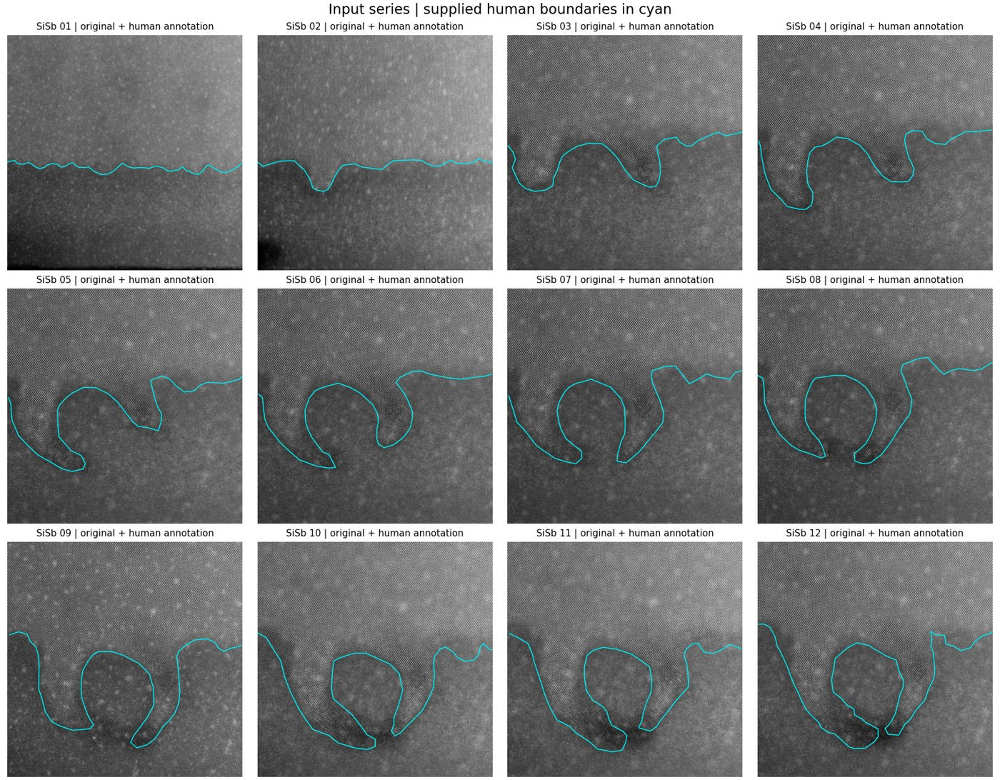

In [8]:
# Targeted metric checks: symmetry and empty predictions matter for this objective.
assert boundary_metrics([[0, 0], [0, 10]], [[0, 0]])["distance_px"] == 2.5
assert boundary_metrics([[0, 0]], [[0, 0]])["distance_px"] == 0
assert np.isinf(boundary_metrics([], [[0, 0]])["distance_px"])

def show_figures(paths):
    if isinstance(paths, (str, Path)):
        paths = [paths]
    import io
    from PIL import Image as PILImage
    for path in paths:
        with PILImage.open(path) as source:
            preview = source.convert("RGB")
            preview.thumbnail((1400, 2000))
            buffer = io.BytesIO()
            preview.save(buffer, format="JPEG", quality=85)
        display(Image(data=buffer.getvalue(), format="jpeg", width=1250))

sisb_files = sorted((DATA_DIR / "SiSb").glob("*.emd"))
if MAX_IMAGES is not None:
    sisb_files = sisb_files[:int(MAX_IMAGES)]
records = [dict(id=p.name[:2], image_path=str(p),
                human_path=str(DATA_DIR / "SiSb_ground_truth" / f"{p.stem}_ground_truth.npz"))
           for p in sisb_files]
if not records:
    raise FileNotFoundError("No SiSb images found.")
for record in records:
    shape = read_image(record["image_path"]).shape
    if any(n % CFG["coefficient_step"] for n in shape):
        raise ValueError("Image dimensions must be divisible by coefficient_step in this implementation.")
    if any(n % CFG[s] for n in shape for s in ["boundary_step", "field_step", "output_map_step"]):
        raise ValueError("Choose output spacings that divide the image dimensions.")
json_write(OUTPUT_DIR / "config.json", CFG)
json_write(OUTPUT_DIR / "records.json", records)
print(f"Analyzing {len(records)} images.")
show_figures(input_montage(records, OUTPUT_DIR))

## 6. Run the deterministic analysis for every image

This stage saves full latent reconstruction summaries and all peak-count boundary variants. The comparison loss uses boundaries represented on the same 4-pixel grid as the probabilistic comparison. Native-resolution deterministic distances are also retained as a separate diagnostic. Region IoU/Dice use the explicitly derived upper phase region.

In [9]:
deterministic_results = run_stage(
    records, lambda record: deterministic_analysis(record, CFG, OUTPUT_DIR),
    workers=CFG["max_workers"])
json_write(OUTPUT_DIR / "deterministic_index.json", deterministic_results)

deterministic_summary = pd.DataFrame([
    dict(image=i, reconstruction_r2=d["reconstruction_r2"], normalized_rmse=d["normalized_rmse"],
         valid_field_fraction=d["valid_field_fraction"], runtime_seconds=d["runtime_seconds"])
    for i, d in deterministic_results.items()])
deterministic_comparison = pd.DataFrame([
    dict(image=i, bragg_pairs=int(k), **metrics)
    for i, d in deterministic_results.items() for k, metrics in d["peak_count_metrics"].items()])
deterministic_summary.to_csv(OUTPUT_DIR / "deterministic_summary.csv", index=False)
deterministic_comparison.to_csv(OUTPUT_DIR / "deterministic_boundary_comparison.csv", index=False)
display(deterministic_summary.round(4))
display(deterministic_comparison.groupby("bragg_pairs")[["distance_px", "native_distance_px", "region_iou", "f1"]].mean().round(4))

Image 01: deterministic latent field
Image 02: deterministic latent field
Image 01: deterministic complete
Image 02: deterministic complete
Image 03: deterministic latent field
Image 04: deterministic latent field
Image 03: deterministic complete
Image 05: deterministic latent field
Image 04: deterministic complete
Image 06: deterministic latent field
Image 05: deterministic complete
Image 06: deterministic complete
Image 07: deterministic latent field
Image 08: deterministic latent field
Image 08: deterministic complete
Image 07: deterministic complete
Image 09: deterministic latent field
Image 10: deterministic latent field
Image 09: deterministic complete
Image 11: deterministic latent field
Image 10: deterministic complete
Image 12: deterministic latent field
Image 11: deterministic complete
Image 12: deterministic complete


,image,reconstruction_r2,normalized_rmse,valid_field_fraction,runtime_seconds
0,01,0.6659,0.5780,0.5327,145.2036
1,02,0.5751,0.6518,0.5232,145.3455
2,03,0.4601,0.7348,0.4646,152.1514
3,04,0.4699,0.7281,0.4501,153.9434
4,05,0.4816,0.7200,0.4264,141.5359
5,06,0.4879,0.7156,0.4020,139.6864
6,07,0.4887,0.7151,0.3840,148.3858
7,08,0.4791,0.7217,0.3552,148.2140
8,09,0.4297,0.7552,0.4508,140.1891
9,10,0.4102,0.7680,0.5394,145.3066


,distance_px,native_distance_px,region_iou,f1
bragg_pairs,,,,
2,66.7930,66.5636,0.8732,0.0324
4,69.9050,69.8219,0.8740,0.0342
8,60.2611,61.0024,0.8870,0.0893
12,71.8498,75.9022,0.8881,0.1306


### Deterministic reconstructions and all physical-field components

For each image the first figure shows prediction, residual, an atomic-resolution crop, and selected FFT peaks. The second shows combined amplitude, displacement, all in-plane strain components, rotation, phase consistency, and human/model segmentation. Shaded regions and original annotations retain their original geometry, including overhangs.

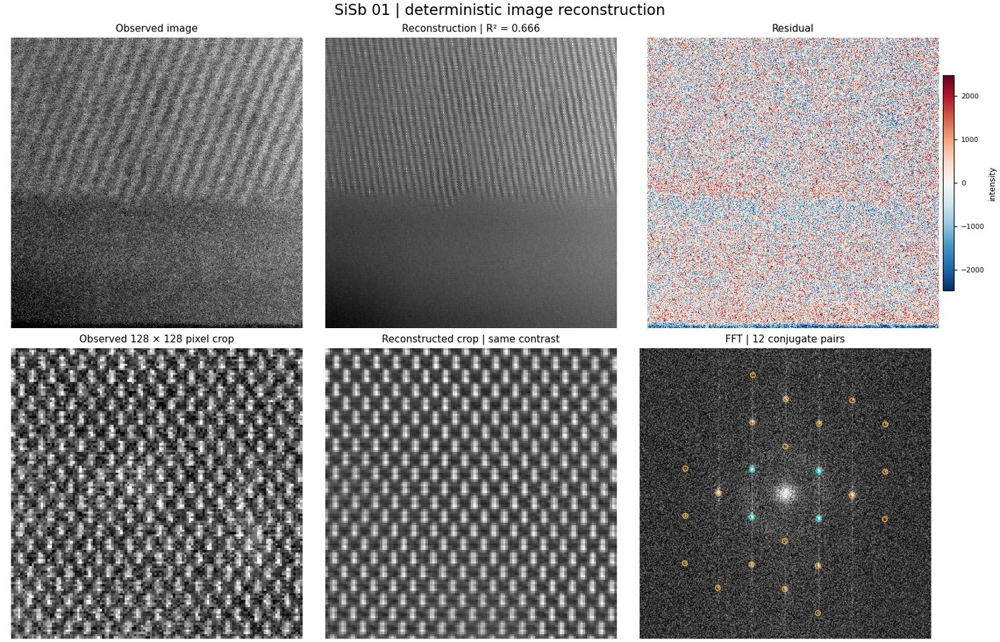

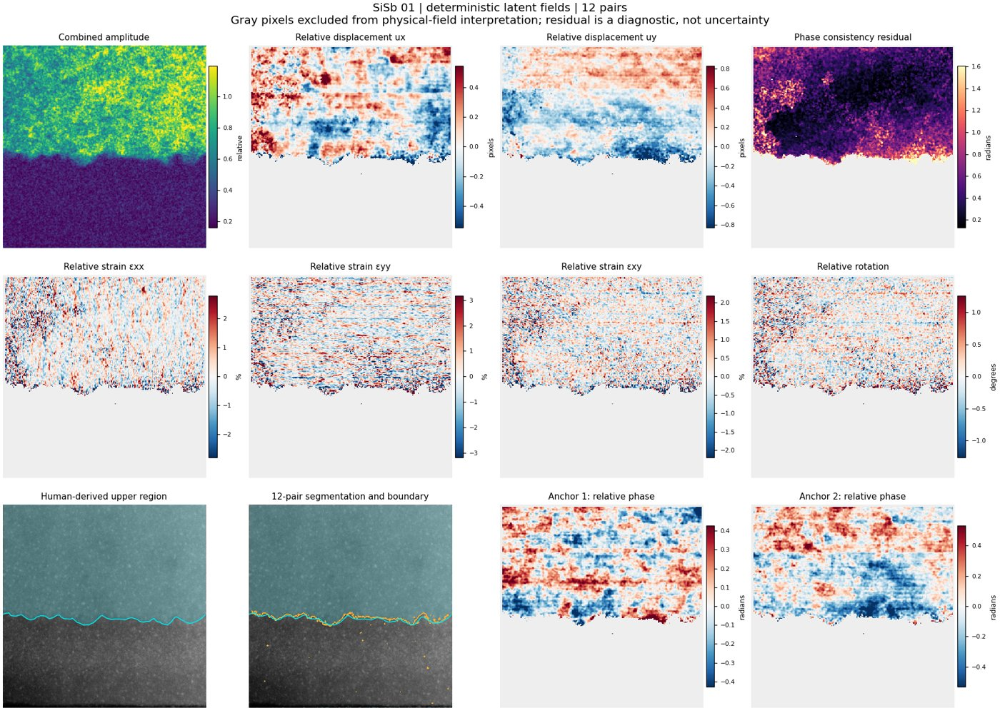

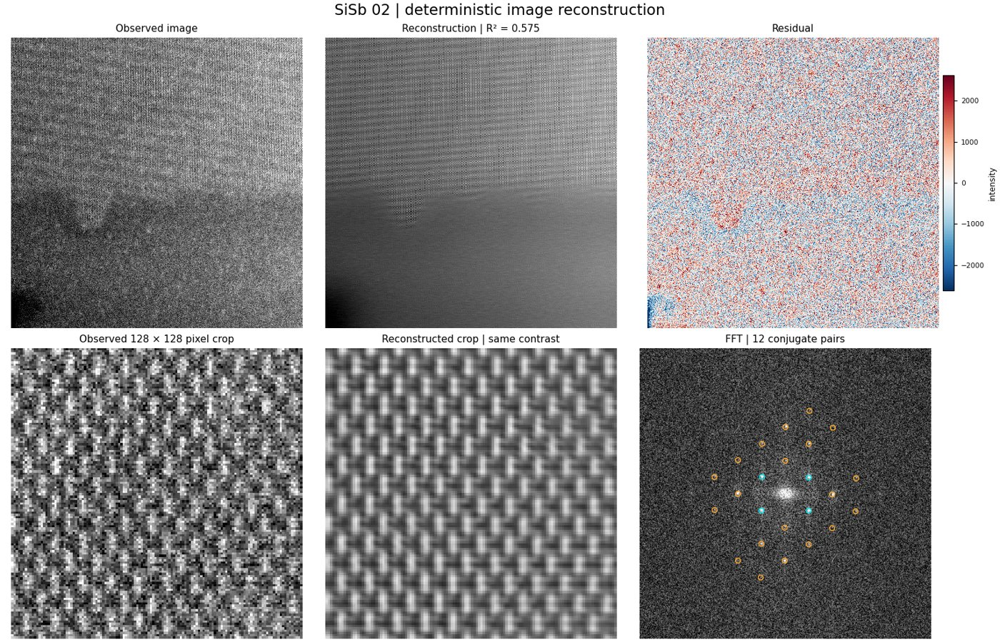

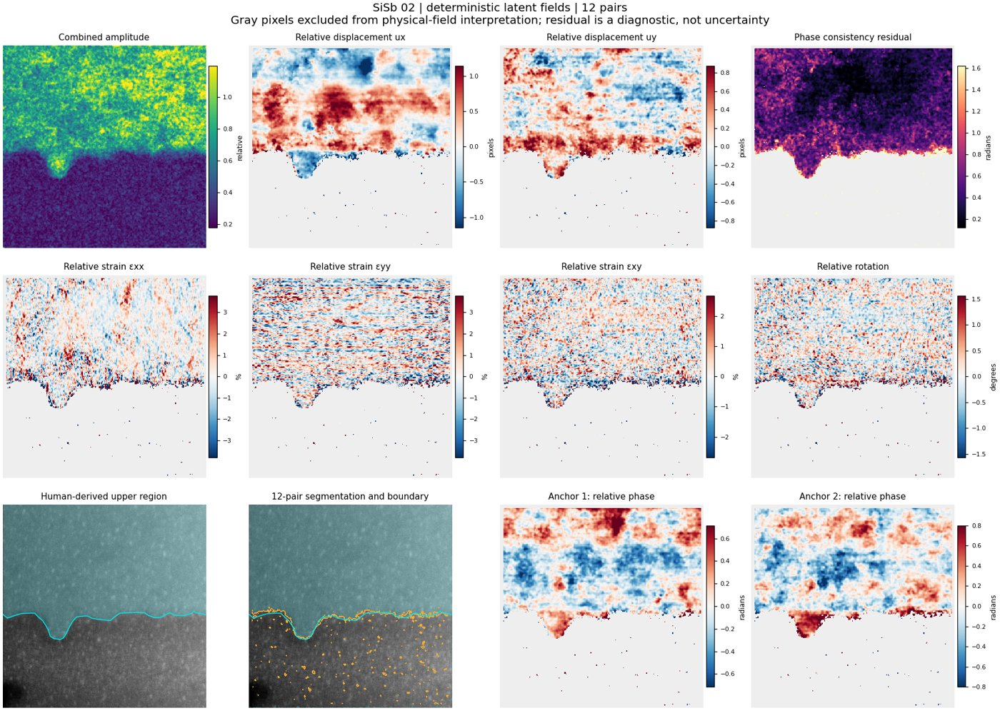

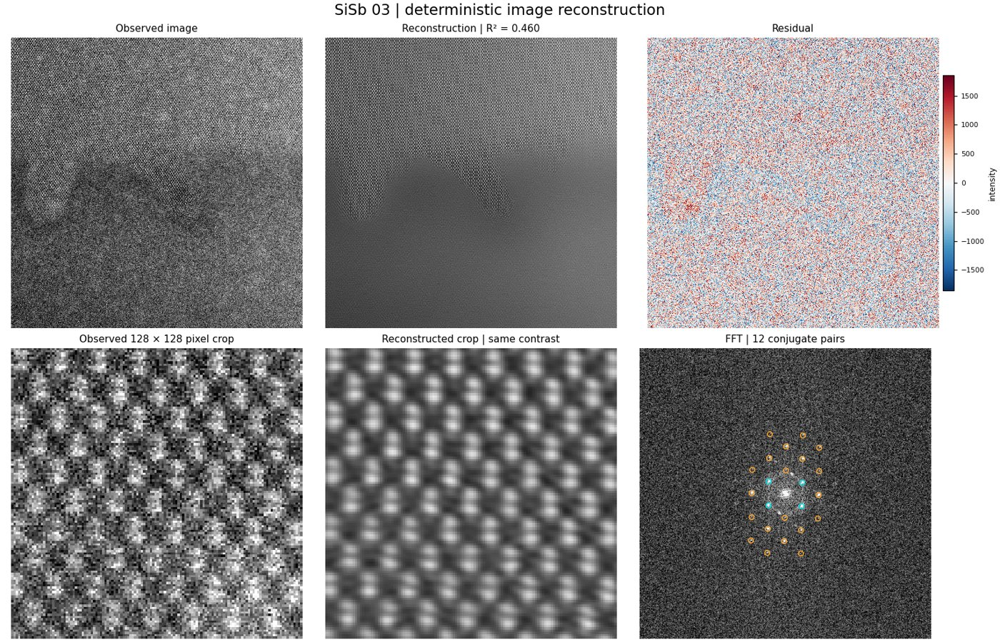

...

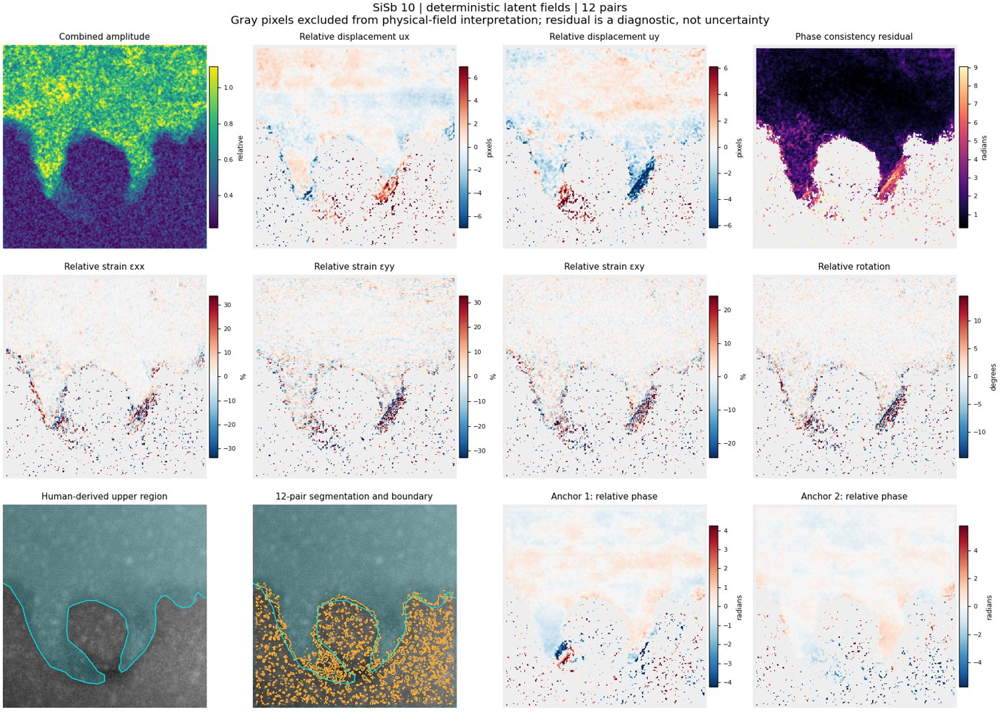

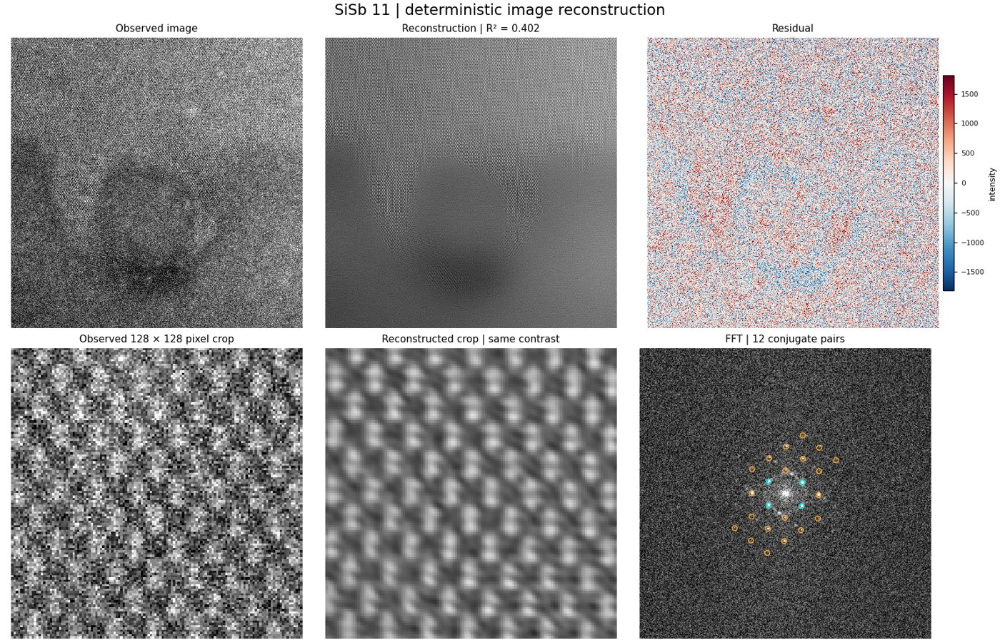

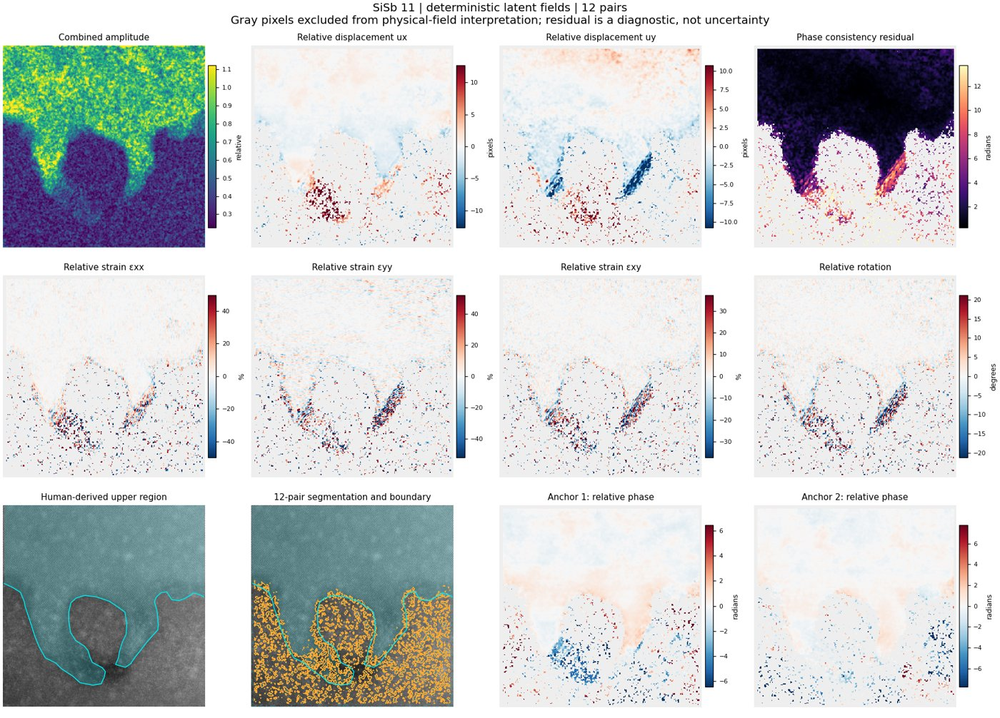

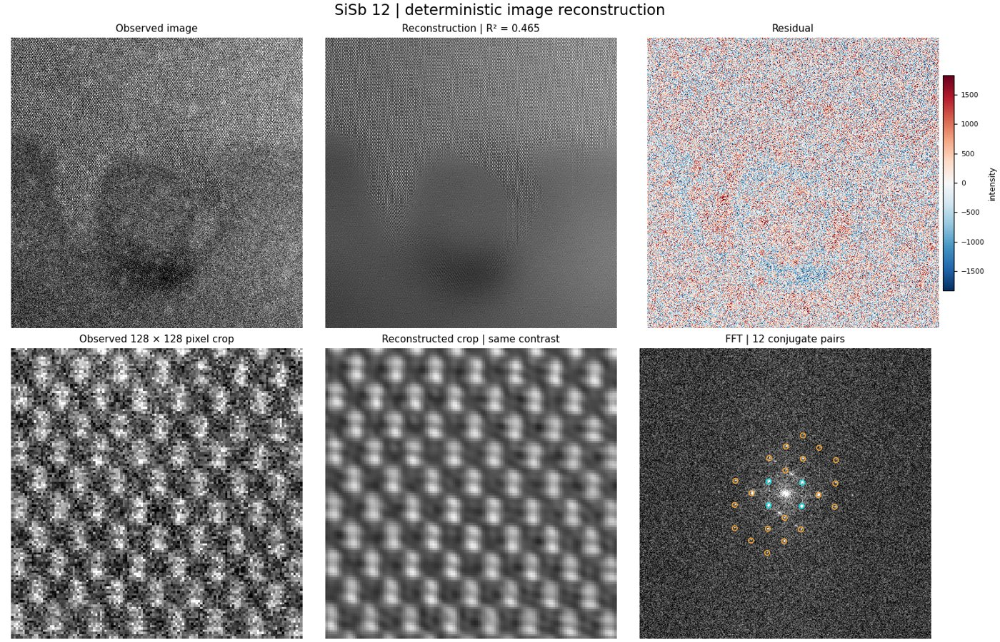

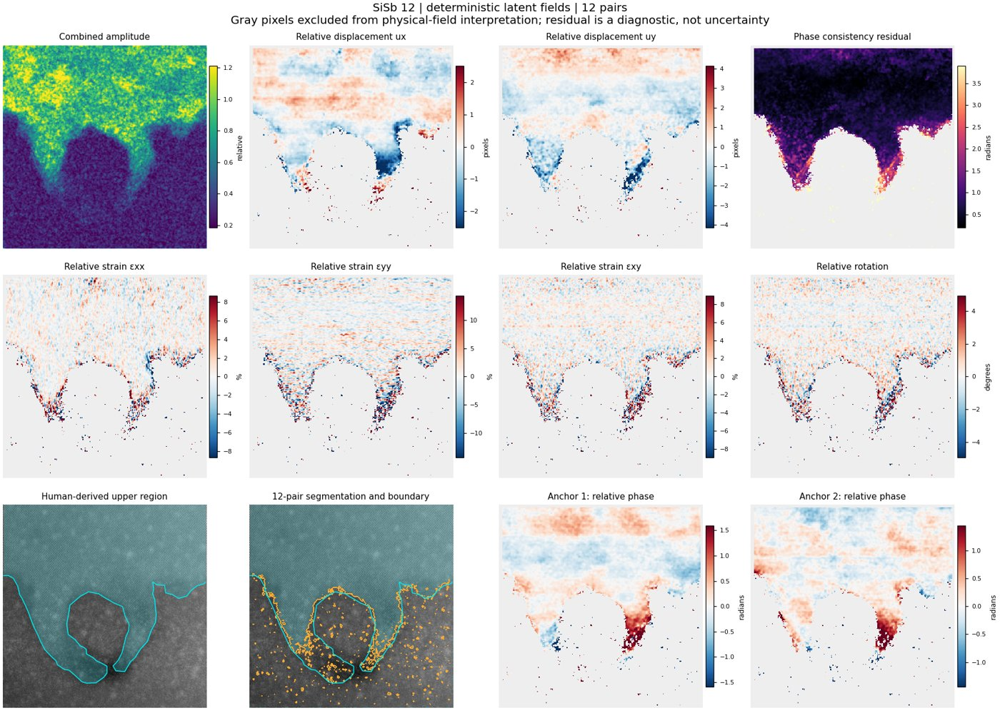

In [10]:
for record in records:
    show_figures(deterministic_figures(record, deterministic_results[record["id"]], CFG, OUTPUT_DIR))

### Deterministic segmentation at every peak count

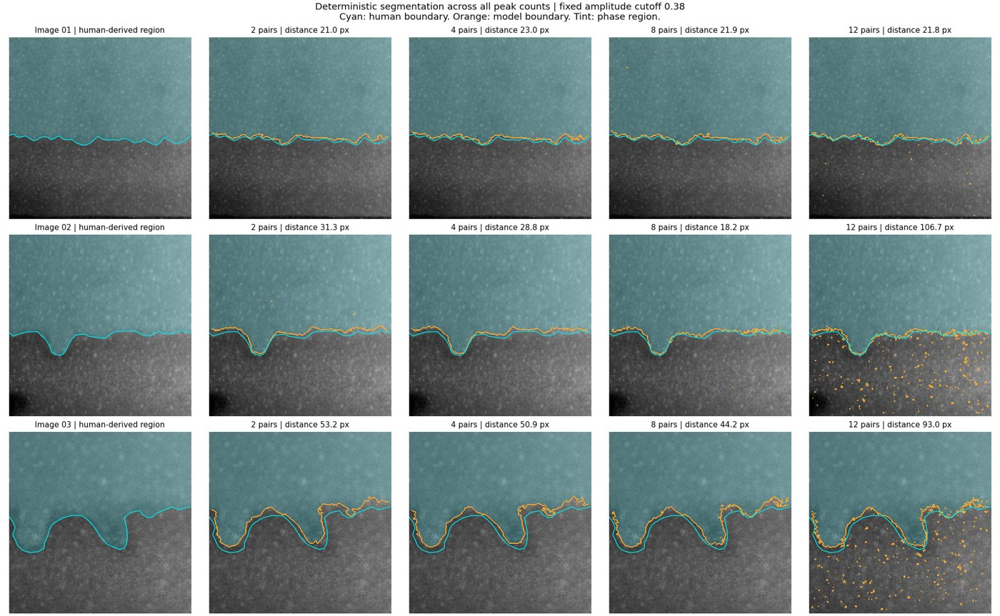

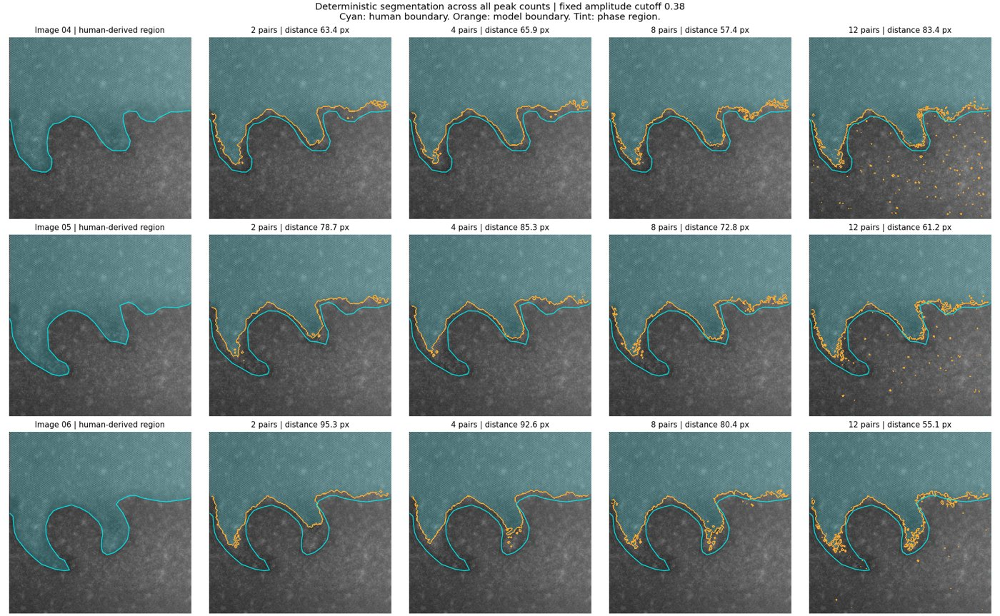

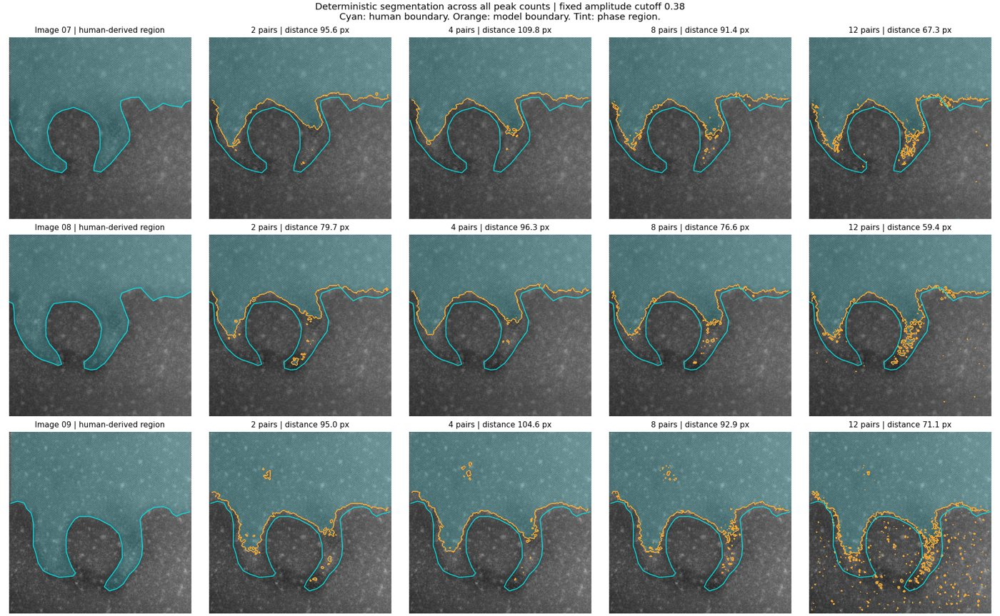

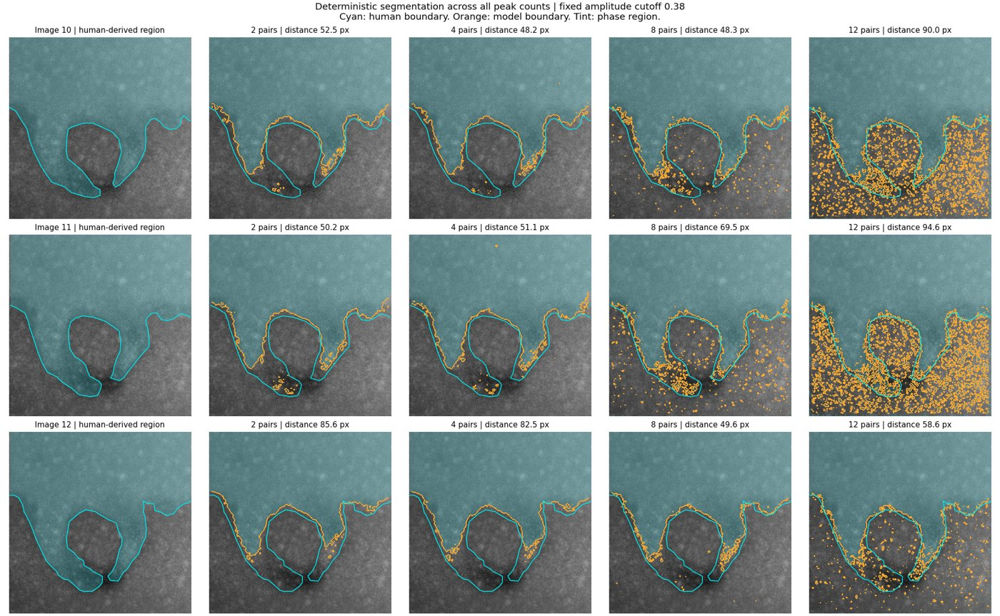

,image,mode,q_x_bin,q_y_bin,period_px,peak_to_local_background
0,01,1,233.0,171.0,7.0861,144.6482
1,01,2,235.0,-163.0,7.1609,132.3040
2,01,3,469.0,8.0,4.3661,105.6213
3,01,4,231.0,504.0,3.6940,71.8978
4,01,5,4.0,-668.0,3.0658,65.3118
...,...,...,...,...,...,...
139,12,8,353.0,-75.0,5.6750,14.6507
140,12,9,241.0,-326.0,5.0517,14.0531
141,12,10,3.0,-167.0,12.2615,8.8868
142,12,11,357.0,-240.0,4.7609,11.2170


In [11]:
show_figures(segmentation_pages(records, deterministic_results, None, None, CFG, OUTPUT_DIR, "deterministic"))
peak_table = pd.DataFrame([
    dict(image=i, mode=m["mode"], q_x_bin=m["q"][0], q_y_bin=m["q"][1],
         period_px=m["period_px"], peak_to_local_background=m["peak_to_local_background"])
    for i, d in deterministic_results.items() for m in d["mode_summary"]])
peak_table.to_csv(OUTPUT_DIR / "selected_fft_peaks.csv", index=False)
display(peak_table.round(4))

## 7. Repeat with probabilistic latent fields

Each candidate is fitted separately. For every posterior draw we extract a phase boundary, form its distance map, and accumulate the boundary-location probability. Every probability threshold gets a direct symmetric-distance comparison with the human boundary.

The largest-count model receives the complete prediction-uncertainty and physical-field report in this stage. After the series decision, the selected model also receives the complete physical-field uncertainty report if it differs. This keeps the expensive image-prediction uncertainty calculation focused while retaining coefficient samples for every candidate.

Checkpoint messages may interleave when two images run concurrently. Rerunning completed models reads their saved outputs. The reconstruction R² values below are in-sample descriptive fits; they are not held-out uncertainty-calibration tests.

In [12]:
probabilistic_results = run_stage(
    records, lambda record: probabilistic_analysis(record, deterministic_results[record["id"]], CFG, OUTPUT_DIR),
    workers=CFG["max_workers"])
json_write(OUTPUT_DIR / "probabilistic_index.json", probabilistic_results)

probabilistic_summary = pd.DataFrame([
    dict(image=i, bragg_pairs=int(k), reconstruction_r2=m["reconstruction_r2"],
         local_threshold=m["local_optimum"]["threshold"], local_distance_px=m["local_optimum"]["distance_px"],
         physical_status=m["physical_status"])
    for i, d in probabilistic_results.items() for k, m in d["models"].items()])
probabilistic_summary.to_csv(OUTPUT_DIR / "probabilistic_summary.csv", index=False)
display(probabilistic_summary.round(4))

Image 01: probabilistic model with 12 pairs
Image 02: probabilistic model with 12 pairs
Likelihood blocks 1024/4096
Likelihood blocks 1024/4096
Likelihood blocks 2048/4096
Likelihood blocks 2048/4096
Likelihood blocks 3072/4096
Likelihood blocks 3072/4096
Likelihood blocks 4096/4096
Likelihood blocks 4096/4096
Posterior mean solved: 26 CG iterations
Posterior mean solved: 26 CG iterations
Posterior mean solved: 23 CG iterations
Factoring local likelihood blocks for posterior sampling
Posterior mean solved: 24 CG iterations
Factoring local likelihood blocks for posterior sampling
Posterior draws 8/64; CG iterations 19
Posterior draws 8/64; CG iterations 20
Posterior draws 16/64; CG iterations 19
Posterior draws 16/64; CG iterations 20
Posterior draws 24/64; CG iterations 19
Posterior draws 24/64; CG iterations 20
Posterior draws 32/64; CG iterations 19
Posterior draws 32/64; CG iterations 20
Posterior draws 40/64; CG iterations 19
Posterior draws 40/64; CG iterations 20
Posterior draws 

,image,bragg_pairs,reconstruction_r2,local_threshold,local_distance_px,physical_status
0,01,12,0.6488,0.8281,14.3515,ok
1,01,8,0.6465,0.9375,20.5089,available in coefficient checkpoint; computed ...
2,01,4,0.6283,0.5156,22.2256,available in coefficient checkpoint; computed ...
3,01,2,0.5620,0.4375,20.6795,available in coefficient checkpoint; computed ...
4,02,12,0.5632,0.9375,15.4500,ok
5,02,8,0.5610,0.5312,17.6851,available in coefficient checkpoint; computed ...
6,02,4,0.5510,0.2812,27.3503,available in coefficient checkpoint; computed ...
7,02,2,0.5003,1.0000,28.8306,available in coefficient checkpoint; computed ...
8,03,12,0.4292,0.7344,33.6307,ok
9,03,8,0.4263,0.8281,45.2927,available in coefficient checkpoint; computed ...


### Prediction, uncertainty, amplitude and physical fields for every image

Each image gets a prediction/crop/uncertainty figure and a complete physical-field figure. Latent-mean SD describes uncertainty in the modeled signal; predictive SD additionally includes the estimated observation residual. Field SD includes the documented phase-discrepancy contribution where identifiable. The regular modulation associated with the coefficient grid is a representation artifact; it should not be interpreted as a periodic physical boundary.

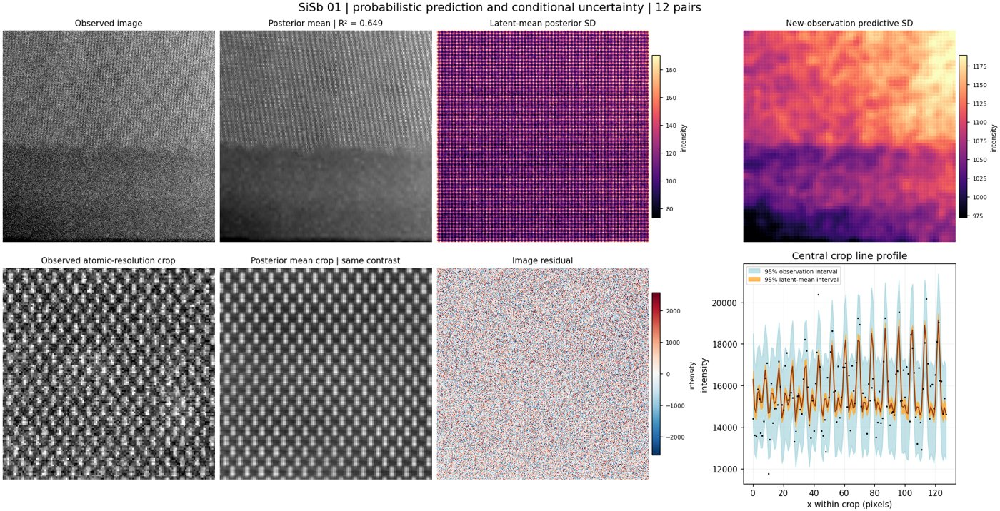

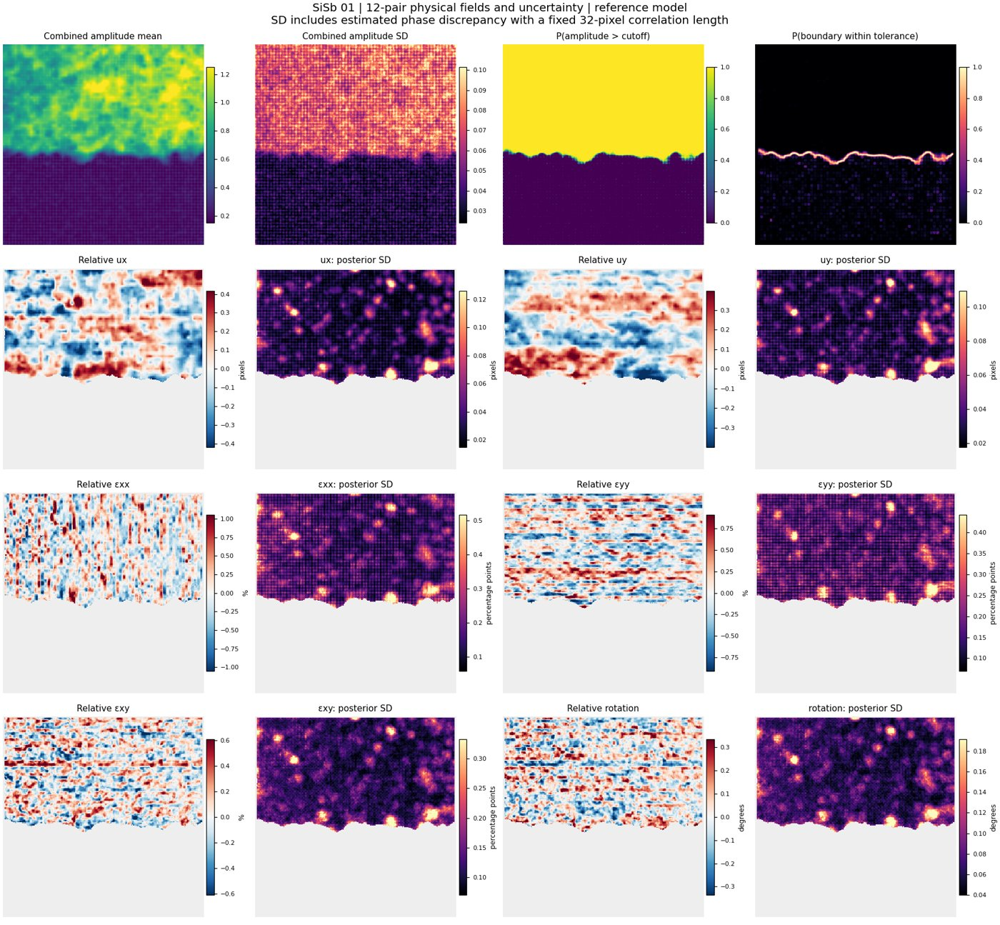

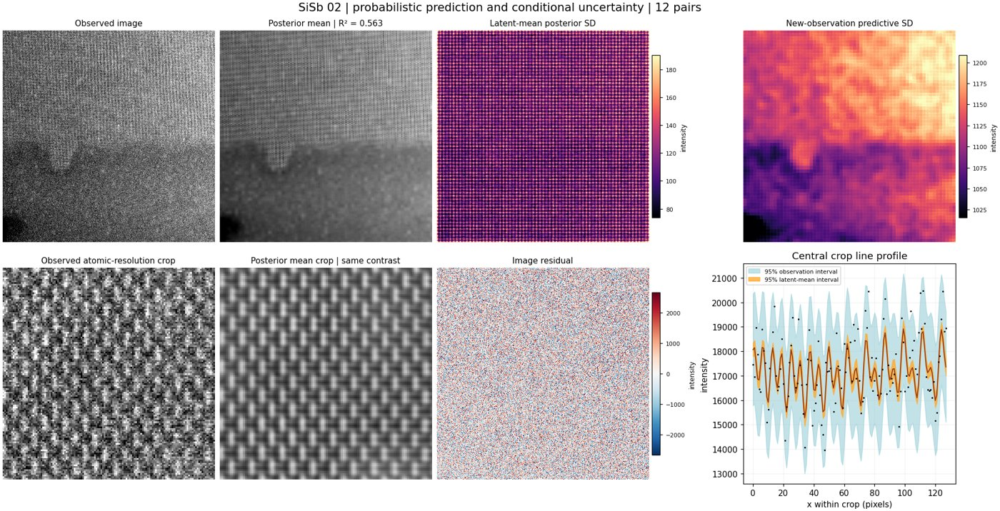

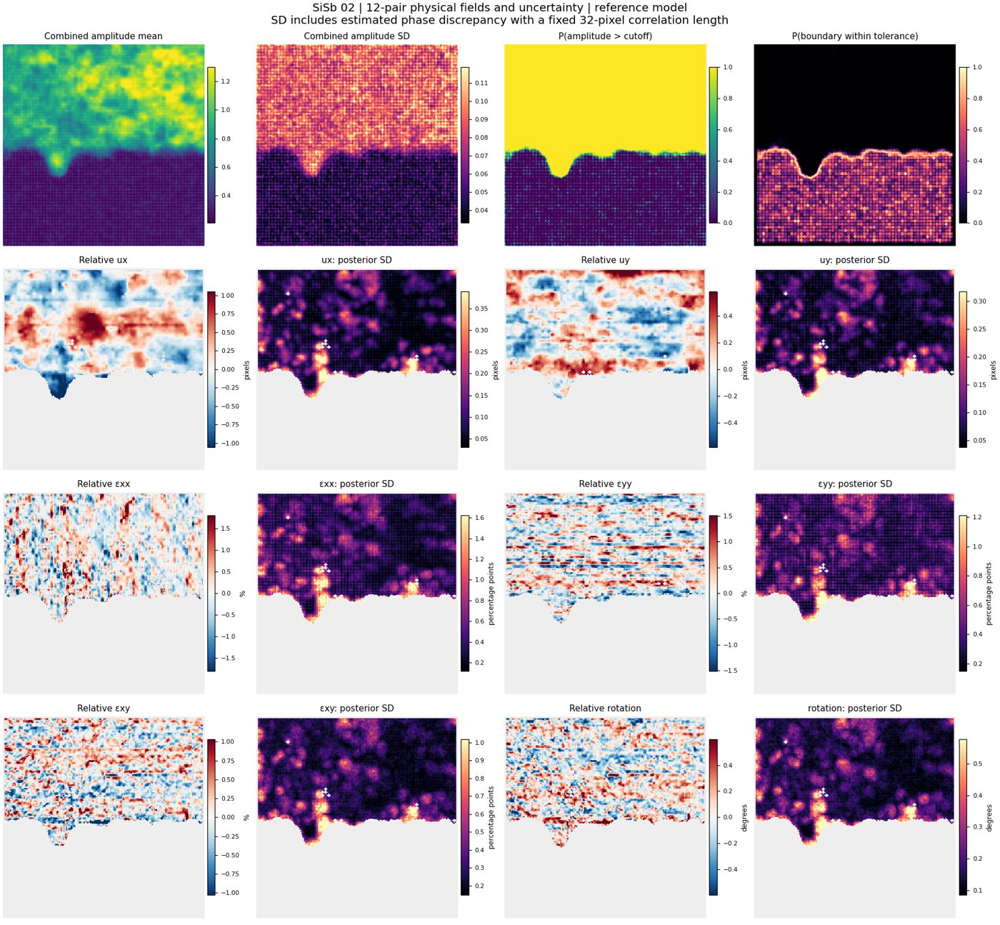

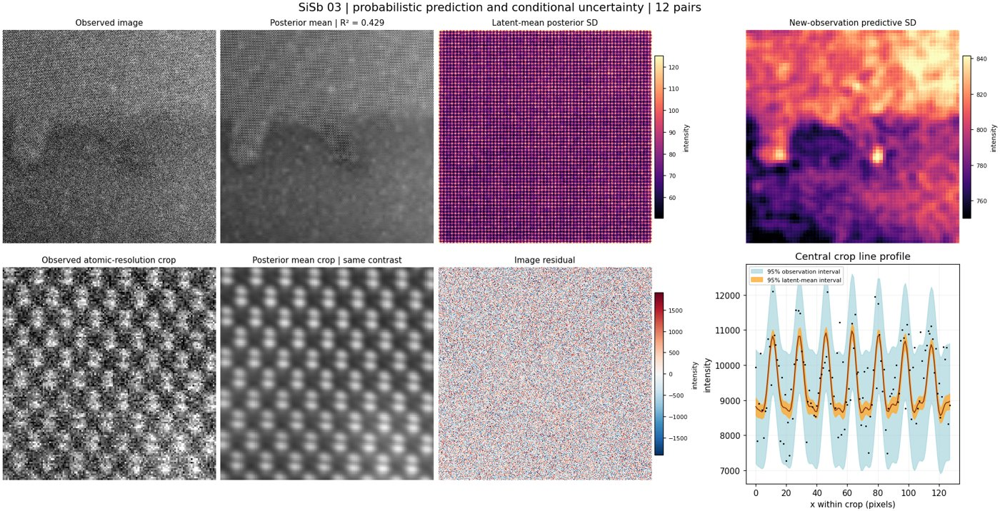

...

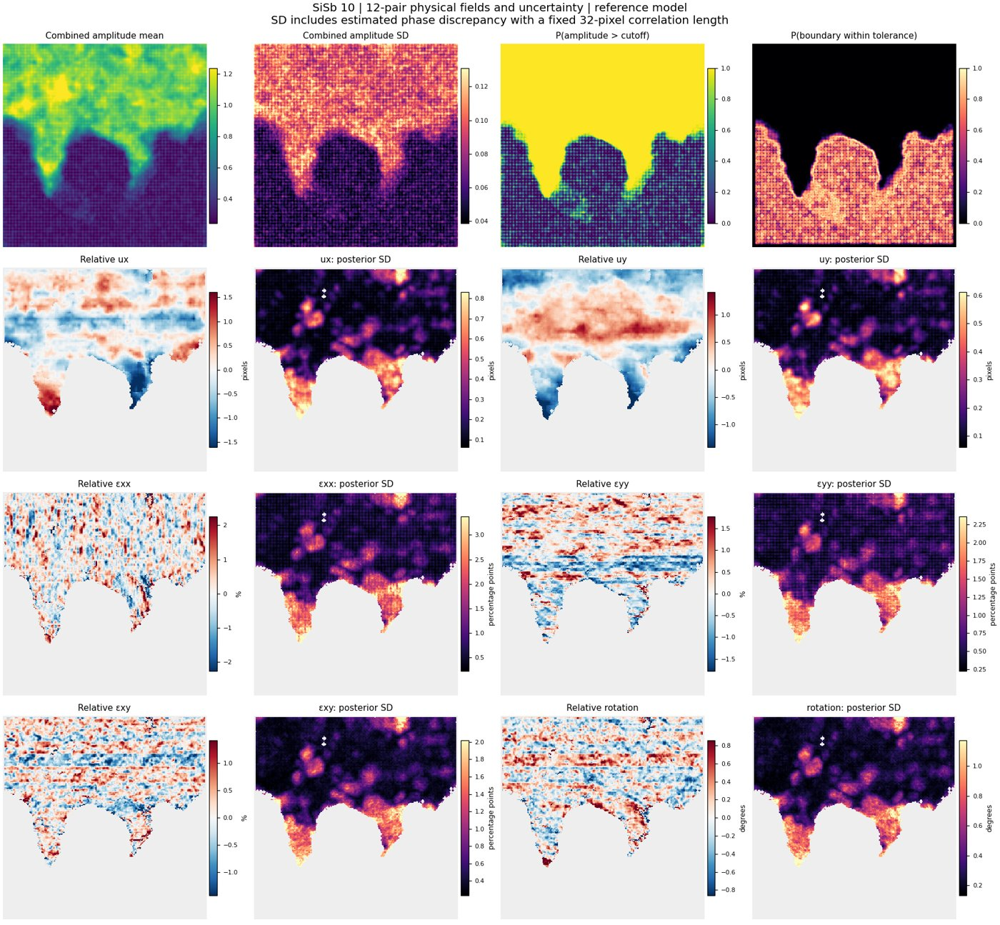

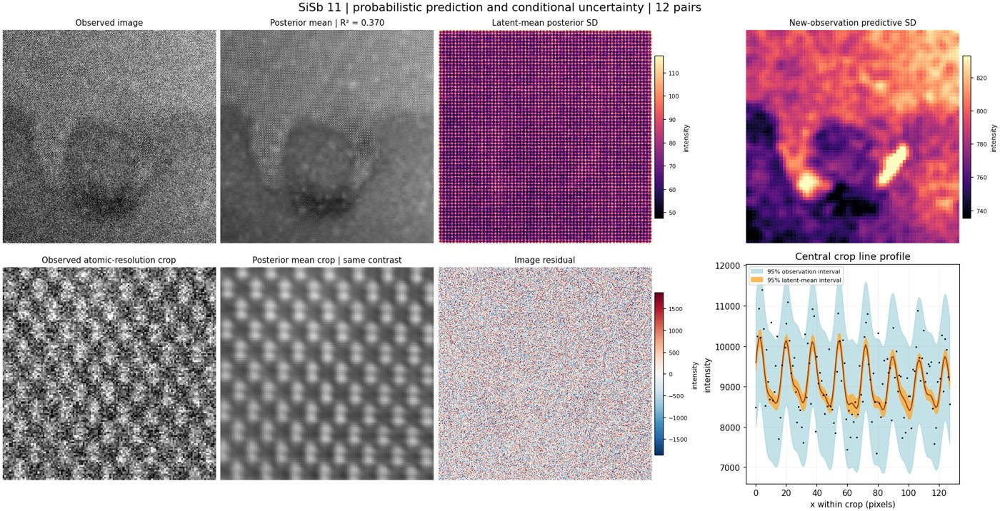

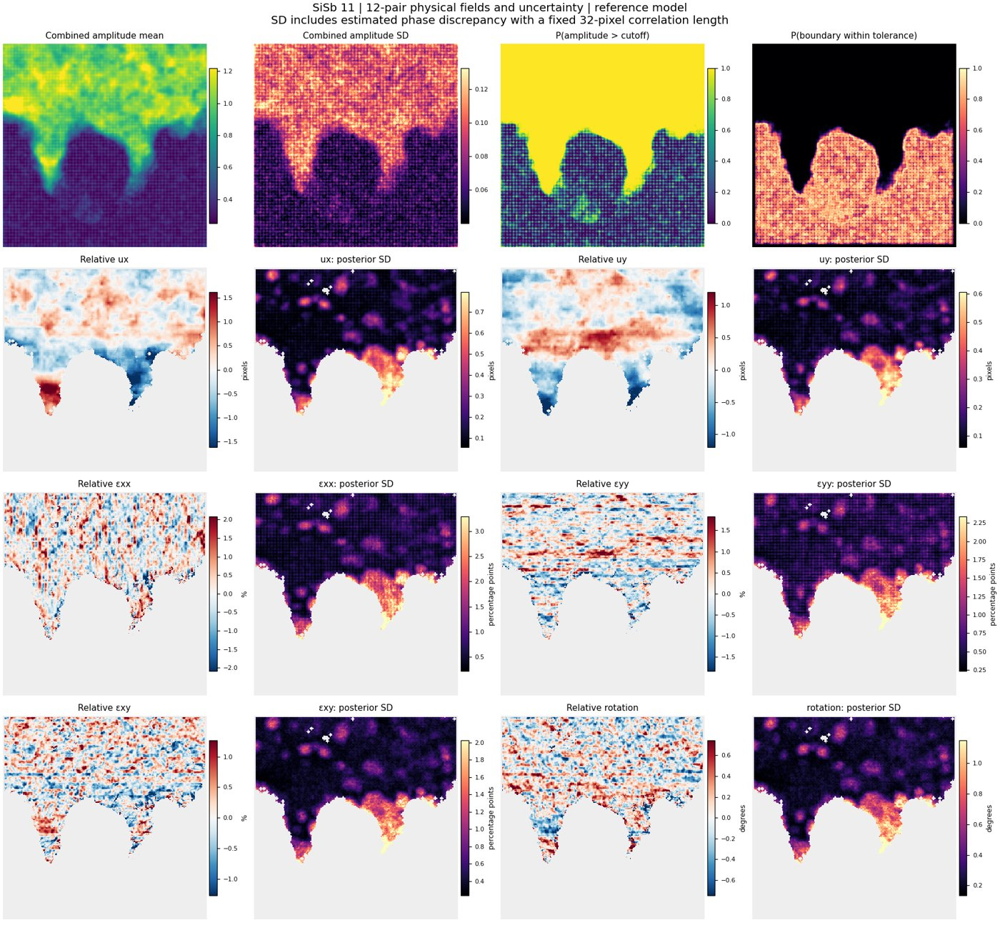

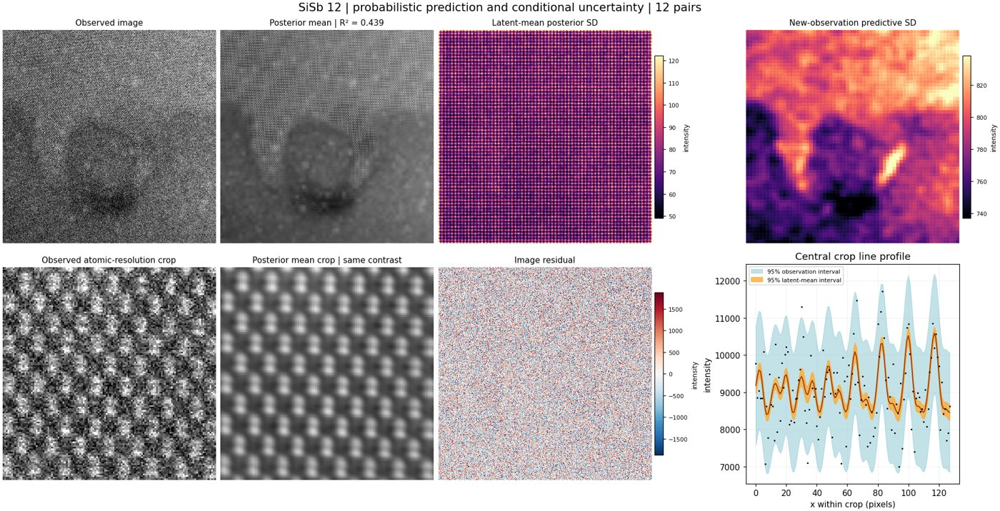

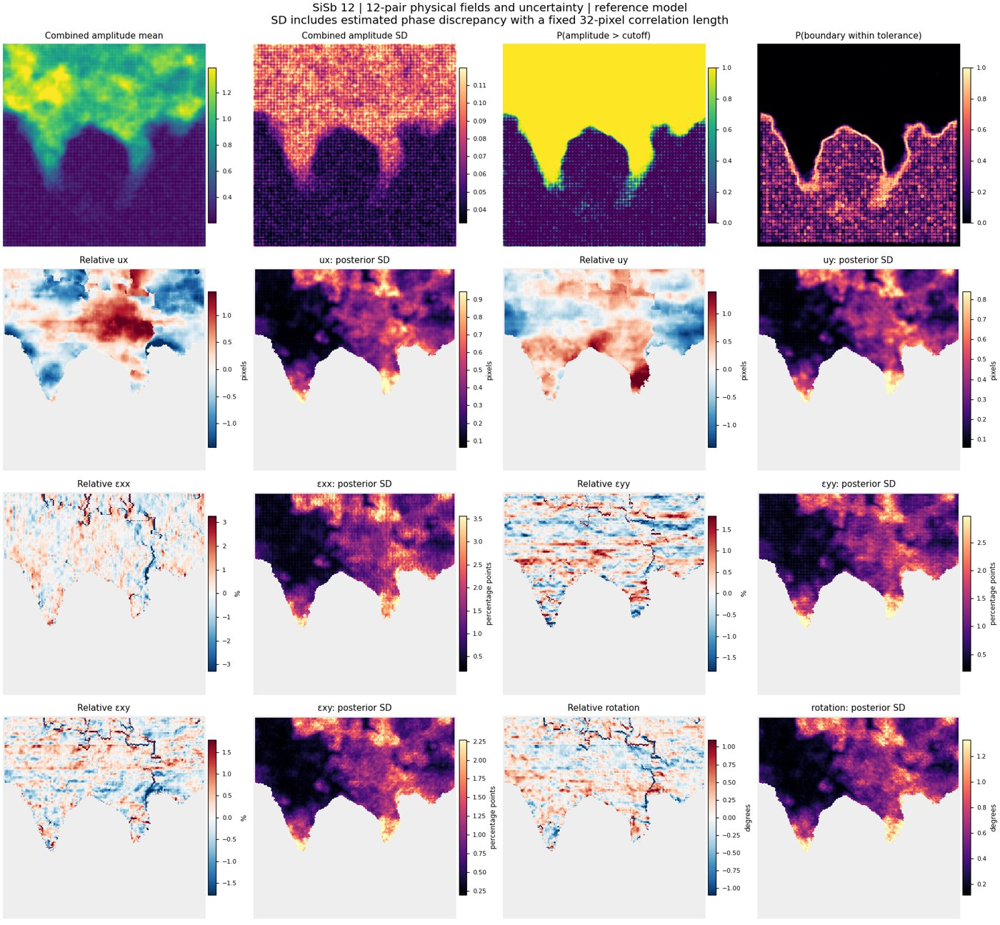

In [13]:
for record in records:
    show_figures(probabilistic_figures(record, probabilistic_results[record["id"]], CFG, OUTPUT_DIR))

## 8. Select one peak count and probability threshold across the whole series

This cell averages \(D_i(K,t)\) over complete images and selects the lowest mean. Exact ties prefer fewer Bragg pairs, then a threshold closer to 0.5, then the smaller threshold. The per-image optimum is also reported, but it does not replace the common setting when comparing the series.

**Leave-one-image-out check:** for each image, choose both parameters using all other annotations and score that excluded annotation once. Intensity modeling remains unsupervised with respect to annotations. These are related frames, so this check does not establish transfer to independent specimens or experiments.

{
  "selected_bragg_pairs": 2,
  "selected_probability_threshold": 0.046875,
  "objective": "unweighted mean symmetric boundary distance across complete images",
  "mean_distance_px": 58.99338802343897,
  "median_distance_px": 63.856951212828776,
  "max_distance_px": 78.85136642780999,
  "images": 12,
  "mean_deterministic_distance_px": 66.79303866339328,
  "mean_loo_distance_px": 66.95926707750884,
  "selection_scope": "all annotated images; optimum within the tested K and threshold grid",
  "validation_scope": "leave-one-image-out annotation selection; related frames can remain correlated"
}


,image,shared_bragg_pairs,shared_threshold,shared_distance_px,local_bragg_pairs,local_threshold,local_distance_px,deterministic_distance_px,deterministic_max_pairs_distance_px,shared_precision,shared_recall,shared_f1,shared_hausdorff95_px
0,01,2,0.0469,21.3128,12,0.8281,14.3515,21.0129,21.8242,0.1119,0.1331,0.1216,38.5251
1,02,2,0.0469,45.9433,12,0.9375,15.4500,31.3302,106.7161,0.1031,0.1383,0.1181,370.4672
2,03,2,0.0469,50.5902,12,0.7344,33.6307,53.2187,92.9672,0.0053,0.0133,0.0076,102.6896
3,04,2,0.0469,62.7298,12,0.7031,46.5322,63.3856,83.4218,0.0009,0.0012,0.0011,124.8569
4,05,2,0.0469,66.7761,12,0.3281,51.6888,78.7294,61.1681,0.0059,0.0147,0.0084,139.2344
5,06,2,0.0469,75.6496,12,0.2500,54.4230,95.2739,55.1057,0.0209,0.0203,0.0206,263.9564
6,07,2,0.0469,78.8514,12,0.1250,63.9101,95.5742,67.2763,0.0010,0.0005,0.0006,180.2331
7,08,2,0.0469,66.1273,12,0.2344,58.3386,79.7329,59.3608,0.0045,0.0040,0.0042,125.1191
8,09,2,0.0469,75.1101,12,0.5312,60.4306,95.0334,71.1375,0.0271,0.1008,0.0428,477.7445
9,10,2,0.0469,55.4430,8,0.4062,40.2349,52.4598,90.0180,0.0598,0.1355,0.0830,362.9849


,held_out_image,selected_bragg_pairs,selected_threshold,training_mean_distance_px,held_out_distance_px
0,01,2,0.0469,62.4189,21.3128
1,02,2,0.0469,60.1798,45.9433
2,03,2,0.0469,59.7573,50.5902
3,04,2,0.0469,58.6537,62.7298
4,05,2,0.2500,57.0956,83.5432
5,06,2,0.2656,57.2155,82.0401
6,07,12,0.8750,56.2211,91.8643
7,08,12,0.8750,57.3356,79.6046
8,09,2,0.0469,57.5282,75.1101
9,10,12,0.8750,58.2429,69.6245


,bragg_pairs,threshold,mean_distance_px,median_distance_px,max_distance_px,images
0,2,0.0469,58.9934,63.8570,78.8514,12
1,4,0.0625,61.7611,66.2206,83.6593,12
2,8,0.4531,61.7207,58.7797,102.3725,12
3,12,0.8750,59.1914,67.6094,91.8643,12


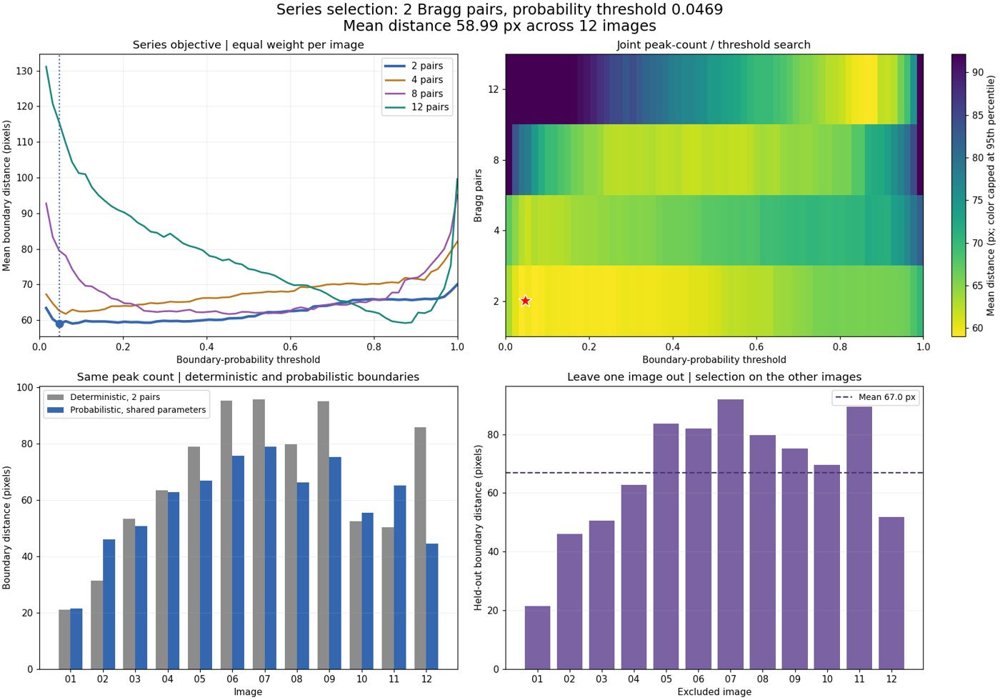

In [14]:
series_selection, distance_table, parameter_grid, per_image_comparison, loo_results = select_series_parameters(
    records, deterministic_results, probabilistic_results, CFG, OUTPUT_DIR)

print(json.dumps(series_selection, indent=2))
display(per_image_comparison.round(4))
display(loo_results.round(4))
best_by_count = parameter_grid.sort_values(["mean_distance_px", "threshold"]).groupby("bragg_pairs").first().reset_index()
best_by_count.to_csv(OUTPUT_DIR / "best_shared_threshold_by_peak_count.csv", index=False)
display(best_by_count.round(4))
show_figures(series_summary_figure(series_selection, distance_table, parameter_grid,
                                 per_image_comparison, loo_results, CFG, OUTPUT_DIR))

## 9. Every image: probability, selected boundary and all threshold curves

Each figure shows the boundary-location probability for the shared peak count, its selected boundary against the human annotation, and all distance-versus-threshold curves. Dots on individual curves indicate their per-image minima. The vertical dotted line and large marker show the parameters selected across the complete series. All distances use complete boundaries inside the fixed image margin.

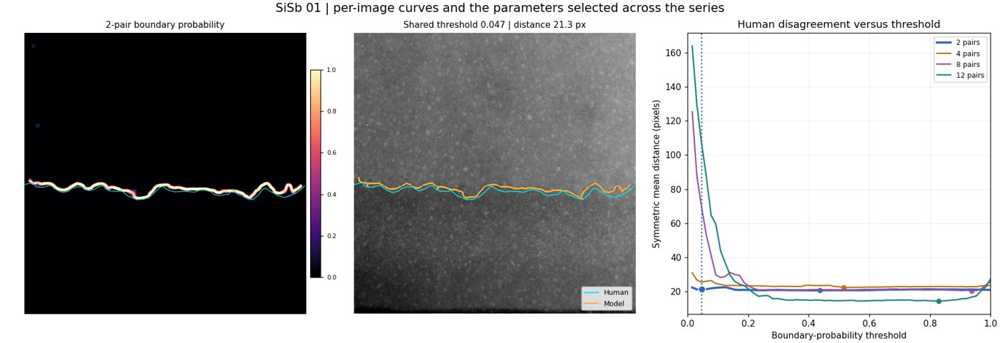

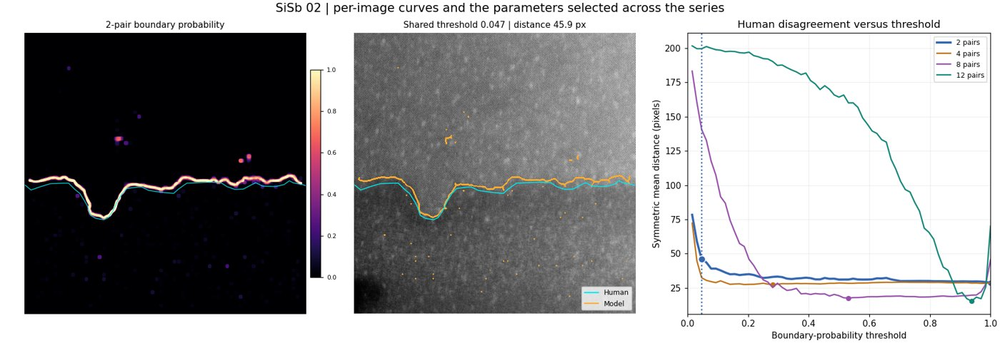

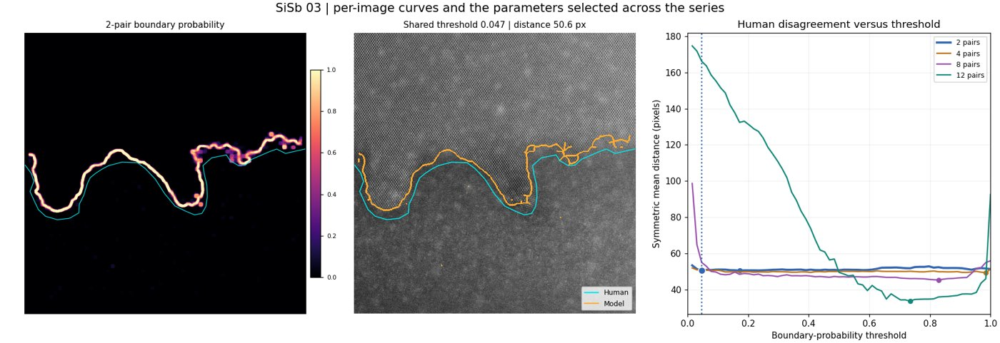

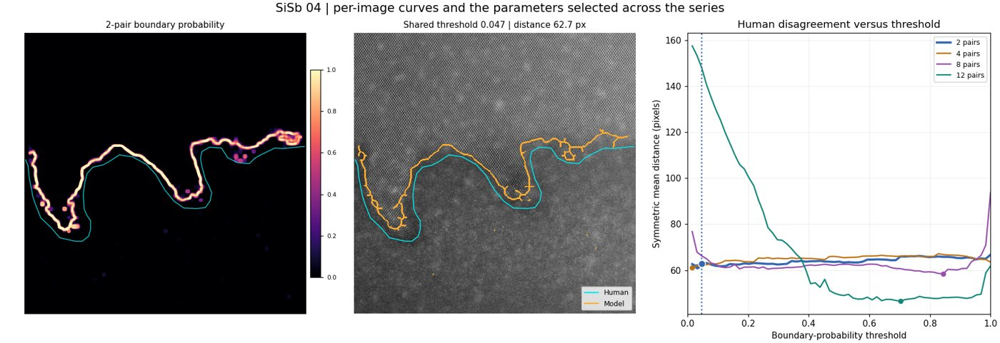

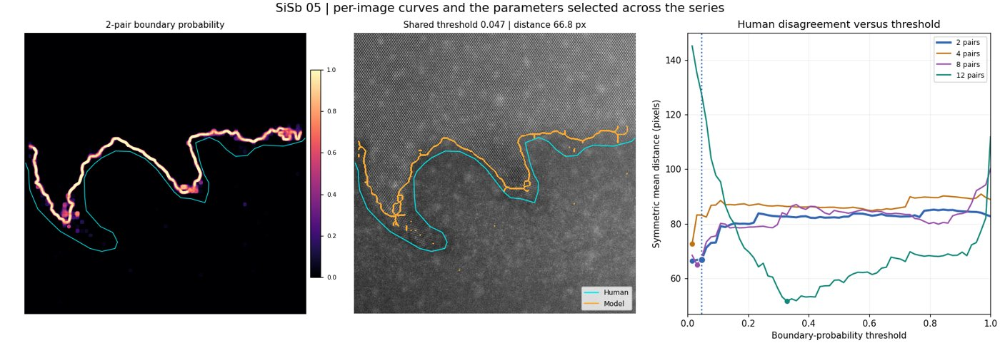

...

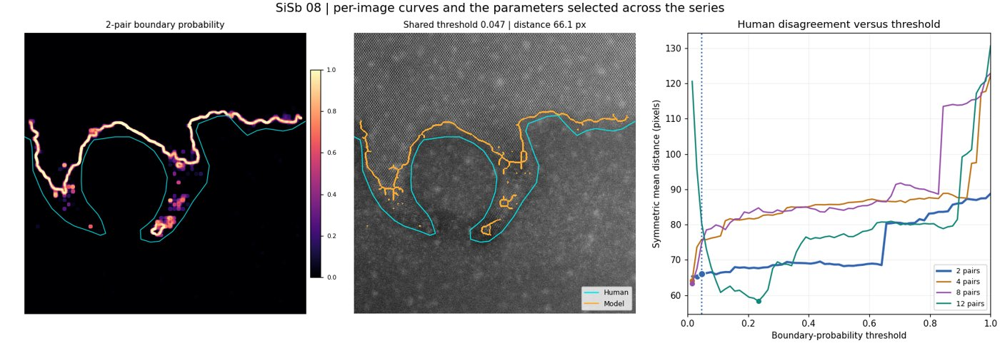

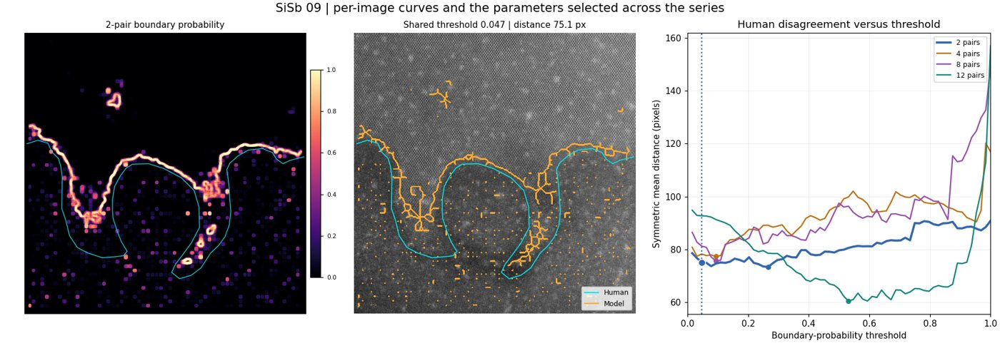

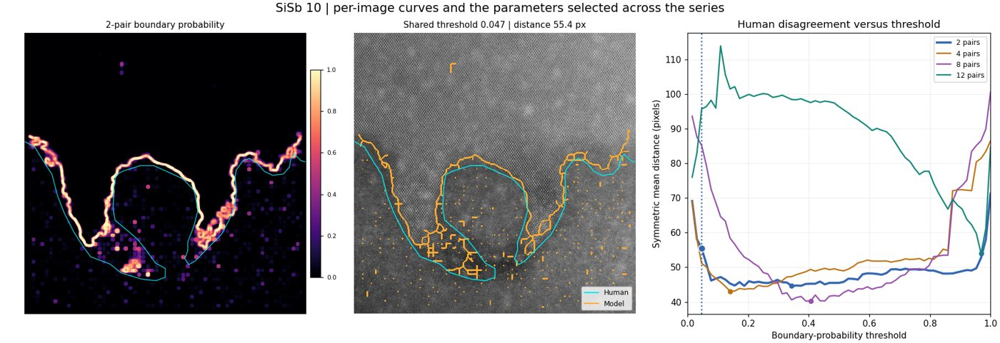

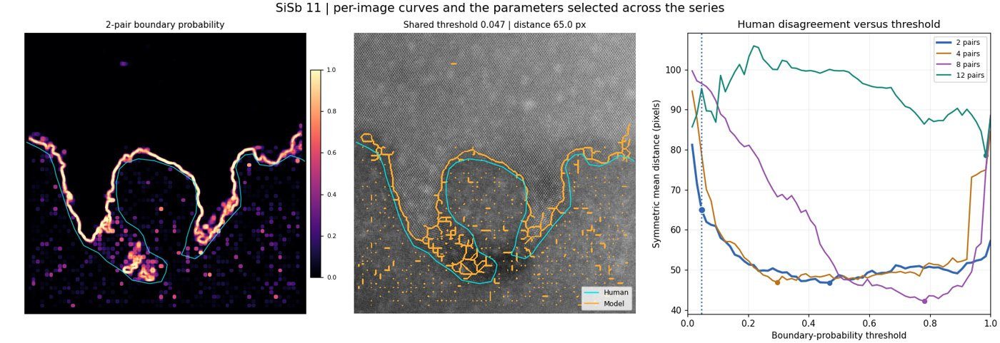

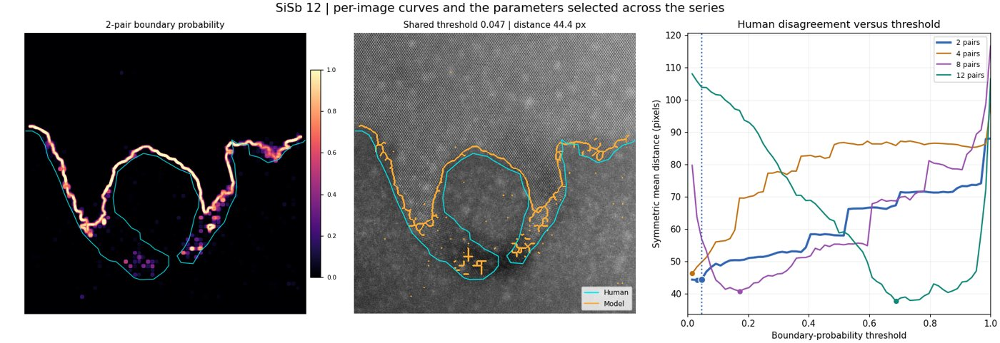

In [15]:
show_figures(per_image_distance_figures(records, probabilistic_results, series_selection,
                                      distance_table, CFG, OUTPUT_DIR))

### Compare every probabilistic peak count at the common threshold

The orange boundary is obtained from the boundary-location probability using the common threshold. The translucent phase tint separately represents phase probability ≥0.5. The tint and selected boundary therefore encode different probabilistic events; they need not share an identical contour.

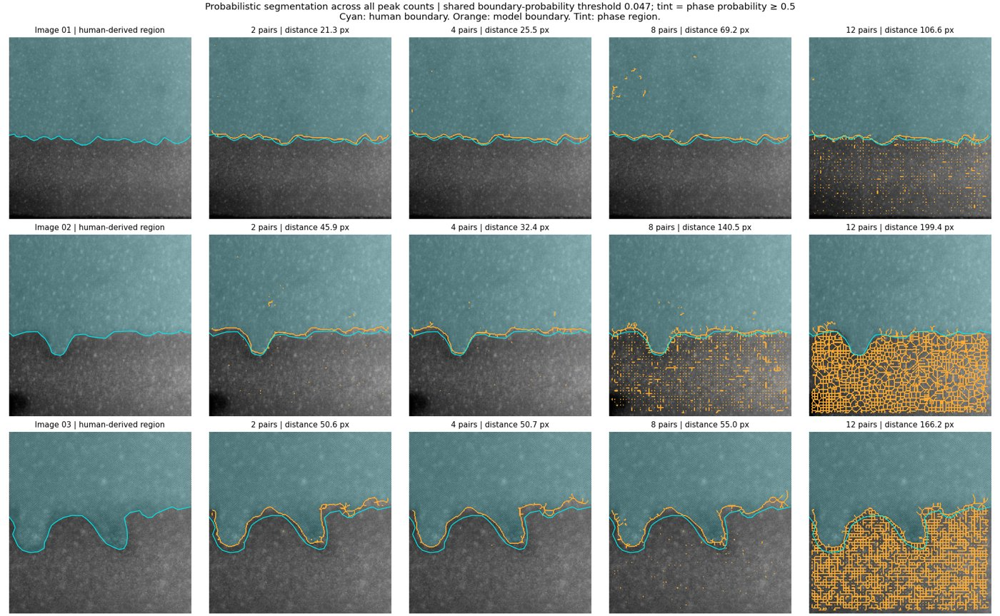

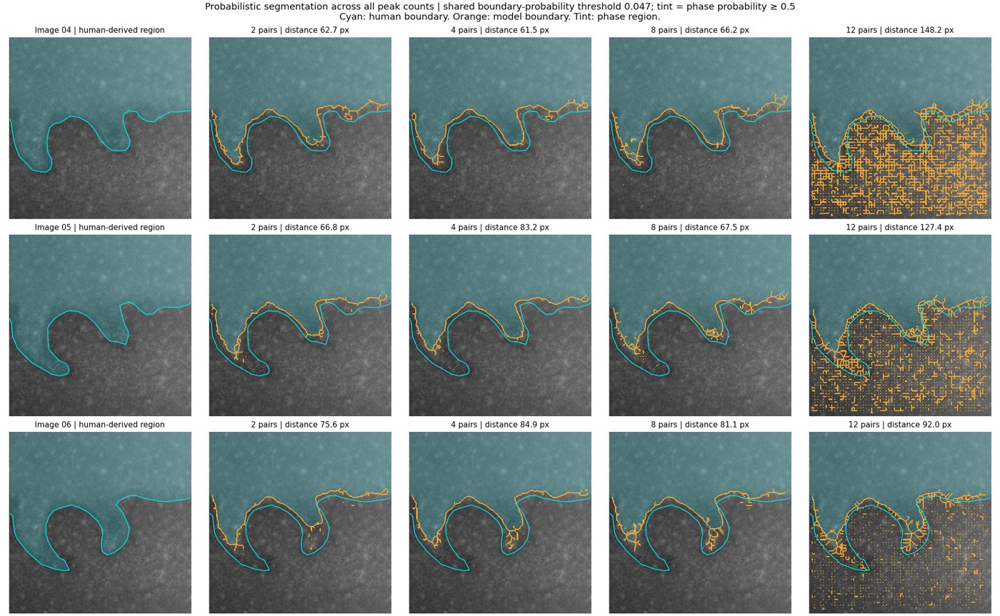

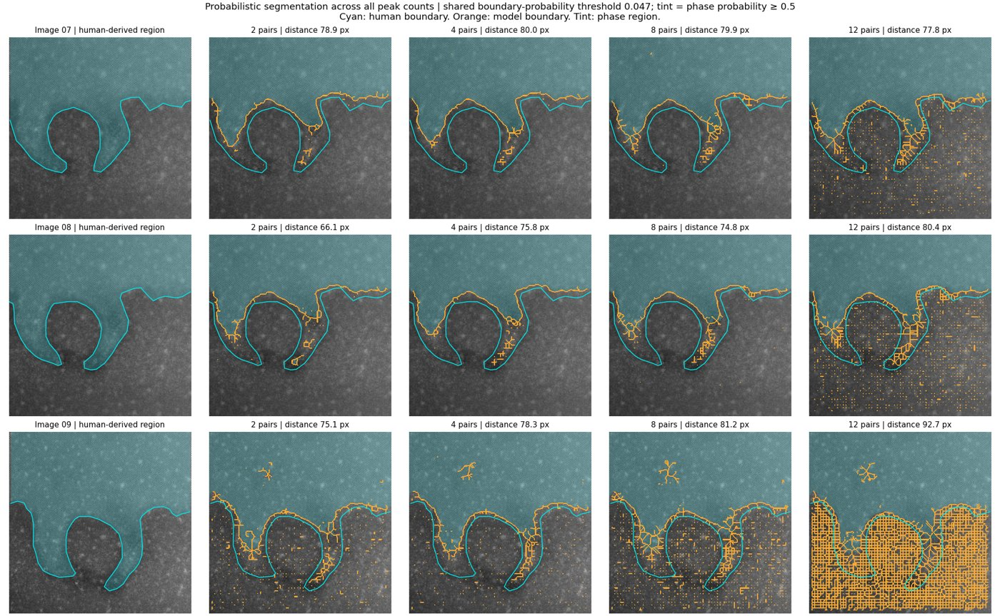

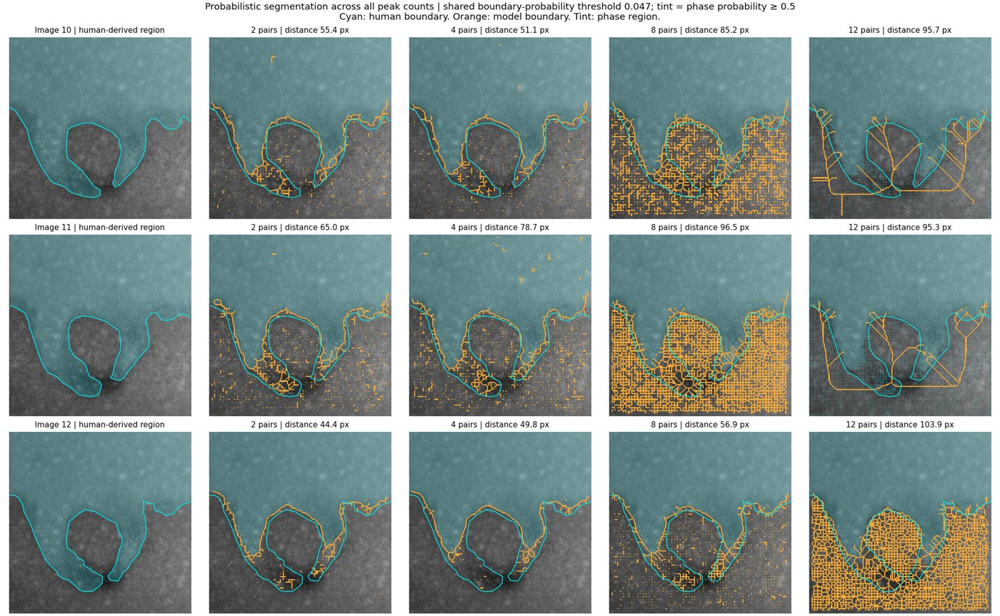

In [16]:
show_figures(segmentation_pages(records, deterministic_results, probabilistic_results,
                               series_selection, CFG, OUTPUT_DIR, "probabilistic"))

## 10. Physical fields for the globally selected model and the analysis dictionary

If the selected count differs from the reference count, its displacement/strain/rotation and SD maps are generated from its saved coefficient samples. The underlying reference gauge remains internal to each model; comparing absolute displacements across images would require an external reference.

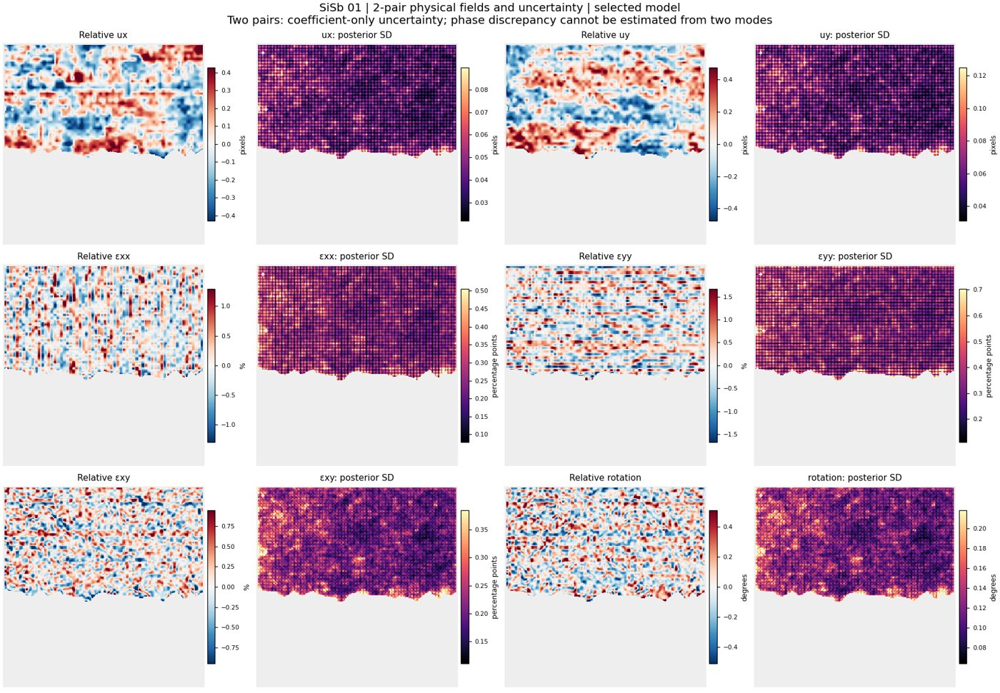

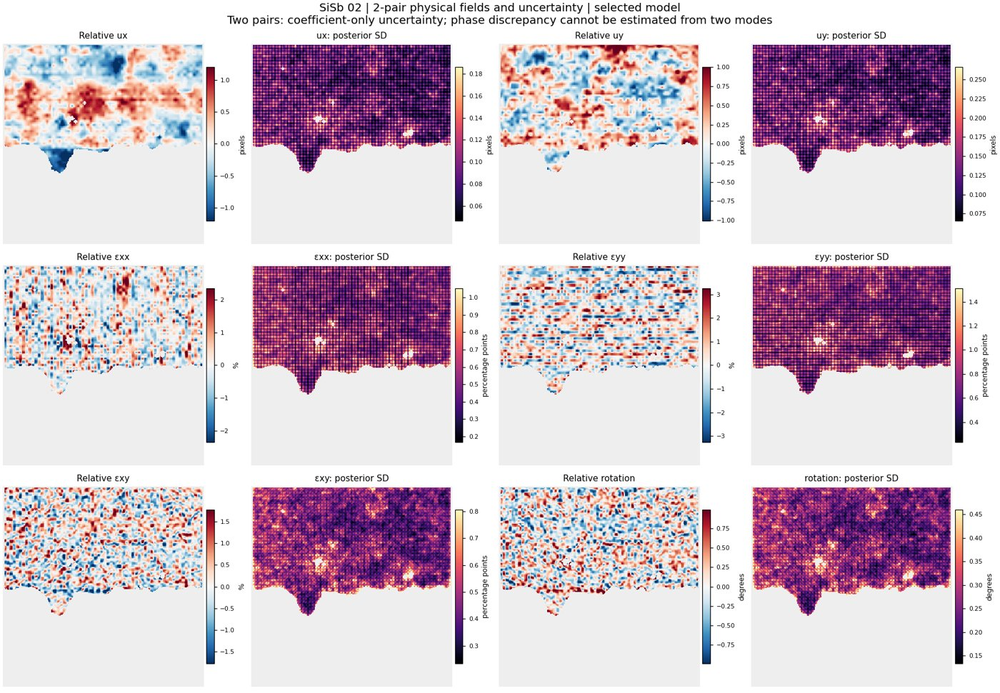

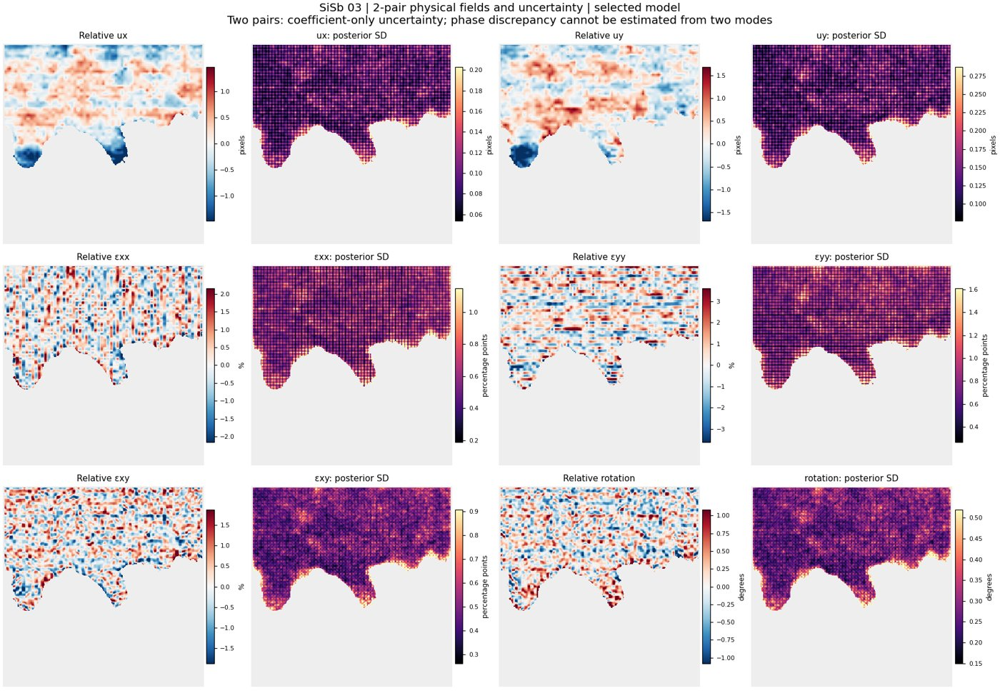

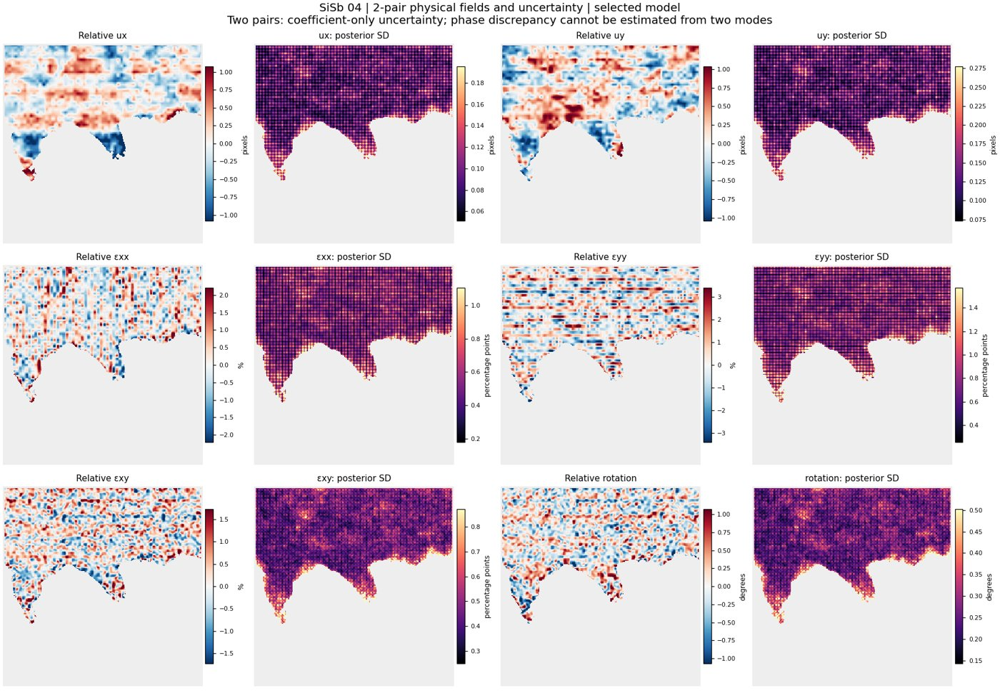

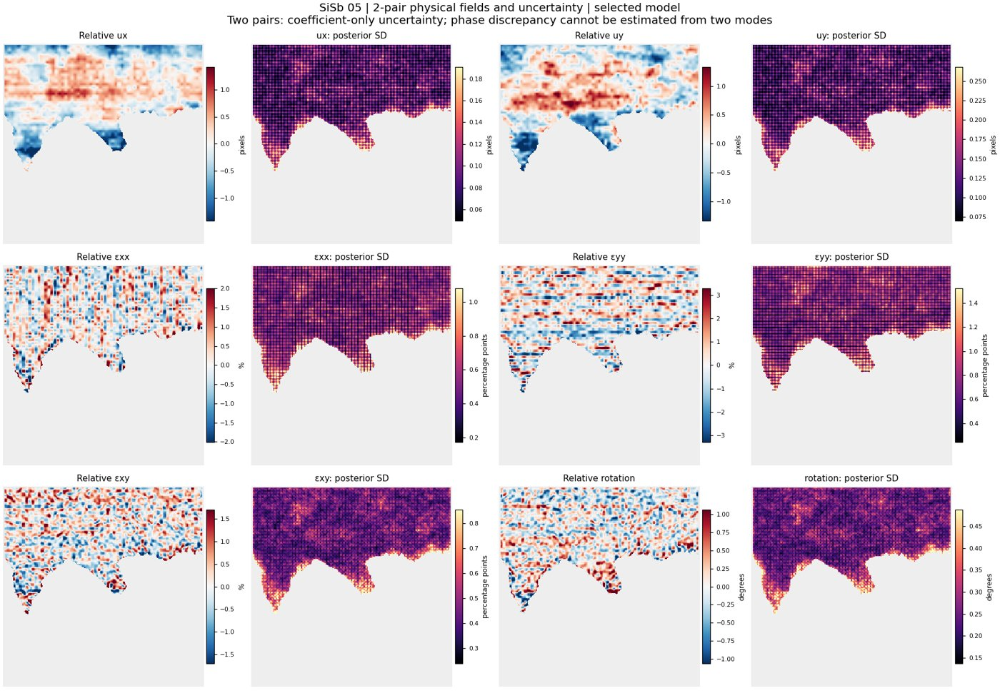

...

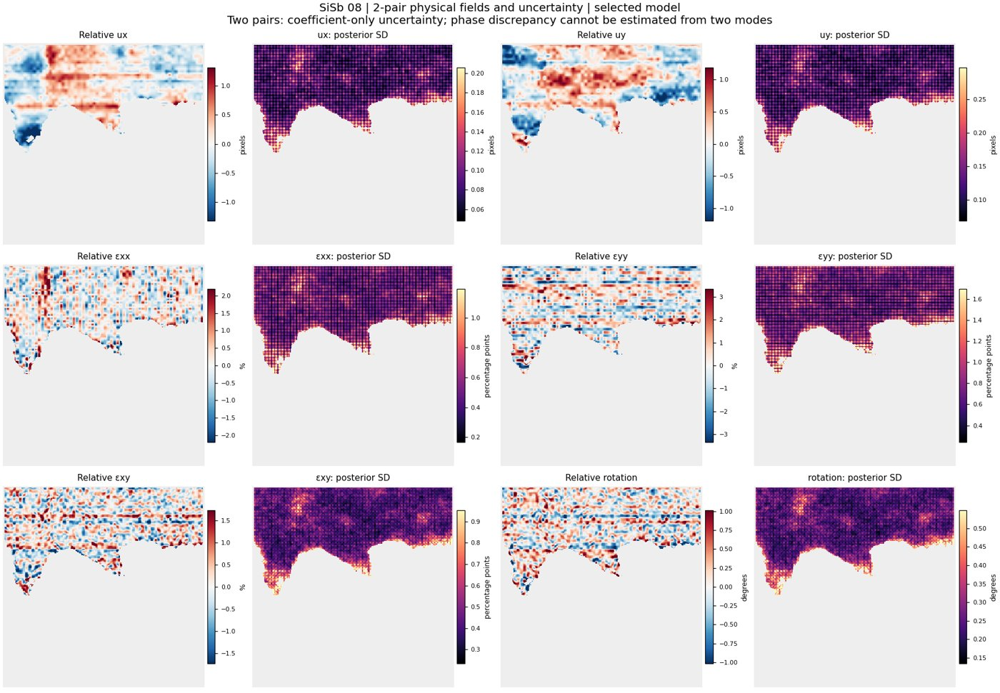

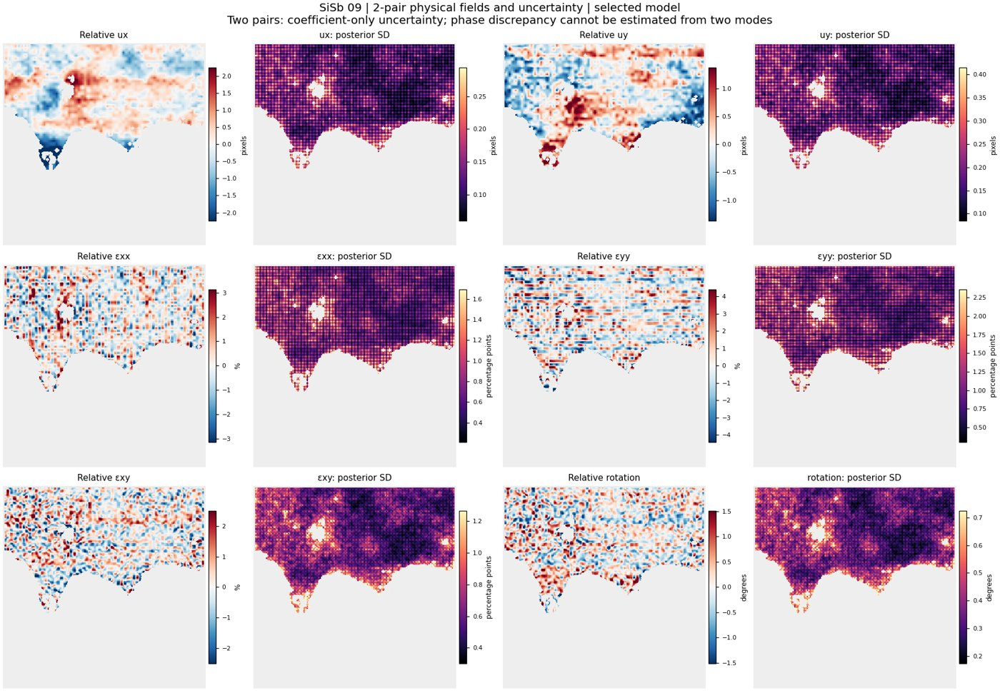

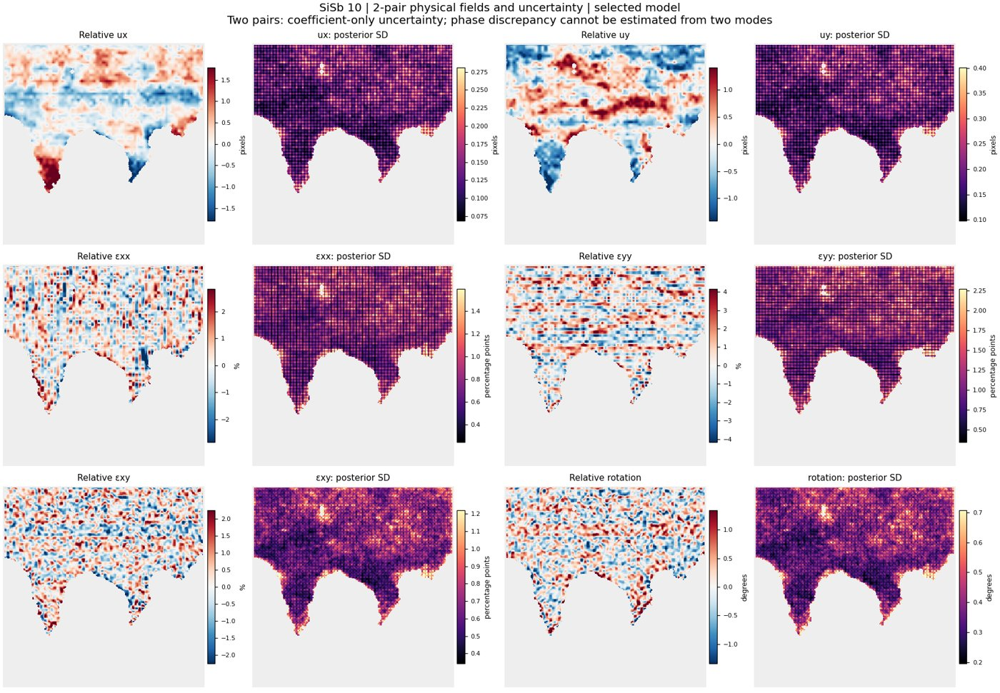

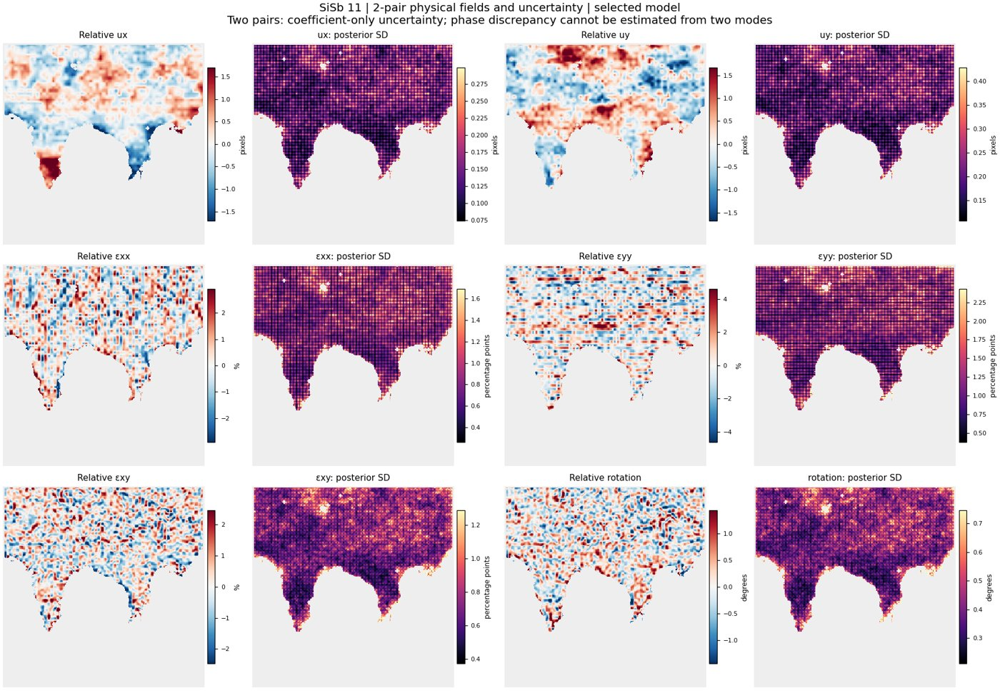

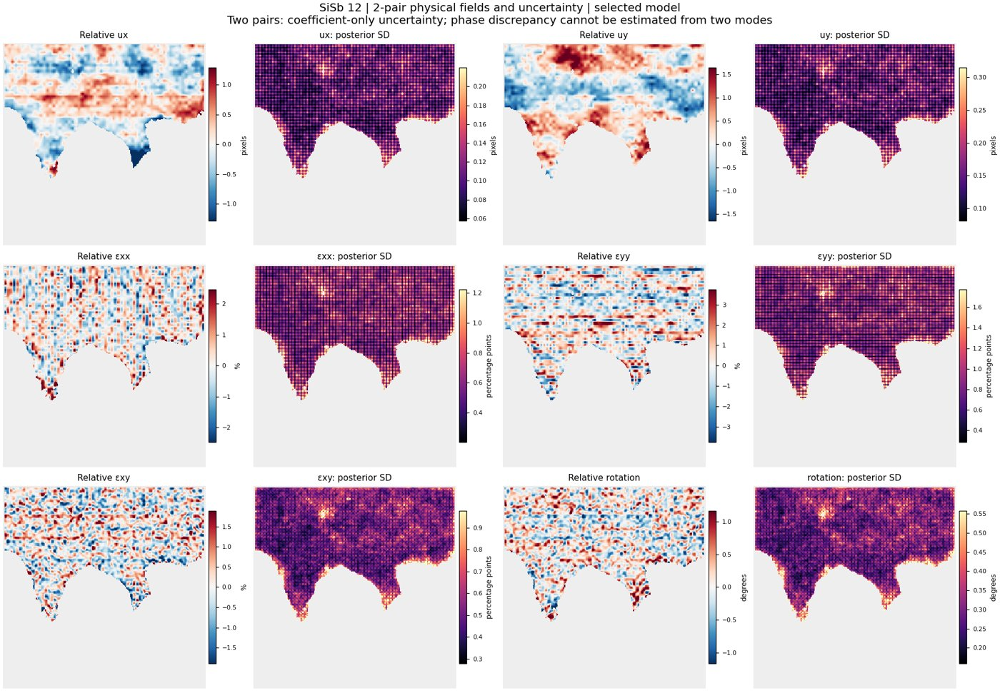

Image: 12 probability: (512, 512) boundary: (512, 512) bool
Available deterministic arrays: ['amplitude_2', 'phase_mask_2', 'edges_2', 'edges_native_2', 'amplitude_4', 'phase_mask_4', 'edges_4', 'edges_native_4', 'amplitude_8', 'phase_mask_8', 'edges_8', 'edges_native_8', 'amplitude_12', 'phase_mask_12', 'edges_12', 'edges_native_12', 'background', 'reconstruction', 'residual', 'log_fft', 'ux', 'uy', 'displacement_magnitude', 'epsilon_xx', 'epsilon_yy', 'epsilon_xy', 'rotation', 'phase_fit_rms', 'valid_core', 'mode_amplitude', 'mode_deformation_phase', 'mode_residual_phase', 'q_bins', 'human_boundary', 'human_points_xy', 'human_region', 'image_shape', 'field_step', 'boundary_step', 'output_map_step', 'crop_observed', 'crop_prediction', 'crop_xyxy']
Available chosen-model arrays: ['boundary_hits', 'boundary_probability', 'phase_probability', 'amplitude_mean', 'amplitude_std', 'mode_amplitude_scales', 'interior', 'edges', 'phase_mask', 'q_bins', 'image_shape', 'boundary_step', 'posterior

In [17]:
selected_field_paths = run_stage(
    records, lambda record: selected_physical_fields(record, probabilistic_results, series_selection, CFG, OUTPUT_DIR),
    workers=CFG["max_workers"])
json_write(OUTPUT_DIR / "selected_fields_index.json", selected_field_paths)

if series_selection["selected_bragg_pairs"] != max(CFG["peak_counts"]):
    for record in records:
        arrays = ArrayArchive(selected_field_paths[record["id"]])
        show_figures(physical_field_figure(record, arrays, series_selection["selected_bragg_pairs"],
                                          CFG, OUTPUT_DIR, "selected"))

all_results = analysis_dictionary(records, deterministic_results, probabilistic_results, series_selection, OUTPUT_DIR)
for image_id, path in selected_field_paths.items():
    all_results[image_id]["selected"]["physical_fields"] = ArrayArchive(path)

# Example dictionary access; arrays are loaded only when requested.
example_id = records[-1]["id"]
chosen_k = series_selection["selected_bragg_pairs"]
example_probability = all_results[example_id]["probabilistic"][chosen_k]["arrays"]["boundary_probability"]
example_edges = all_results[example_id]["selected"]["arrays"]["edges"]
example_ux = all_results[example_id]["selected"]["physical_fields"].get("physical_ux")
print("Image:", example_id, "probability:", example_probability.shape,
      "boundary:", example_edges.shape, example_edges.dtype)
print("Available deterministic arrays:", list(all_results[example_id]["deterministic"]["arrays"]))
print("Available chosen-model arrays:", list(all_results[example_id]["probabilistic"][chosen_k]["arrays"]))

## 11. Apply the selected parameters to another image

`detect_boundary(image)` retains the hackathon interface: it returns a Boolean boundary with the input image shape. It needs no human annotation. It selects FFT peaks, estimates the shared residual variance using the largest candidate model, then fits the globally selected model and propagates its uncertainty. Full-size probabilities are interpolated from the declared evaluation grid before thinning; this does not create new spatial resolution.

`detect_boundary.last_analysis` retains the probability maps, selected edges, coefficients, settings and predicted image from that call. The stored series outputs above remain unchanged.

In [18]:
def detect_boundary(image, peak_count=None, probability_threshold=None):
    image = np.asarray(image)
    k = series_selection["selected_bragg_pairs"] if peak_count is None else int(peak_count)
    threshold = (series_selection["selected_probability_threshold"]
                 if probability_threshold is None else float(probability_threshold))
    if k not in CFG["peak_counts"]:
        raise ValueError("Choose one of the configured peak counts.")
    deterministic = build_latent_field(image, n_modes=max(CFG["peak_counts"]),
        comparison_counts=CFG["peak_counts"], store_modes=False, amplitude_threshold=CFG["amplitude_cutoff"],
        phase_doubling=CFG["phase_doubling"])
    q = deterministic["q_latent"]
    if len(q) < max(CFG["peak_counts"]):
        raise ValueError("Not enough valid Bragg peaks for the configured comparison.")
    heights = np.array([m["fft_amplitude"] for m in deterministic["mode_summary"]])
    scales = .75 * np.maximum(heights / heights[:2].max(), .08)
    maximum = max(CFG["peak_counts"])
    pilot = ProbabilisticBraggField(image, q[:maximum], step=CFG["coefficient_step"],
        prior_scales=np.r_[2., scales[:maximum], scales[:maximum]], seed=CFG["seed"])
    pilot.prepare(np.ones(image.shape, bool))
    pilot.assemble(np.full(pilot.T, .8), training=False)
    pilot.fit()
    sigma = pilot.estimate_noise(pilot.predict())
    if k == maximum:
        model = pilot
    else:
        model = ProbabilisticBraggField(image, q[:k], step=CFG["coefficient_step"],
            prior_scales=np.r_[2., scales[:k], scales[:k]], seed=CFG["seed"])
        model.prepare(np.ones(image.shape, bool))
    model.assemble(sigma, training=False)
    model.fit()
    model.draw(n_samples=CFG["posterior_samples"], batch_size=CFG["draw_batch_size"])
    analysis = posterior_boundaries(model, CFG)
    yy, xx = np.mgrid[:image.shape[0], :image.shape[1]] / CFG["boundary_step"]
    full_probability = ndimage.map_coordinates(analysis["boundary_probability"], [yy, xx],
        order=1, mode="nearest", prefilter=False)
    boundary = skeletonize((full_probability >= threshold) & interior_mask(image.shape, 1, CFG["margin"]))
    analysis.update(edges=boundary.astype(bool), boundary_probability_native=full_probability,
        selected_bragg_pairs=k, selected_probability_threshold=threshold,
        coefficient_mean=model.mean, coefficient_samples=model.samples,
        prediction=model.predict()*model.scale+model.offset)
    detect_boundary.last_analysis = analysis
    return boundary.astype(bool)

# For an image already in memory:
# boundary = detect_boundary(my_image)
# result = detect_boundary.last_analysis

## 12. Summary and export

The final report separates the fitted series optimum, per-image optima, and leave-one-image-out checks. All computations use the direct geometric loss. The uncertainty is conditional, and threshold tuning can remove false edges while losing some true segments. Inspect the curves and overlays together with the mean distance.

The export contains every result array, figure, table, configuration and per-image summary. Large coefficient-sample checkpoints are retained locally and are optional in the ZIP; the notebook can regenerate them. Input EMD files are downloaded using the manifest and are not duplicated in the results ZIP. The notebook itself contains all model code and compact figure previews; the exported PNG figures retain their larger size.

In [19]:
summary_text = (
    f"Analyzed **{len(records)} images** with deterministic and probabilistic latent fields. "
    f"The shared setting is **{series_selection['selected_bragg_pairs']} Bragg pairs** and "
    f"**probability threshold {series_selection['selected_probability_threshold']:.4f}**. "
    f"Its mean symmetric boundary distance is **{series_selection['mean_distance_px']:.2f} pixels**. "
    f"The deterministic method at the same peak count gives "
    f"**{series_selection['mean_deterministic_distance_px']:.2f} pixels**. "
)
if series_selection["mean_loo_distance_px"] is not None:
    summary_text += f"Leave-one-image-out selection gives **{series_selection['mean_loo_distance_px']:.2f} pixels** mean held-out distance."
alternatives = best_by_count[best_by_count["bragg_pairs"] != series_selection["selected_bragg_pairs"]]
if len(alternatives):
    runner_up = alternatives.sort_values("mean_distance_px").iloc[0]
    gap = float(runner_up["mean_distance_px"] - series_selection["mean_distance_px"])
    summary_text += (f" The best other peak count is **{int(runner_up['bragg_pairs'])} pairs**, "
                     f"at threshold **{runner_up['threshold']:.4f}**, with mean distance "
                     f"**{runner_up['mean_distance_px']:.2f} pixels** (gap **{gap:.2f} pixels**).")
    if gap < 1.0:
        summary_text += " This is a near-tie under the selected loss, so the numerical winner should not be read as a strong model preference."
display(Markdown(summary_text))

field_summary_rows = []
for record in records:
    i = record["id"]
    arrays = all_results[i]["selected"]["physical_fields"]
    row = dict(image=i, bragg_pairs=series_selection["selected_bragg_pairs"])
    for name in ["ux_std", "uy_std", "epsilon_xx_std", "epsilon_yy_std", "epsilon_xy_std", "rotation_std", "phase_compatibility_rms"]:
        key = "physical_" + name
        row["median_" + name] = float(np.nanmedian(arrays[key])) if key in arrays else np.nan
    field_summary_rows.append(row)
field_uncertainty_summary = pd.DataFrame(field_summary_rows)
field_uncertainty_summary.to_csv(OUTPUT_DIR / "selected_field_uncertainty_summary.csv", index=False)
display(field_uncertainty_summary.round(5))

import zipfile
EXPORT_RESULTS = True
INCLUDE_COEFFICIENT_SAMPLES_IN_ZIP = False
if EXPORT_RESULTS:
    archive_path = OUTPUT_DIR.parent / f"Day_16_Latent_Field_Series_results_{run_signature}.zip"
    temporary_archive = archive_path.with_suffix(".tmp.zip")
    with zipfile.ZipFile(temporary_archive, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=3) as archive:
        for path in sorted(OUTPUT_DIR.rglob("*")):
            if not path.is_file() or path.name.endswith(".tmp"):
                continue
            if path.name.startswith("coefficients_") and not INCLUDE_COEFFICIENT_SAMPLES_IN_ZIP:
                continue
            archive.write(path, arcname=Path(OUTPUT_DIR.name) / path.relative_to(OUTPUT_DIR))
    with temporary_archive.open("rb") as handle:
        os.fsync(handle.fileno())
    temporary_archive.replace(archive_path)
    print("Results archive:", archive_path)
    print("Archive size (MiB):", round(archive_path.stat().st_size / 1024**2, 1))
    # In Colab, uncomment to download the archive:
    # from google.colab import files
    # files.download(str(archive_path))

Analyzed **12 images** with deterministic and probabilistic latent fields. The shared setting is **2 Bragg pairs** and **probability threshold 0.0469**. Its mean symmetric boundary distance is **58.99 pixels**. The deterministic method at the same peak count gives **66.79 pixels**. Leave-one-image-out selection gives **66.96 pixels** mean held-out distance. The best other peak count is **12 pairs**, at threshold **0.8750**, with mean distance **59.19 pixels** (gap **0.20 pixels**). This is a near-tie under the selected loss, so the numerical winner should not be read as a strong model preference.

,image,bragg_pairs,median_ux_std,median_uy_std,median_epsilon_xx_std,median_epsilon_yy_std,median_epsilon_xy_std,median_rotation_std,median_phase_compatibility_rms
0,01,2,0.03998,0.05583,0.00234,0.00327,0.00206,0.00207,0.0
1,02,2,0.08469,0.11975,0.00495,0.00704,0.00440,0.00441,0.0
2,03,2,0.09260,0.13106,0.00541,0.00758,0.00473,0.00473,0.0
3,04,2,0.08830,0.12565,0.00511,0.00725,0.00453,0.00453,0.0
4,05,2,0.08512,0.12001,0.00494,0.00693,0.00432,0.00431,0.0
5,06,2,0.08322,0.11801,0.00480,0.00683,0.00424,0.00423,0.0
6,07,2,0.08340,0.11759,0.00482,0.00675,0.00424,0.00423,0.0
7,08,2,0.08464,0.12024,0.00485,0.00695,0.00429,0.00429,0.0
8,09,2,0.12019,0.16947,0.00682,0.00966,0.00614,0.00615,0.0
9,10,2,0.12700,0.18104,0.00731,0.01045,0.00649,0.00651,0.0


Results archive: /content/series_analysis/Day_16_Latent_Field_Series_results_752e56e0117b.zip
Archive size (MiB): 638.3


## Interpretation and practical limits

- The Gaussian posterior describes uncertainty under the chosen model. It does not marginalize over FFT peaks, priors, residual-noise estimates, grid spacing or the amplitude cutoff. Probability calibration against human annotations is not claimed.
- Field reference planes are fitted internally. Deformation fields are relative; absolute strain or comparisons between frames require an independently defined reference lattice and registration.
- The deterministic and probabilistic models use different spatial estimators. They share the measured peak list and amplitude criterion, but the comparison is not solely a change from “no uncertainty” to “uncertainty.”
- Residual phase incompatibility limits interpreting all Fourier modes as one physical displacement. For two modes, that incompatibility has no residual degrees of freedom and its uncertainty cannot be inferred here.
- The coefficient grid can introduce spatial modulation of uncertainty in weakly ordered regions. Boundary threshold selection does not eliminate the underlying representation limitation.
- Symmetric mean distance is the chosen objective. It can trade improved precision against reduced recall, and it does not enforce a single connected interface or correct topology. Native and grid-evaluated boundaries can differ by a few pixels.
- The globally selected parameters optimize these annotated images. Leave-one-image-out selection is a useful check, but correlated frames and a single human interpretation limit generalization claims.
- If all distances are infinite for a candidate it cannot win. If any image/model fails, the notebook stops before selection so missing cases cannot bias the aggregate.

Original data: [ATHENA/CAMM Day 16 hackathon repository](https://github.com/kbarakati/athena_camm_hackathon/tree/k4my4r/docs/day_16_11092026). Gaussian precision sampling reference: [Papandreou and Yuille, Gaussian Sampling by Local Perturbations (2010)](https://proceedings.neurips.cc/paper/2010/hash/d09bf41544a3365a46c9077ebb5e35c3-Abstract.html). This notebook's numerical comparisons are computed directly from the supplied images and annotations.